# 뉴욕 맨해튼 임대료 예측 모델 구축

> **이 매물의 월세는 왜 이 가격인가, 그리고 우리는 그 답을 얼마나 믿을 수 있는가?**

**원본 작성자:** 성지혜 | **원본 작성일:** 2026-09-08

## #1. 분석 개요

**분석 주제**

StreetEasy 임대 매물의 주거 특성·편의시설·동네 정보를 이용해 월 임대료(`rent`)를 설명, (데이터 품질 점검 - 탐색적 분석 - 전처리 - 모델링 - 튜닝 - 모형 진단 - 해석)의 흐름으로 결과와 한계를 정리한다.

**분석 목적**
- "모델이 내놓은 숫자에 책임질 수 있는 근거를 남기는 것"

**분석 질문**

- **Q1.** 면적·공간 구성·편의시설은 임대료와 어떤 관계가 있는가?
- **Q2.** 동네별 임대료 차이가 있으며, 이를 소수 권역으로 요약할 수 있는가?
- **Q3.** 기준선·공선성 제거·이상치 대체 중 어떤 설정의 오차가 작은가?
- **Q4.** 변수 제거가 성능과 해석에 어떤 영향을 주는가?
- **Q5.** 최종 모형을 개별 매물의 가격 설명에 어디까지 사용할 수 있는가?

#### 1-1. 분석 환경 설정

> 분석에 필요한 개별 함수 **import**

In [1]:
from hossam import load_data
from helpers import *
from IPython.display import display, Markdown

## 노트북에서 직접 호출하지는 않지만, 분석 환경(버전) 확인용으로 함께 참조한다.
import pandas as pd
import numpy as np
import statsmodels.api as sm

📦 아이티윌 이광호 강사가 제작한 라이브러리를 사용중입니다.
📚 자세한 사용 방법은 https://py.hossam.kr 을 참고하세요.
📧 Email: leekh4232@gmail.com
🎬 Youtube: https://www.youtube.com/@hossam-codingclub
📝 Blog: https://blog.hossam.kr/
🔖 Version: 0.5.33


---
## #2. 데이터 소개

#### 2-1. 데이터 로딩

In [2]:
origin = load_data("streeteasy")
origin.head()

📚 StreetEasy는 뉴욕시 최고의 부동산 마켓플레이스입니다. 여러분은 맨해튼의 임대 매물 5,000건을 표본으로 하는 데이터셋을 다루게 될 것입니다. (출처: https://www.kaggle.com/datasets/zohaib30/streeteasy-dataset)

    field             description
--  ----------------  -------------------------------------------------------------------------------------------------------------------
 0  rent              월 임대료(USD) — 연속형, 회귀 분석의 종속변수(타깃). 범위 1,300~20,000, 평균 약 5,139
 1  bedrooms          침실 수 — 이산 수치형(순서형). 0.5 단위 10개 값(0~5), 0은 스튜디오(원룸), 0.5는 침실 분리형 원룸
 2  bathrooms         욕실 수 — 이산 수치형(순서형). 0~5의 정수, 0은 독립 욕실 없음
 3  size_sqft         전용 면적(제곱피트, 1sqft≈0.028평) — 연속형. 범위 250~4,800, 임대료와 상관이 가장 높은 변수
 4  min_to_subway     가장 가까운 지하철역까지 도보 소요 시간(분) — 연속형. 범위 0~43, 값이 작을수록 역세권
 5  floor             매물이 위치한 층 — 이산 수치형. 0~83층, 0.5는 중층(메자닌), 0은 지상·반지하층
 6  building_age_yrs  건물 준공 후 경과 연수(년) — 연속형. 범위 0~180, 0은 신축
 7  no_fee            중개 수수료 없는 매물 여부 — 이진 범주형(1=수수료 없음, 0=수수료 있음)
 8  has_roofdeck      옥상 데크(루프덱) 보유 여부 — 이진 범주형(1=보유, 0=미보유)
 9  has_wa

,rent,bedrooms,bathrooms,size_sqft,min_to_subway,floor,building_age_yrs,no_fee,has_roofdeck,has_washer_dryer,has_doorman,has_elevator,has_dishwasher,has_patio,has_gym,neighborhood,borough
0,2550,0.000,1,480,9,2.000,17,1,1,0,0,1,1,0,1,Upper East Side,Manhattan
1,11500,2.000,2,2000,4,1.000,96,0,0,0,0,0,0,0,0,Greenwich Village,Manhattan
2,4500,1.000,1,916,2,51.000,29,0,1,0,1,1,1,0,0,Midtown,Manhattan
3,4795,1.000,1,975,3,8.000,31,0,0,0,1,1,1,0,1,Greenwich Village,Manhattan
4,17500,2.000,2,4800,3,4.000,136,0,0,0,1,1,1,0,1,Soho,Manhattan


**해석**

- **출처:** 로더에 표시된 Kaggle의 StreetEasy 재배포 데이터. 원본에 기재된 출처는 `https://www.kaggle.com/datasets/zohaib30/streeteasy-dataset`이다.

#### 2-2. 변수 정의서

| 변수 | 의미·단위 | 분석 역할 |
|---|---|---|
| `rent` | 월 임대료, USD/월 | 수치형 타깃 |
| `bedrooms`, `bathrooms` | 침실 수, 욕실 수 | 수치형 설명변수 |
| `size_sqft` | 면적, sqft | 수치형 설명변수 |
| `min_to_subway` | 지하철역까지 도보 시간, 분 | 수치형 설명변수 |
| `floor` | 매물 층수 | 수치형 설명변수 |
| `building_age_yrs` | 건물 경과 연수, 년 | 수치형 설명변수 |
| `no_fee` | 수수료 없음 여부 | 이진 범주형 |
| `has_roofdeck`, `has_washer_dryer` | 루프덱, 세탁기·건조기 보유 여부 | 이진 범주형 |
| `has_doorman`, `has_elevator` | 도어맨, 엘리베이터 여부 | 이진 범주형 |
| `has_dishwasher`, `has_patio`, `has_gym` | 식기세척기, 파티오, 헬스장 여부 | 이진 범주형 |
| `neighborhood` | 동네명, 32개 수준 | 명목형 설명변수 |
| `borough` | 자치구, 표본에서 Manhattan으로 동일 | 제외 대상 |

#### 2-3. 초기 가설

- **H1.** 면적·침실 수·욕실 수가 클수록 임대료가 높을 것이다.
- **H2.** 지하철 도보 시간이 길거나 건물이 오래될수록 임대료가 낮을 것이다.
- **H3.** 편의시설 보유 여부에 따라 임대료에 차이가 있을 것이다.
- **H4.** 동네에 따라 평균 임대료가 다를 것이다.

---
## #3. 품질 점검 및 기본 전처리

> 이 장에서는 **삭제만** 수행한다. 결측치·이상치의 **대체는 #6**의 전처리 파이프라인에서 한다.
> 전처리 기준이 분석 설계보다 앞서면 판단 근거가 사라지기 때문이다.

#### 3-1. 데이터 구조 확인

> 행 수, 자료형, 결측 여부를 `info()`로 확인한다.

> `borough` 변수는 Manhattan으로 전 행이 동일하므로 분석대상에서 제외한다.

##### 1) 자료형 확인

In [3]:
origin.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3539 entries, 0 to 3538
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   rent              3539 non-null   int64  
 1   bedrooms          3539 non-null   float64
 2   bathrooms         3539 non-null   int64  
 3   size_sqft         3539 non-null   int64  
 4   min_to_subway     3539 non-null   int64  
 5   floor             3539 non-null   float64
 6   building_age_yrs  3539 non-null   int64  
 7   no_fee            3539 non-null   int64  
 8   has_roofdeck      3539 non-null   int64  
 9   has_washer_dryer  3539 non-null   int64  
 10  has_doorman       3539 non-null   int64  
 11  has_elevator      3539 non-null   int64  
 12  has_dishwasher    3539 non-null   int64  
 13  has_patio         3539 non-null   int64  
 14  has_gym           3539 non-null   int64  
 15  neighborhood      3539 non-null   object 
 16  borough           3539 non-null   object 


##### 2) 자료형 변환

- `no_fee` 부터 `has_gym` 까지 여덟 개 변수는 0과 1 두 값뿐이며 숫자로 저장되어 있지만 이 값들의 평균은 “비율”일 뿐이라 중심이나 꼬리를 논할 대상이 아니다. 연속형 통계에 섞여 들어가지 않도록 시작할 때 범주형으로 변환한다
- `neighborhood` 변수는 동네명 설명변수이므로 명목형으로 변환한다

In [4]:
df1 = my_qtcheck.set_type(origin, as_category=['no_fee', 'has_roofdeck', 'has_washer_dryer', 'has_doorman',
                                               'has_elevator', 'has_dishwasher', 'has_patio', 'has_gym', 'neighborhood'])
df1.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3539 entries, 0 to 3538
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   rent              3539 non-null   int64   
 1   bedrooms          3539 non-null   float64 
 2   bathrooms         3539 non-null   int64   
 3   size_sqft         3539 non-null   int64   
 4   min_to_subway     3539 non-null   int64   
 5   floor             3539 non-null   float64 
 6   building_age_yrs  3539 non-null   int64   
 7   no_fee            3539 non-null   category
 8   has_roofdeck      3539 non-null   category
 9   has_washer_dryer  3539 non-null   category
 10  has_doorman       3539 non-null   category
 11  has_elevator      3539 non-null   category
 12  has_dishwasher    3539 non-null   category
 13  has_patio         3539 non-null   category
 14  has_gym           3539 non-null   category
 15  neighborhood      3539 non-null   category
 16  borough           3539 n

,rent,bedrooms,bathrooms,size_sqft,min_to_subway,floor,building_age_yrs,no_fee,has_roofdeck,has_washer_dryer,has_doorman,has_elevator,has_dishwasher,has_patio,has_gym,neighborhood,borough
0,2550,0.000,1,480,9,2.000,17,1,1,0,0,1,1,0,1,Upper East Side,Manhattan
1,11500,2.000,2,2000,4,1.000,96,0,0,0,0,0,0,0,0,Greenwich Village,Manhattan
2,4500,1.000,1,916,2,51.000,29,0,1,0,1,1,1,0,0,Midtown,Manhattan
3,4795,1.000,1,975,3,8.000,31,0,0,0,1,1,1,0,1,Greenwich Village,Manhattan
4,17500,2.000,2,4800,3,4.000,136,0,0,0,1,1,1,0,1,Soho,Manhattan


##### 3) 중복 검사 및 중복 데이터 삭제
- `borough` 컬럼은 Manhattan으로 동일하므로 제외한다
- 중복행 27개를 삭제한다

In [5]:
df2 = my_qtcheck.check_duplicates(df1)
df2.head()

중복된 행의 수: 27
중복된 행이 제거되었습니다.


,rent,bedrooms,bathrooms,size_sqft,min_to_subway,floor,building_age_yrs,no_fee,has_roofdeck,has_washer_dryer,has_doorman,has_elevator,has_dishwasher,has_patio,has_gym,neighborhood,borough
0,2550,0.000,1,480,9,2.000,17,1,1,0,0,1,1,0,1,Upper East Side,Manhattan
1,11500,2.000,2,2000,4,1.000,96,0,0,0,0,0,0,0,0,Greenwich Village,Manhattan
2,4500,1.000,1,916,2,51.000,29,0,1,0,1,1,1,0,0,Midtown,Manhattan
3,4795,1.000,1,975,3,8.000,31,0,0,0,1,1,1,0,1,Greenwich Village,Manhattan
4,17500,2.000,2,4800,3,4.000,136,0,0,0,1,1,1,0,1,Soho,Manhattan


In [6]:
df2 = df2.drop(columns=["borough"])
df2.head()

,rent,bedrooms,bathrooms,size_sqft,min_to_subway,floor,building_age_yrs,no_fee,has_roofdeck,has_washer_dryer,has_doorman,has_elevator,has_dishwasher,has_patio,has_gym,neighborhood
0,2550,0.000,1,480,9,2.000,17,1,1,0,0,1,1,0,1,Upper East Side
1,11500,2.000,2,2000,4,1.000,96,0,0,0,0,0,0,0,0,Greenwich Village
2,4500,1.000,1,916,2,51.000,29,0,1,0,1,1,1,0,0,Midtown
3,4795,1.000,1,975,3,8.000,31,0,0,0,1,1,1,0,1,Greenwich Village
4,17500,2.000,2,4800,3,4.000,136,0,0,0,1,1,1,0,1,Soho


**해석**

- **자료형:** `no_fee`, `has_roofdeck`, `has_washer_dryer`, `has_doorman`, `has_elevator`, `has_dishwasher`, `has_patio`, `has_gym` 8개의 변수는 비율이므로 범주형으로 변환, 
    - `neighborhood` 변수는 object → category 형식으로 변환한다
- **중복 행:** **27건** — 삭제 
- **불필요한 열:** `info()` 로 확인한 결과 `borough`은 맨해튼으로 전 행이 동일하며 분석대상이 아니므로 **삭제한다.** 나머지 변수는 실측값이므로 유지한다.

#### 3-2. 데이터 품질 점검

##### 1) 결측치 확인

In [7]:
my_qtcheck.check_missing_values(df2)

,Missing Count,Missing Ratio (%)
rent,0,0.000
bedrooms,0,0.000
bathrooms,0,0.000
size_sqft,0,0.000
min_to_subway,0,0.000
floor,0,0.000
building_age_yrs,0,0.000
no_fee,0,0.000
has_roofdeck,0,0.000
has_washer_dryer,0,0.000


In [8]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3512 entries, 0 to 3538
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   rent              3512 non-null   int64   
 1   bedrooms          3512 non-null   float64 
 2   bathrooms         3512 non-null   int64   
 3   size_sqft         3512 non-null   int64   
 4   min_to_subway     3512 non-null   int64   
 5   floor             3512 non-null   float64 
 6   building_age_yrs  3512 non-null   int64   
 7   no_fee            3512 non-null   category
 8   has_roofdeck      3512 non-null   category
 9   has_washer_dryer  3512 non-null   category
 10  has_doorman       3512 non-null   category
 11  has_elevator      3512 non-null   category
 12  has_dishwasher    3512 non-null   category
 13  has_patio         3512 non-null   category
 14  has_gym           3512 non-null   category
 15  neighborhood      3512 non-null   category
dtypes: category(9), float64(2), i

1-2) 명목형 수준별 빈도표 확인

In [9]:
# 명목형 컬럼 나열
cat_cols = [
    "no_fee", "has_roofdeck", "has_washer_dryer",
    "has_doorman", "has_elevator", "has_dishwasher",
    "has_patio", "has_gym", "neighborhood"
]

tables = []

for col in cat_cols:
    counts = df2[col].value_counts()

    table = counts.rename_axis("level").reset_index(name="count")
    table.insert(0, "variable", col)
    table["ratio_pct"] = (table["count"] / len(df2) * 100).round(2)

    tables.append(table)

freq_table = pd.concat(tables, ignore_index=True)

display(freq_table)

,variable,level,count,ratio_pct
0,no_fee,0,2091,59.540
1,no_fee,1,1421,40.460
2,has_roofdeck,0,2967,84.480
3,has_roofdeck,1,545,15.520
4,has_washer_dryer,0,2947,83.910
5,has_washer_dryer,1,565,16.090
6,has_doorman,0,2529,72.010
7,has_doorman,1,983,27.990
8,has_elevator,0,2479,70.590
9,has_elevator,1,1033,29.410


### 발견사항 목록, 미션 1

> “이 표본은 무엇을 담고 있나?”

- **행·열 및 자료형:** 중복 행과 `borough`를 제외한 데이터는 **3,512행·16열**이며, 자료형은 정수형 5개, 실수형 2개, 범주형 9개이다.
- **중복 행:** 완전히 동일한 행 **27건을 삭제**하여 3,539행에서 3,512행으로 줄었다.
- **결측치:** 모든 열의 비결측값이 **3,512개**로, 결측치는 없다.
- **수치형 변수의 범위:** 임대료 1,300~20,000달러, 침실·욕실 수 0~5개, 면적 250~4,800sqft, 지하철 도보 시간 0~43분, 층수 0~83층, 건물 연수 0~180년이다. 범위만으로 값의 정확성을 확정하지는 않는다.
- **0으로 기록된 값:** 제공된 변수 정의에서 침실·욕실·층수·건물 연수의 0은 각각 스튜디오, 독립 욕실 없음, 지상·반지하층, 신축을 의미한다.
- **명목형 변수의 수준과 편중:** 기존 자료에서 `neighborhood`는 32개 동네로 확인되었으며, 중복 제거 후 빈도표에서 수준 수와 편중을 확인한다. `borough`는 모든 행이 Manhattan으로 동일하여 삭제하였다.

##### 2) 이상치 확인 (IQR 기준)

`numerical_summary()` 는 기술통계량과 함께 **IQR × 1.5 경계**를 벗어난 이상치의 개수·비율을 계산한다.

In [10]:
num_desc = my_qtcheck.numerical_summary(df2)
num_desc

,count,mean,std,min,25%,50%,75%,max,rel_diff,rdiff_flag,iqr,upper_bound,lower_bound,upper_outliers,upper_outliers_ratio,lower_outliers,lower_outliers_ratio,outliers,outliers_ratio,skew,skew_interpret,kurt,kurt_interpret,log_need
rent,3512.000,5142.887,3157.513,1300.000,3169.250,4000.000,6000.000,20000.000,0.286,diff,2830.750,10246.125,-1076.875,271,0.077,0,0.000,271,0.077,1.986,right_tail,4.343,leptokurtic,log1p
bedrooms,3512.000,1.354,0.968,0.000,1.000,1.000,2.000,5.000,0.354,diff,1.000,3.500,-0.500,82,0.023,0,0.000,82,0.023,0.575,right_tail,0.159,leptokurtic,log1p
bathrooms,3512.000,1.367,0.600,0.000,1.000,1.000,2.000,5.000,0.367,diff,1.000,3.500,-0.500,15,0.004,0,0.000,15,0.004,1.502,right_tail,2.194,leptokurtic,log1p
size_sqft,3512.000,940.287,478.290,250.000,615.000,800.000,1141.500,4800.000,0.175,diff,526.500,1931.250,-174.750,179,0.051,0,0.000,179,0.051,1.752,right_tail,4.430,leptokurtic,log1p
min_to_subway,3512.000,4.965,5.489,0.000,2.000,4.000,6.000,43.000,0.241,diff,4.000,12.000,-4.000,118,0.034,0,0.000,118,0.034,4.852,right_tail,30.216,leptokurtic,log1p
floor,3512.000,11.887,10.928,0.000,4.000,8.000,17.000,83.000,0.486,diff,13.000,36.500,-15.500,144,0.041,0,0.000,144,0.041,1.711,right_tail,3.697,leptokurtic,log1p
building_age_yrs,3512.000,51.958,39.420,0.000,15.000,39.000,90.000,180.000,0.332,diff,75.000,202.500,-97.500,0,0.000,0,0.000,0,0.000,0.420,symmetric,-1.174,platykurtic,none


**해석**

| 변수 | mean | 50% | min | max | outliers | skew | skew_interpret |
|---|---:|---:|---:|---:|---:|---:|---|
| rent | 5142.887 | 4000.000 | 1300.000 | 20000.000 | 271 | 1.986 | right_tail |
| bedrooms | 1.354 | 1.000 | 0.000 | 5.000 | 82 | 0.575 | right_tail |
| bathrooms | 1.367 | 1.000 | 0.000 | 5.000 | 15 | 1.502 | right_tail |
| size_sqft | 940.287 | 800.000 | 250.000 | 4800.000 | 179 | 1.752 | right_tail |
| min_to_subway | 4.965 | 4.000 | 0.000 | 43.000 | 118 | 4.852 | right_tail |
| floor | 11.887 | 8.000 | 0.000 | 83.000 | 144 | 1.711 | right_tail |
| building_age_yrs | 51.958 | 39.000 | 0.000 | 180.000 | 0 | 0.420 | symmetric |

- `rent(임대료)`는 평균이 **5,142.887달러**로 중앙값 **4,000달러**보다 약 **28.6% 높으며**, 오른쪽 꼬리가 긴 분포를 보인다.
- `min_to_subway(지하철 도보 시간)`은 왜도가 **4.852로 가장 높아**, 일부 매물은 다른 매물보다 지하철역까지 걸리는 시간이 훨씬 길다.
- `rent(임대료)`는 IQR 기준 상단 경계인 **10,246.125달러를 초과하는 매물이 271건** 확인되었지만, 실제 고가 매물일 수 있으므로 잘못된 값이라고 단정할 수는 없다.

#### 3-3. 기술통계량

##### 1) 연속형 변수의 기술 통계량을 전치 형태로 출력

In [11]:
num_desc.T

,rent,bedrooms,bathrooms,size_sqft,min_to_subway,floor,building_age_yrs
count,3512.000,3512.000,3512.000,3512.000,3512.000,3512.000,3512.000
mean,5142.887,1.354,1.367,940.287,4.965,11.887,51.958
std,3157.513,0.968,0.600,478.290,5.489,10.928,39.420
min,1300.000,0.000,0.000,250.000,0.000,0.000,0.000
25%,3169.250,1.000,1.000,615.000,2.000,4.000,15.000
50%,4000.000,1.000,1.000,800.000,4.000,8.000,39.000
75%,6000.000,2.000,2.000,1141.500,6.000,17.000,90.000
max,20000.000,5.000,5.000,4800.000,43.000,83.000,180.000
rel_diff,0.286,0.354,0.367,0.175,0.241,0.486,0.332
rdiff_flag,diff,diff,diff,diff,diff,diff,diff


##### 2) 명목형 변수의 기술 통계량 확인

#### 이진 명목형의 의미

| 구분 | 변수 | 의미 |
|---|---|---|
| 이진 명목형 | `no_fee` | 0 = 중개 수수료 있음, 1 = 중개 수수료 없음 |
| 이진 명목형 | `has_roofdeck` | 0 = 루프덱 없음, 1 = 있음 |
| 이진 명목형 | `has_washer_dryer` | 0 = 세대 내 세탁기·건조기 없음, 1 = 있음 |
| 이진 명목형 | `has_doorman` | 0 = 도어맨 없음, 1 = 있음 |
| 이진 명목형 | `has_elevator` | 0 = 엘리베이터 없음, 1 = 있음 |
| 이진 명목형 | `has_dishwasher` | 0 = 식기세척기 없음, 1 = 있음 |
| 이진 명목형 | `has_patio` | 0 = 파티오 없음, 1 = 있음 |
| 이진 명목형 | `has_gym` | 0 = 헬스장 없음, 1 = 있음 |
| 명목형 | `neighborhood` | 32개 동네명으로 구분되며, 동네 사이에 순서는 없음 |

In [12]:
cat_desc = my_qtcheck.categorical_summary(df2)
cat_desc

컬럼 'no_fee'의 value_counts():


,count
no_fee,
0,2091
1,1421


컬럼 'has_roofdeck'의 value_counts():


,count
has_roofdeck,
0,2967
1,545


컬럼 'has_washer_dryer'의 value_counts():


,count
has_washer_dryer,
0,2947
1,565


컬럼 'has_doorman'의 value_counts():


,count
has_doorman,
0,2529
1,983


컬럼 'has_elevator'의 value_counts():


,count
has_elevator,
0,2479
1,1033


컬럼 'has_dishwasher'의 value_counts():


,count
has_dishwasher,
0,2860
1,652


컬럼 'has_patio'의 value_counts():


,count
has_patio,
0,3317
1,195


컬럼 'has_gym'의 value_counts():


,count
has_gym,
0,2897
1,615


컬럼 'neighborhood'의 value_counts():


,count
neighborhood,
Battery Park City,104
Central Harlem,81
Central Park South,23
Chelsea,181
Chinatown,7
East Harlem,40
East Village,108
Financial District,265
Flatiron,132


,no_fee,has_roofdeck,has_washer_dryer,has_doorman,has_elevator,has_dishwasher,has_patio,has_gym,neighborhood
count,3512,3512,3512,3512,3512,3512,3512,3512,3512
unique,2,2,2,2,2,2,2,2,32
top,0,0,0,0,0,0,0,0,Upper West Side
freq,2091,2967,2947,2529,2479,2860,3317,2897,577


### 발견사항 목록, 미션 2
> "어떤 변수가 회귀를 방해할까?"
- **평균과 중앙값의 거리:** 모든 변수에서 평균이 중앙값보다 높다. 특히 `rent(임대료)`는 평균 약 5,139달러와 중앙값 4,000달러의 차이가 커서 평균만으로는 일반적인 매물의 임대료를 설명하기가 어렵다. 
- **왜도(skew):** `min_to_subway(지하철 도보 시간)`의 왜도가 4.842로 가장 높아 일부 매물의 도보 시간이 다른 매물보다 훨씬 시간이 걸리며, `building_age_yrs(건물 연수)`는 왜도가 0.419로 한쪽으로 치우친 정도가 비교적 작다
- **첨도(kurt):** `min_to_subway(지하철 도보 시간)`의 첨도가 30.003으로 가장 높아 극단적으로 큰 값이 보이며,  `rent(임대료)`와 `size_sqft(면적)`도 각각 4.318, 4.417로 비교적 큰 값의 영향이 보인다.
- **이상치 비율** `rent(임대료)`가 7.7%로 가장 높고 `size_sqft(면적)` 5.1%, `floor(층수)` 4.2% 순서이며, 확인된 이상치는 모두 상단에 있지만 실제 매물의 특성일수도 있다고 판단하여 오류로 생각하지 않는다. 

- 네 지표를 함께 보면, `rent(임대료)` · `size_sqft(면적)` · `min_to_subway(지하철 도보 시간)` · `floor(층수)`에서 평균과 중앙값의 차이, 오른쪽 치우침(right_tail), 높은 첨도와 상단 이상치가 함께 나타나는 것을 볼 수 있다. 

#### 3-4. 이 장의 결론

- 분석용 데이터 최종 크기: **3,512행 × 16열**
- 삭제 내역과 근거:
  - **중복 행 27건 삭제** → 3,539행에서 3,512행으로 감소
  - **`borough` 열 삭제** → 모든 값이 Manhattan으로 동일
  - **결측치 0건** → 결측치로 인한 삭제 없음
- IQR 이상치는 실제 매물의 특성일 수 있으므로 **현재 단계에서는 유지하고, #6에서 원래 값 유지와 경계값 대체의 모델 성능을 비교한다.**
- 변수별 이상치에 같은 행이 중복 포함될 수 있으므로, **이상치 건수를 단순히 더해 삭제될 행 수를 판단하지 않는다.**

---
## #4. 탐색적 데이터 분석 (EDA)

#### 4-1. 분포 확인

##### 1) 타입 변환 (명목형 확정)

명목형 기술통계량 표의 컬럼명이 명목형 변수 목록이다.

In [13]:
df = my_qtcheck.set_type(df2, as_category=cat_desc.columns)

<class 'pandas.core.frame.DataFrame'>
Index: 3512 entries, 0 to 3538
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   rent              3512 non-null   int64   
 1   bedrooms          3512 non-null   float64 
 2   bathrooms         3512 non-null   int64   
 3   size_sqft         3512 non-null   int64   
 4   min_to_subway     3512 non-null   int64   
 5   floor             3512 non-null   float64 
 6   building_age_yrs  3512 non-null   int64   
 7   no_fee            3512 non-null   category
 8   has_roofdeck      3512 non-null   category
 9   has_washer_dryer  3512 non-null   category
 10  has_doorman       3512 non-null   category
 11  has_elevator      3512 non-null   category
 12  has_dishwasher    3512 non-null   category
 13  has_patio         3512 non-null   category
 14  has_gym           3512 non-null   category
 15  neighborhood      3512 non-null   category
dtypes: category(9), float64(2), i

##### 2) 변수 유형 분류

In [14]:
## 종속변수
target = "rent"
## 종속변수 연속형 여부
target_is_continuous = True

## 명목형 변수
nominal_cols = my_qtcheck.get_categorical_column_names(df)
## 연속형 변수
continuous_cols = my_qtcheck.get_number_column_names(df)

if target_is_continuous:
    ## 연속형 변수 이름에서 종속변수 항목 제거
    continuous_cols.remove(target)
else:
    ## 명목형 변수 이름에서 종속변수 항목 제거
    nominal_cols.remove(target)

print("종속변수 :", target)
print("종속변수 유형: " + ("연속형" if target_is_continuous else "명목형"))
print("명목형   :", nominal_cols)
print("연속형   :", continuous_cols)

종속변수 : rent
종속변수 유형: 연속형
명목형   : ['no_fee', 'has_roofdeck', 'has_washer_dryer', 'has_doorman', 'has_elevator', 'has_dishwasher', 'has_patio', 'has_gym', 'neighborhood']
연속형   : ['bedrooms', 'bathrooms', 'size_sqft', 'min_to_subway', 'floor', 'building_age_yrs']


##### 3) 컬럼 의미를 정리한 딕셔너리

In [15]:
column_means = {
    "rent":             "월 임대료(USD/월)",
    "bedrooms":         "침실 수(개)",              
    "bathrooms":        "욕실 수(개)",              
    "size_sqft":        "전용 면적(sqft)",
    "min_to_subway":    "지하철역까지 도보 시간(분)",
    "floor":            "매물이 위치한 층",          
    "building_age_yrs": "건물 준공 후 경과 연수(년)", 
    "no_fee":           "중개 수수료 없음 여부",     
    "has_roofdeck":     "옥상 데크 보유 여부",       
    "has_washer_dryer": "세대 내 세탁기·건조기 보유 여부",
    "has_doorman":      "도어맨 배치 여부",          
    "has_elevator":     "엘리베이터 보유 여부",
    "has_dishwasher":   "식기세척기 보유 여부",
    "has_patio":        "파티오(테라스·발코니) 보유 여부",
    "has_gym":          "건물 내 헬스장 보유 여부",
    "neighborhood":     "매물이 속한 세부 동네명"             
}

##### 4) EDA 범위 정리

| 종속유형 | 독립유형 | 분석 유형 | 대상 변수 | 적용 여부 | 비고 |
|---|---|---|---|---|---|
| 연속형 | 수치형 | 상관분석 | 수치형 독립변수 6종 ↔ `rent` | ✅ 적용 | 이산형 수치 변수 포함 |
| 연속형 | 명목형(2집단) | T검정 | 이진 명목형 독립변수 8종 → `rent` | ✅ 적용 | 각 변수의 0·1 집단 간 평균 임대료 비교 |
| 연속형 | 명목형(3집단+) | ANOVA | `neighborhood` → `rent` | ✅ 적용 | 32개 동네 간 평균 임대료 비교 |
| 명목형(2집단) | 연속형 | T검정 | — | ❌ 미적용 | 종속변수가 연속형 |
| 명목형(2집단) | 명목형(2집단) | 교차분석 | — | ❌ 미적용 | 종속변수가 연속형 |
| 명목형(2집단) | 명목형(3집단+) | 교차분석 | — | ❌ 미적용 | 종속변수가 연속형 |
| 명목형(3집단+) | 연속형 | ANOVA | — | ❌ 미적용 | 종속변수가 연속형 |
| 명목형(3집단+) | 명목형(2집단) | 교차분석 | — | ❌ 미적용 | 종속변수가 연속형 |
| 명목형(3집단+) | 명목형(3집단+) | 교차분석 | — | ❌ 미적용 | 종속변수가 연속형 |

- 종속변수 `rent(임대료)`가 연속형이며, 독립변수 유형에 따라 Spearman 상관분석·Mann–Whitney U 검정·Welch ANOVA를 적용한다.
- **수치형 독립변수 6종:** `bedrooms`, `bathrooms`, `size_sqft`, `min_to_subway`, `floor`, `building_age_yrs`
- **이진 명목형 독립변수 8종:** `no_fee`, `has_roofdeck`, `has_washer_dryer`, `has_doorman`, `has_elevator`, `has_dishwasher`, `has_patio`, `has_gym`
- **3집단 이상 명목형 독립변수 1종:** `neighborhood`(32개 수준)

##### 5) 연속형 종속변수에 대한 단변량 분석

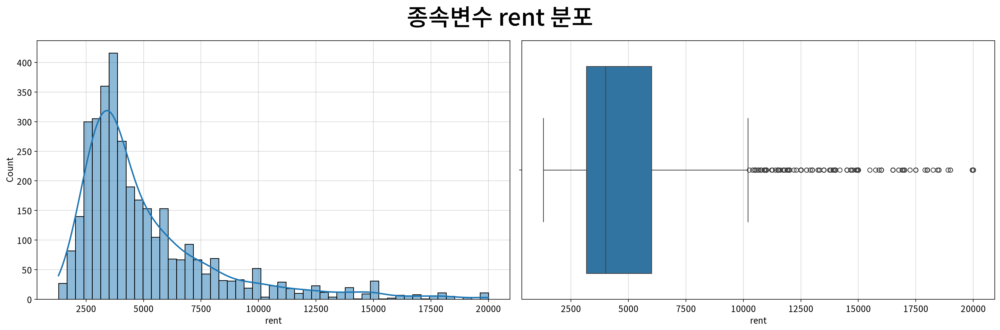

,rent
count,3512.000
mean,5142.887
std,3157.513
min,1300.000
25%,3169.250
50%,4000.000
75%,6000.000
max,20000.000
rel_diff,0.286
rdiff_flag,diff


In [16]:
## 1행 2열 서브플롯 구성
## -> 그래프 크기는 서브플롯 중 하나의 크기(전체 크기는 가로 960 x 2가 됨)
fig, ax = my_plot.init(rows=1, cols=2,
            title=f"종속변수 {target} 분포", width=960, height=640)
my_plot.histplot(data=df, x=target, kde=True, ax=ax[0])
my_plot.boxplot(data=df, x=target, ax=ax[1])
my_plot.show()

## 연속형 변수 기술통계량에서 종속변수에 대한 부분만 추출
num_desc[num_desc.index == target].T

**해석**
- **분포 모양**: **단봉·우편향**으로, 약 3,000~4,000달러 부근에 매물이 몰려 있고 고가 매물 쪽으로 꼬리가 길다(왜도 1.986, 첨도 4.343).
- **이상치**: IQR 기준 10,246.125달러를 초과하는 상단 이상치가 **271건(약 7.7%)**이며, 하단 이상치는 없다.
- **이산점(군집)**: 일부 금액대에서 빈도가 높게 나타나지만, 특정 금액에 겹친 정확한 건수나 최댓값 20,000달러에서 값을 잘라 기록했는지는 표와 그래프만으로 확인할 수 없다.
- **조치**: 오른쪽 꼬리가 뚜렷하여 **로그 변환 대상이다**(log_need = log1p) 고가 매물은 실제 관측값일 수 있으므로 이상치라는 이유만으로 삭제하지 않는다.
- **해석 방식의 변화**: 임대료에 로그를 적용하면, 집의 조건이 달라질 때 임대료가 몇 달러가 아니라 **몇 % 변하는지(비율)로 해석**한다.

##### 6) 연속형 독립변수에 대한 단변량 분석

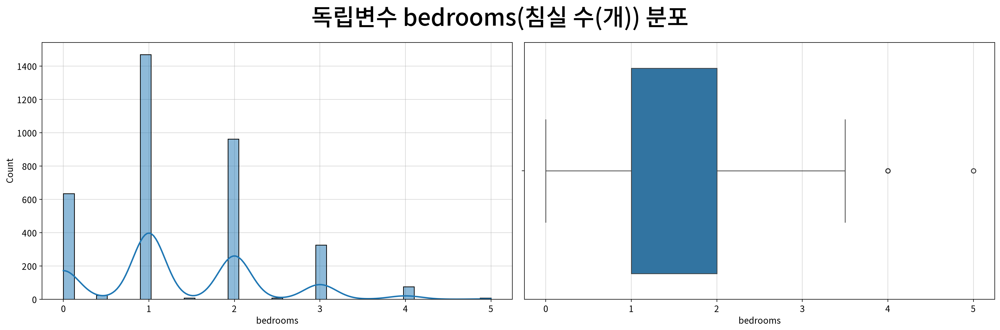

,bedrooms
count,3512.000
mean,1.354
std,0.968
min,0.000
25%,1.000
50%,1.000
75%,2.000
max,5.000
rel_diff,0.354
rdiff_flag,diff


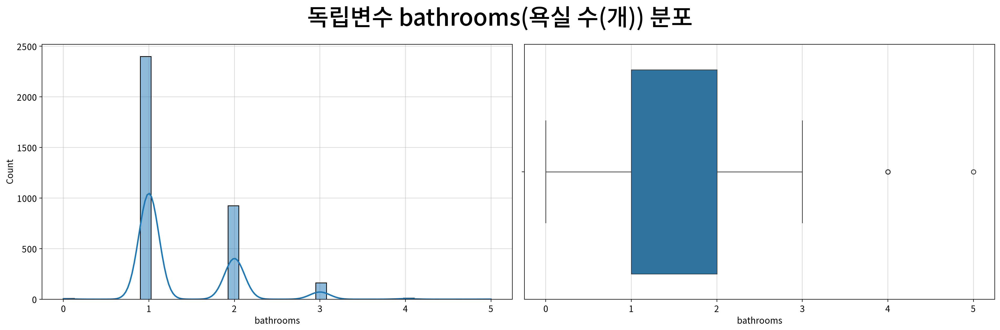

,bathrooms
count,3512.000
mean,1.367
std,0.600
min,0.000
25%,1.000
50%,1.000
75%,2.000
max,5.000
rel_diff,0.367
rdiff_flag,diff


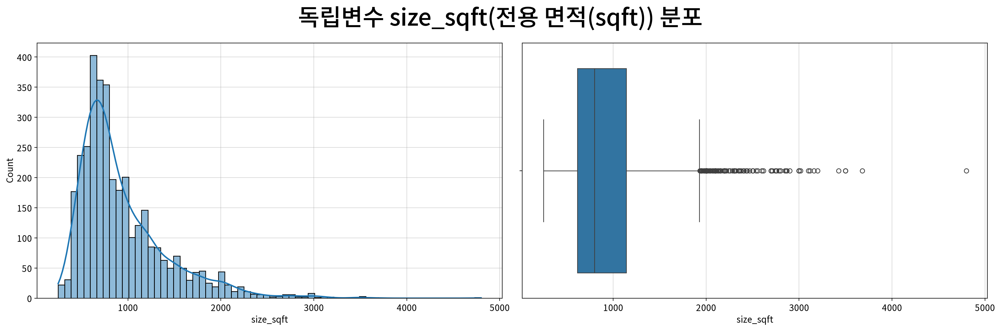

,size_sqft
count,3512.000
mean,940.287
std,478.290
min,250.000
25%,615.000
50%,800.000
75%,1141.500
max,4800.000
rel_diff,0.175
rdiff_flag,diff


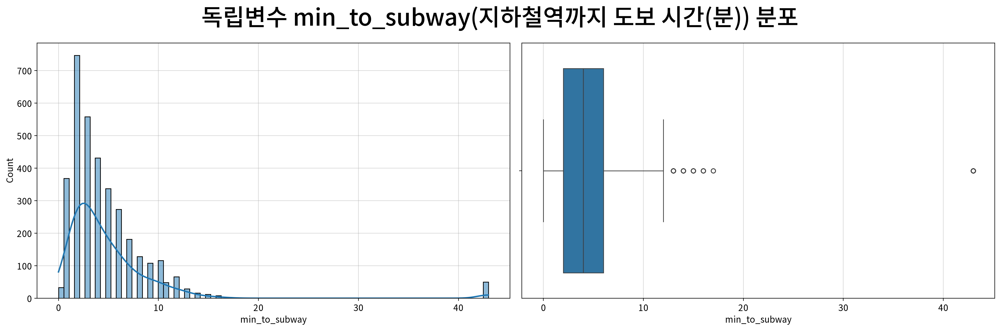

,min_to_subway
count,3512.000
mean,4.965
std,5.489
min,0.000
25%,2.000
50%,4.000
75%,6.000
max,43.000
rel_diff,0.241
rdiff_flag,diff


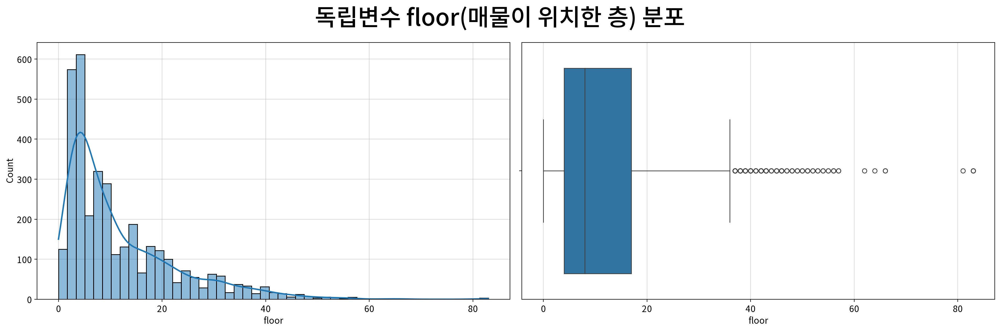

,floor
count,3512.000
mean,11.887
std,10.928
min,0.000
25%,4.000
50%,8.000
75%,17.000
max,83.000
rel_diff,0.486
rdiff_flag,diff


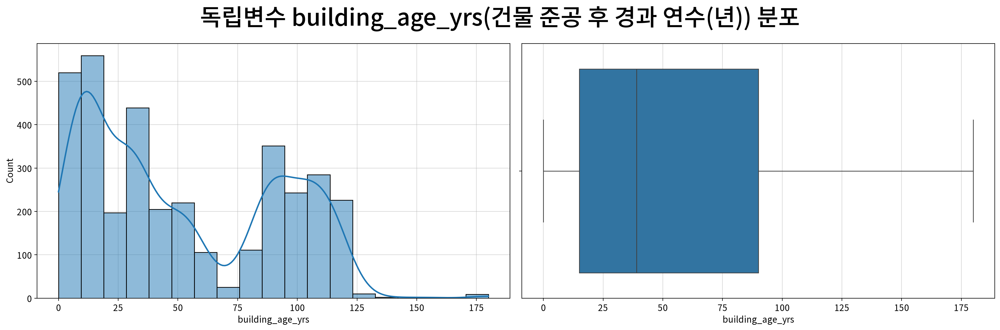

,building_age_yrs
count,3512.000
mean,51.958
std,39.420
min,0.000
25%,15.000
50%,39.000
75%,90.000
max,180.000
rel_diff,0.332
rdiff_flag,diff


In [17]:
for f in continuous_cols:
    fig, ax = my_plot.init(rows=1, cols=2, width=960, height=640,
                title=f"독립변수 {f}({column_means[f]}) 분포")
    my_plot.histplot(data=df, x=f, kde=True, ax=ax[0])
    my_plot.boxplot(data=df, x=f, ax=ax[1])
    my_plot.show()

    display(num_desc[num_desc.index == f].T)

##### 7) 명목형 독립변수에 대한 단변량 분석

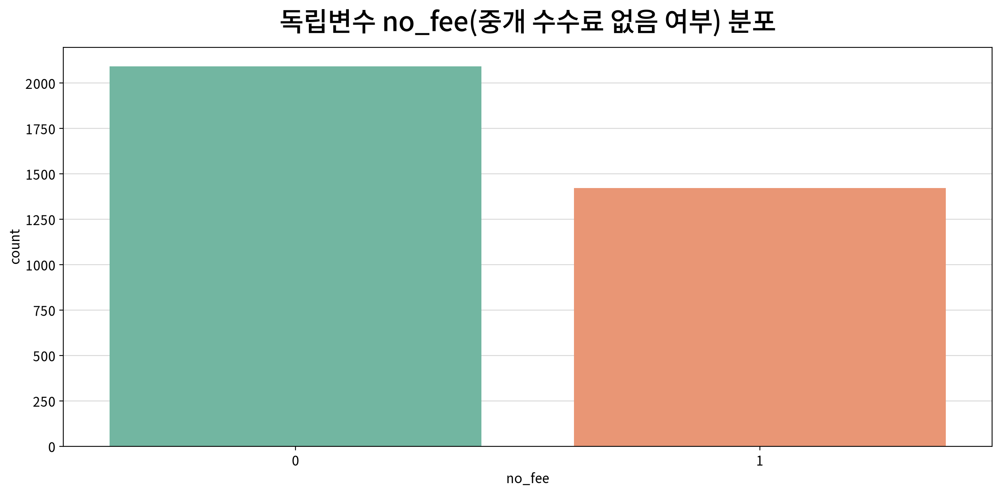

,count,unique,top,freq
no_fee,3512,2,0,2091


,빈도,비율
no_fee,,
0,2091,0.595
1,1421,0.405


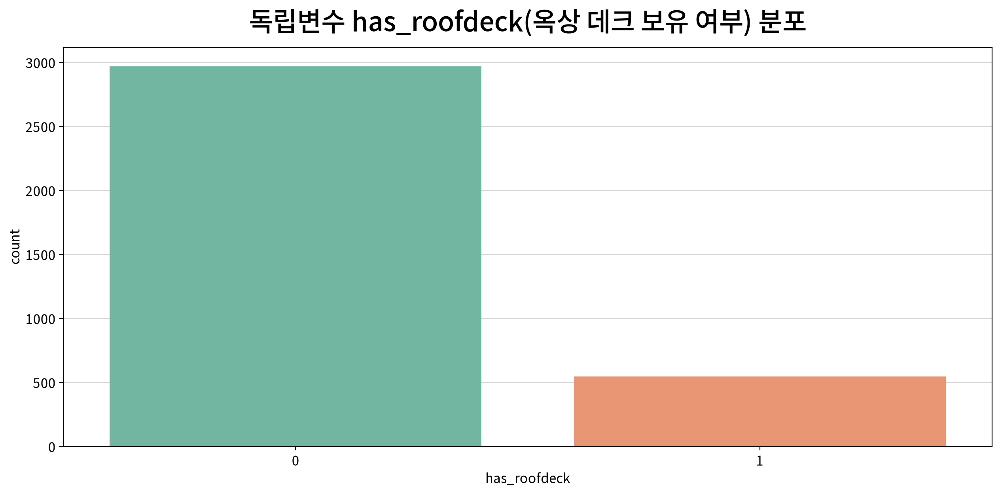

,count,unique,top,freq
has_roofdeck,3512,2,0,2967


,빈도,비율
has_roofdeck,,
0,2967,0.845
1,545,0.155


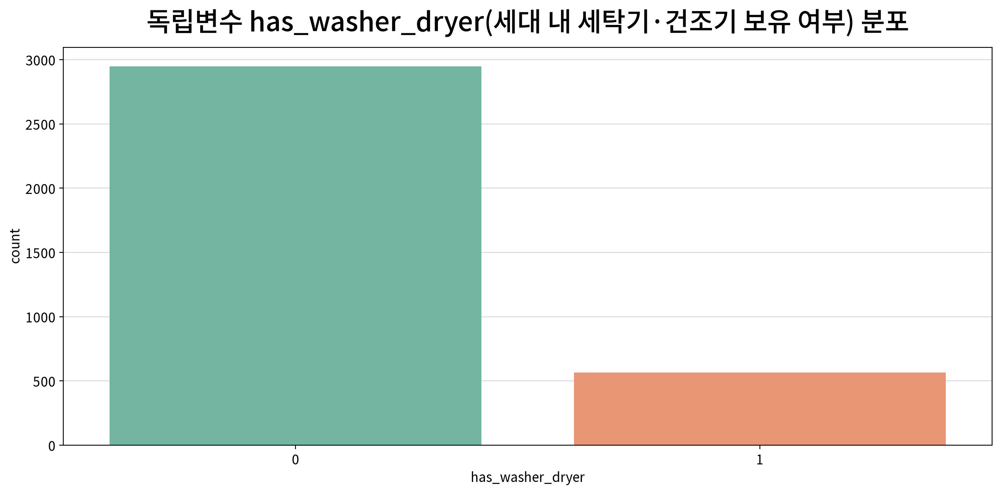

,count,unique,top,freq
has_washer_dryer,3512,2,0,2947


,빈도,비율
has_washer_dryer,,
0,2947,0.839
1,565,0.161


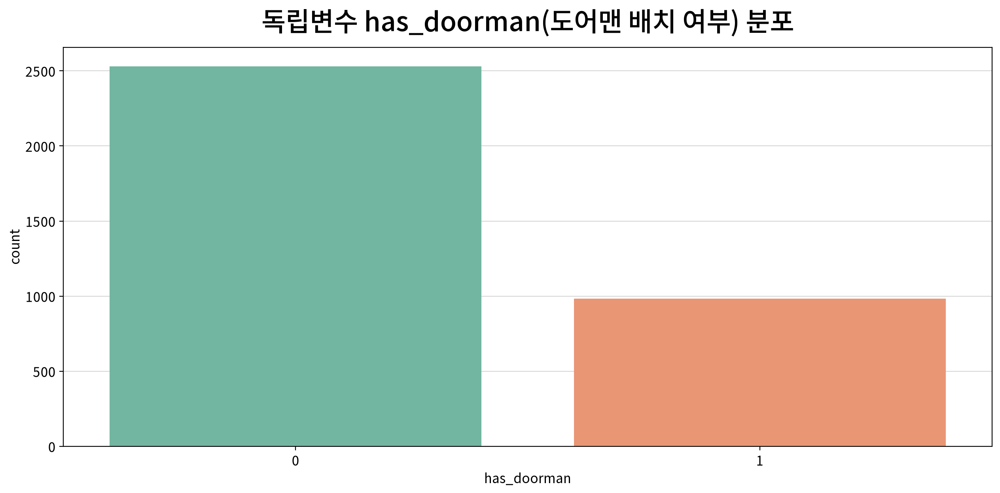

,count,unique,top,freq
has_doorman,3512,2,0,2529


,빈도,비율
has_doorman,,
0,2529,0.720
1,983,0.280


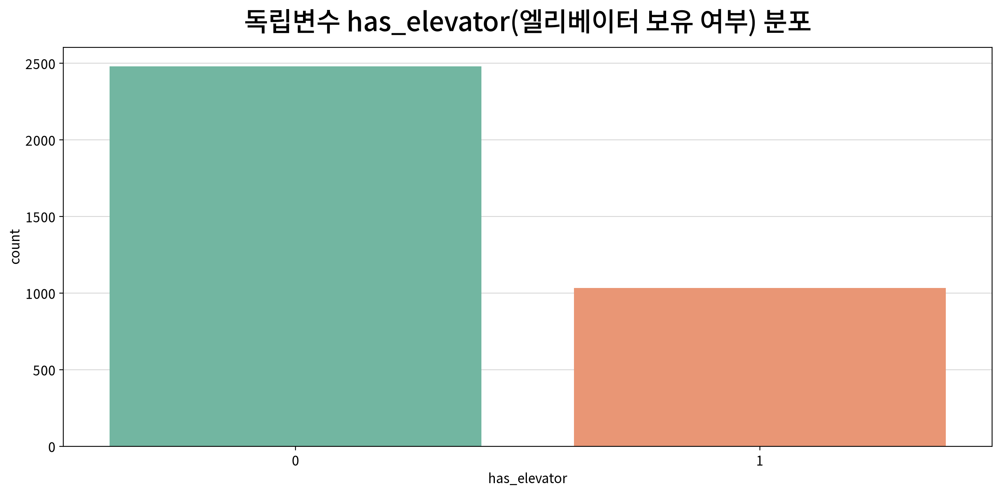

,count,unique,top,freq
has_elevator,3512,2,0,2479


,빈도,비율
has_elevator,,
0,2479,0.706
1,1033,0.294


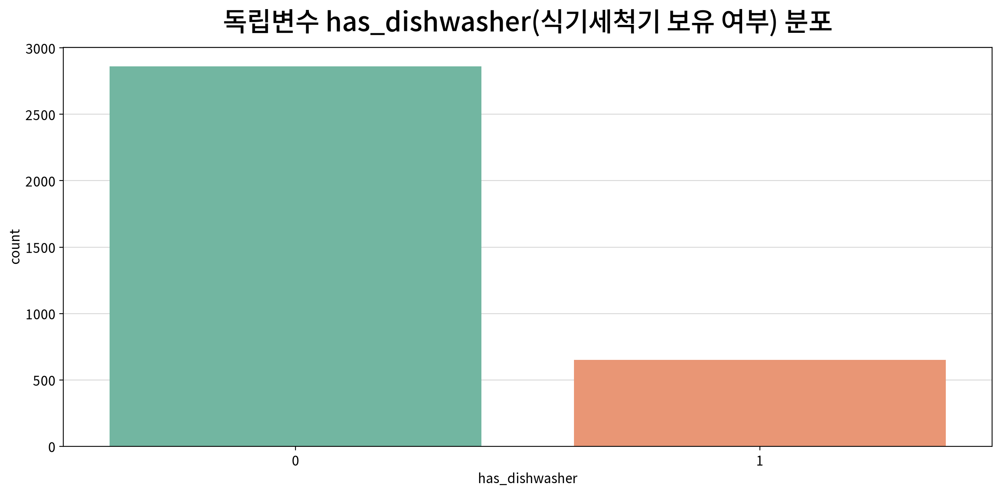

,count,unique,top,freq
has_dishwasher,3512,2,0,2860


,빈도,비율
has_dishwasher,,
0,2860,0.814
1,652,0.186


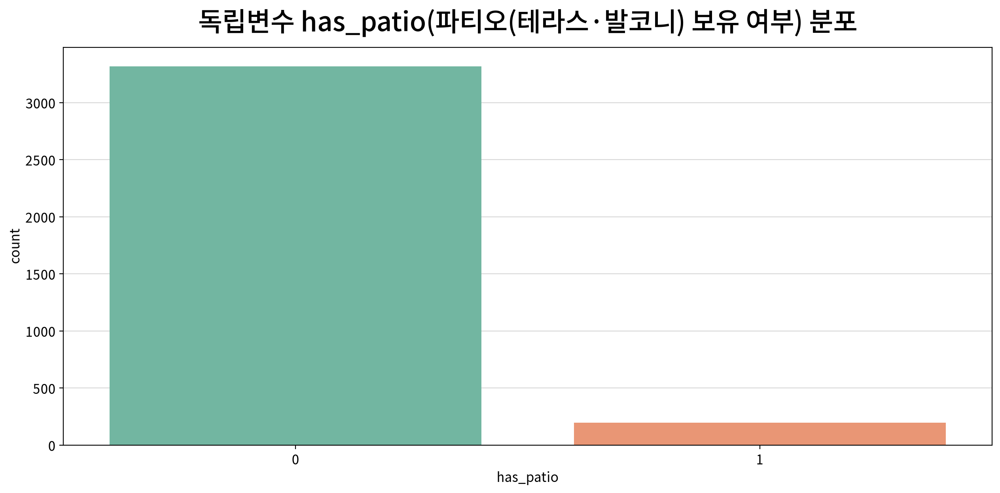

,count,unique,top,freq
has_patio,3512,2,0,3317


,빈도,비율
has_patio,,
0,3317,0.944
1,195,0.056


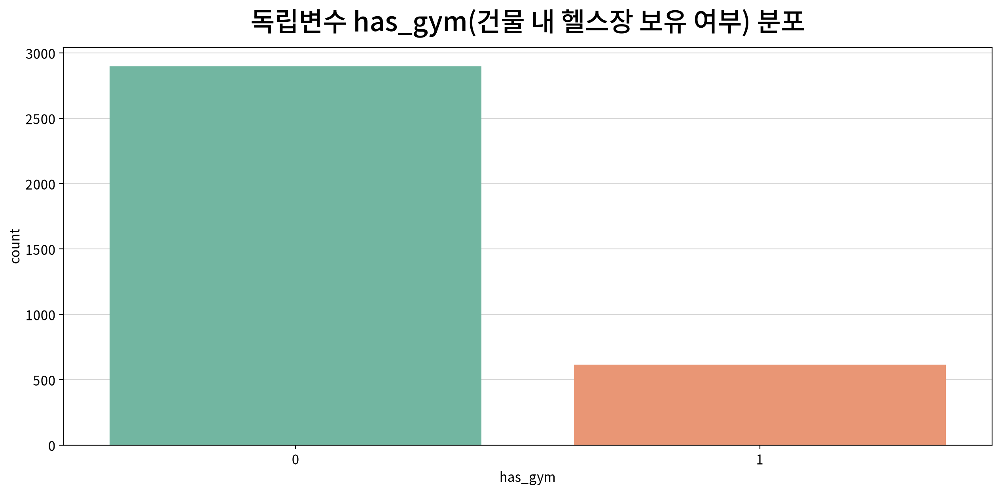

,count,unique,top,freq
has_gym,3512,2,0,2897


,빈도,비율
has_gym,,
0,2897,0.825
1,615,0.175


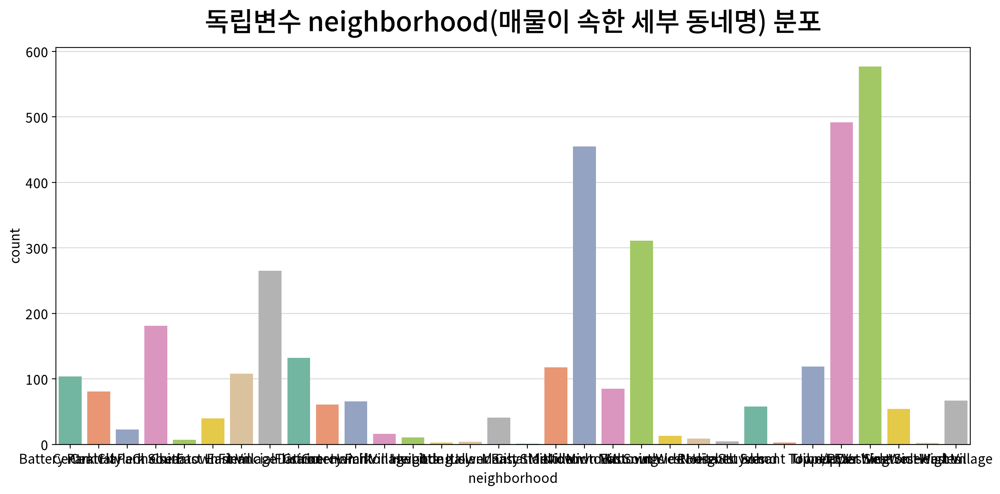

,count,unique,top,freq
neighborhood,3512,32,Upper West Side,577


,빈도,비율
neighborhood,,
Upper West Side,577,0.164
Upper East Side,492,0.140
Midtown East,455,0.130
Midtown West,311,0.089
Financial District,265,0.075
Chelsea,181,0.052
Flatiron,132,0.038
Tribeca,119,0.034
Midtown,118,0.034


In [18]:
for n in nominal_cols:
    ## 명목형 분포는 카운트 플롯으로 처리한다.
    my_plot.countplot(data=df, x=n, hue=n, palette="Set2", title=f"독립변수 {n}({column_means[n]}) 분포")

    ## 명목형 기술통계량
    display(cat_desc[[n]].T)

    ## 추가적으로 빈도표 생성
    freq = df[n].value_counts().rename("빈도").to_frame()
    ## value_counts(normalize=True)
    ## --> 전체 고유값의 개수(빈도수) 대신 전체 데이터의 비율을 계산
    freq["비율"] = df[n].value_counts(normalize=True)
    display(freq)

**해석**

| 변수 | 분포 모양(왜도) | 봉우리·집중 구간 | 이상치 | 판단·조치 |
|---|---|---|---|---|
| `bedrooms(침실 수)` | 약한 우편향 (+0.575) | 1개가 가장 많음 | 82건(2.3%) | 변환 불필요 |
| `bathrooms(욕실 수)` | 우편향 (+1.502) | 1개에 가장 많이 집중 | 15건(0.4%) | 변환 불필요 |
| `size_sqft(면적)` | 우편향 (+1.752) | 약 550~750sqft 부근 단봉 | 179건(5.1%) | **로그 변환(`log`) 검토** — 대형 매물을 오류로 단정하지 않음 |
| `min_to_subway(지하철 도보 시간)` | **강한 우편향 (+4.852)** | 2~4분 부근에 집중하며, 43분에 별도 무리가 나타남 | 118건(3.4%) | **로그 변환(`log1p`) 검토** — 43분 값의 기록 기준 확인 |
| `floor(층수)` | 우편향 (+1.711) | 약 3~5층 부근에 집중 | 144건(4.1%) | **로그 변환(`log1p`) 검토** — 고층 매물은 실제 값일 수 있어 유지 |
| `building_age_yrs(건물 연수)` | 치우침이 작음 (+0.420) | **약 10년과 90~110년 부근에 두 봉우리** | 0건(0.0%) | 변환 불필요 |


#### 4-2. 변수 간 관계

##### 1) 상관분석 (x: 연속형 독립변수 → y: 연속형 종속변수)

##### ▶︎ bedrooms(침실 수(개)) → rent

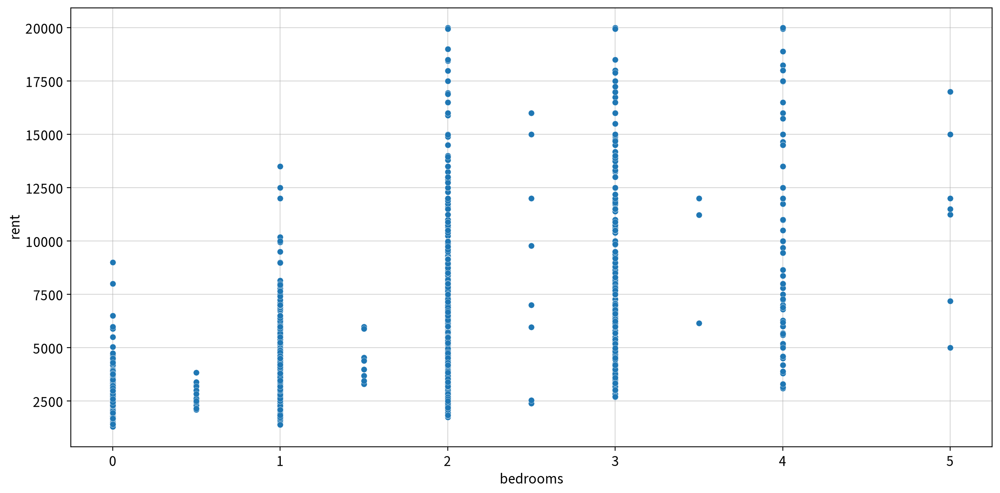

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential
x,y,,,,,,,,,
bedrooms,rent,Spearman,0.678,0.000,Moderate,True,False,False,False,True


##### ▶︎ bathrooms(욕실 수(개)) → rent

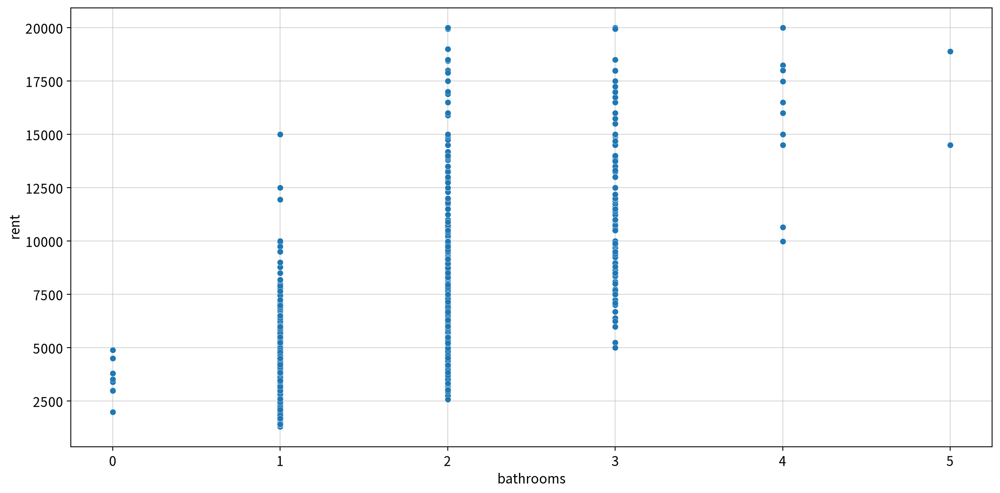

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential
x,y,,,,,,,,,
bathrooms,rent,Spearman,0.722,0.000,Strong,True,False,False,False,True


##### ▶︎ size_sqft(전용 면적(sqft)) → rent

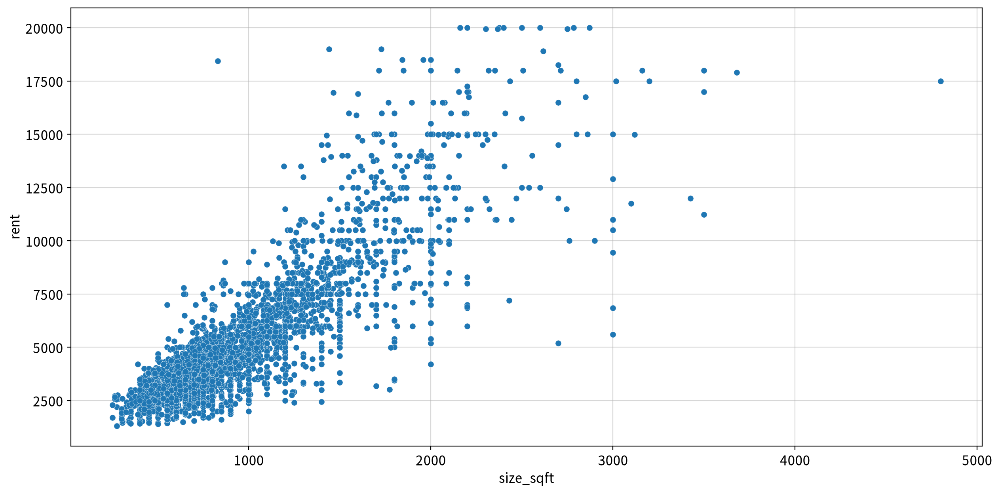

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential
x,y,,,,,,,,,
size_sqft,rent,Spearman,0.838,0.000,Strong,True,False,False,False,True


##### ▶︎ min_to_subway(지하철역까지 도보 시간(분)) → rent

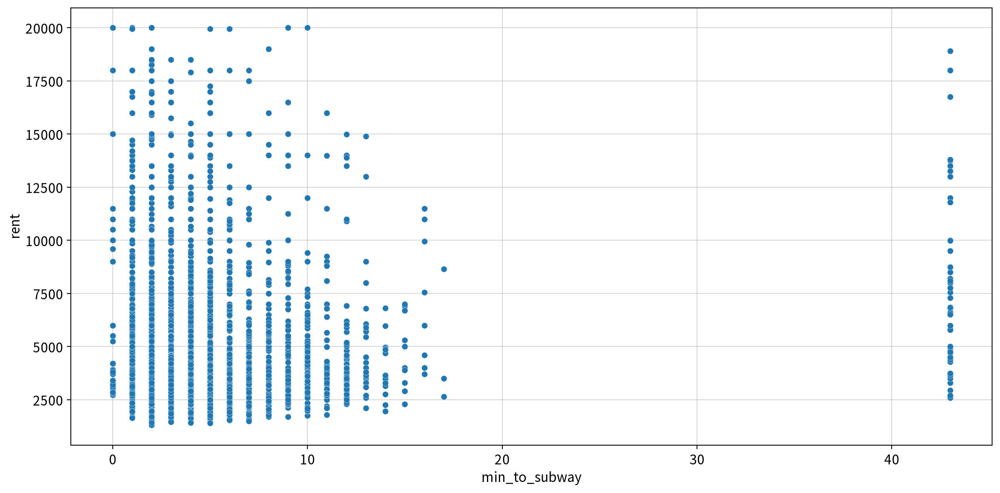

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential
x,y,,,,,,,,,
min_to_subway,rent,Spearman,-0.083,0.000,Weak,True,False,False,False,True


##### ▶︎ floor(매물이 위치한 층) → rent

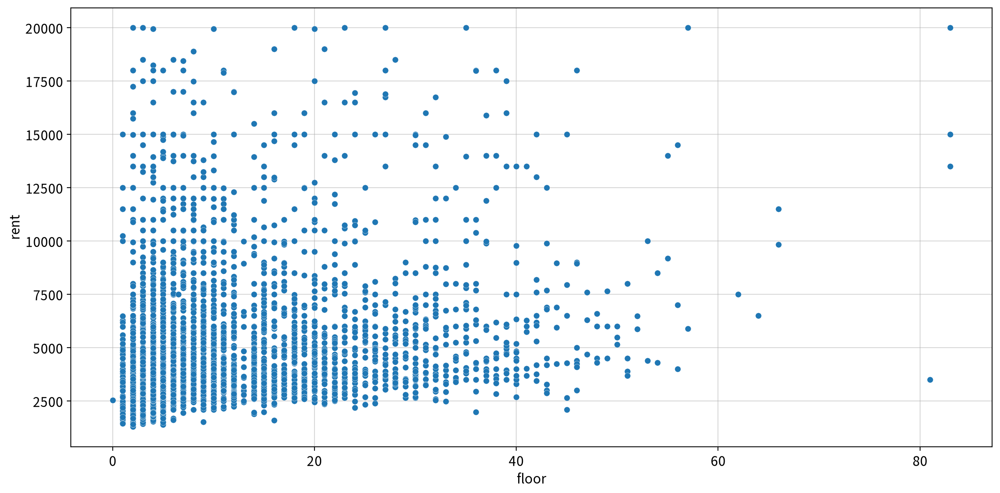

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential
x,y,,,,,,,,,
floor,rent,Spearman,0.300,0.000,Weak,True,False,False,True,True


##### ▶︎ building_age_yrs(건물 준공 후 경과 연수(년)) → rent

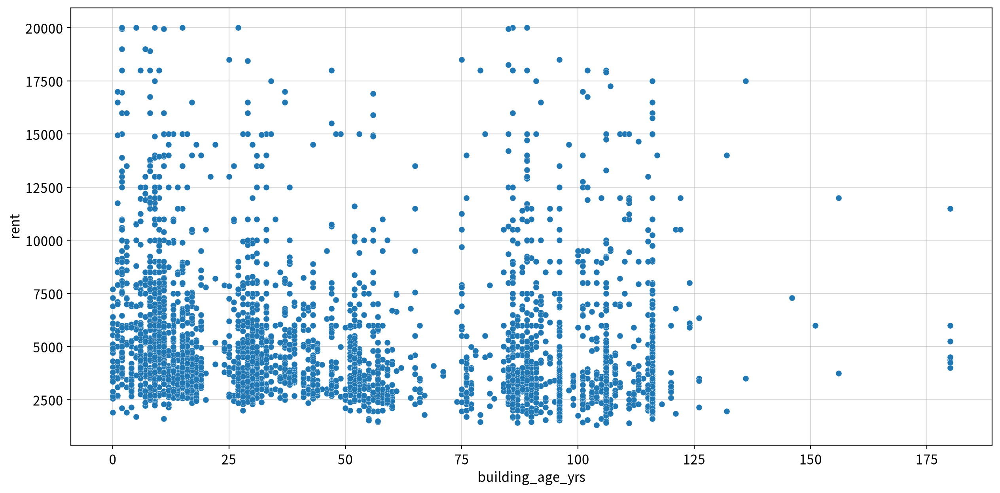

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential
x,y,,,,,,,,,
building_age_yrs,rent,Spearman,-0.253,0.000,Weak,True,False,False,False,True


In [19]:
## 연속형 독립변수 이름을 탐색하면서 반복
for f in continuous_cols:
    ## 빈 줄 출력용
    print()

    ## 분석 단위 제목 출력
    display(Markdown(f"##### ▶︎ {f}({column_means[f]}) → {target}"))

    ## 시각화
    my_plot.scatterplot(data=df, x=f, y=target, outline=False,
                        ## 데이터 밀도에 따라 외곽선 굵기와 점 크기 조절
                        linewidth=0.2, size=30)

    ## my_stats는 시각화까지 일괄처리 한다.
    display(my_stats.correlation(df, x=f, y=target, plot=False))

**해석**

| 변수 | 선형/비선형 | 단조성 | 산포 | 이상치·특이점 | 채택 여부 |
|---|---|---|---|---|---|
| `bedrooms` | ― | 양의 단조↑ (ρ = +0.678, Moderate) | 침실 2~4개에서 넓게 퍼짐 | 고가 매물 관찰 | ✅ 채택 |
| `bathrooms` | ― | 양의 단조↑ (ρ = +0.722, Strong) | 같은 욕실 수에서도 가격 차이가 큼 | 고가 매물 관찰 | ✅ 채택 |
| `size_sqft` | 대체로 선형 | 양의 단조↑ (ρ = +0.838, Strong) | 면적이 커질수록 퍼짐이 증가 | 추세에서 벗어난 일부 매물 관찰 | ✅ 채택 |
| `min_to_subway` | 뚜렷한 선형 없음 | 매우 약한 음의 단조↓ (ρ = −0.083, Weak) | 같은 도보 시간에서도 넓게 퍼짐 | 43분에 떨어진 무리 관찰 | 🟡 보류 |
| `floor` | 선형 | 약한 양의 단조↑ (ρ = +0.300, Weak) | 같은 층수에서도 가격 차이가 큼 | 일부 고가·초고층 매물 관찰 | ✅ 채택 |
| `building_age_yrs` | ― | 약한 음의 단조↓ (ρ = −0.253, Weak) | 같은 연수에서도 가격 차이가 큼 | 고가 매물 관찰 | ✅ 채택 |

- 모든 상관관계는 **p < .001**이지만, `min_to_subway`처럼 유의해도 관계의 강도가 매우 약할 수 있다.
- **산포는 그래프에서 관찰한 퍼짐**, Strong·Moderate·Weak는 상관 강도이다.
- 자동 선형성 판정은 함수의 기준에 따른 결과이며, **채택은 분석 후보로 유지한다는 의미**이다.

##### 2) T-Test (x: 2집단 명목형 독립변수 → y: 종속변수)

- 2개의 고유값만 존재하는 명목형 독립변수에 대해서만 검정을 수행한다.

##### ▶︎ no_fee(중개 수수료 없음 여부) → rent

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:5.947e-01 U_stat=1.501e+06


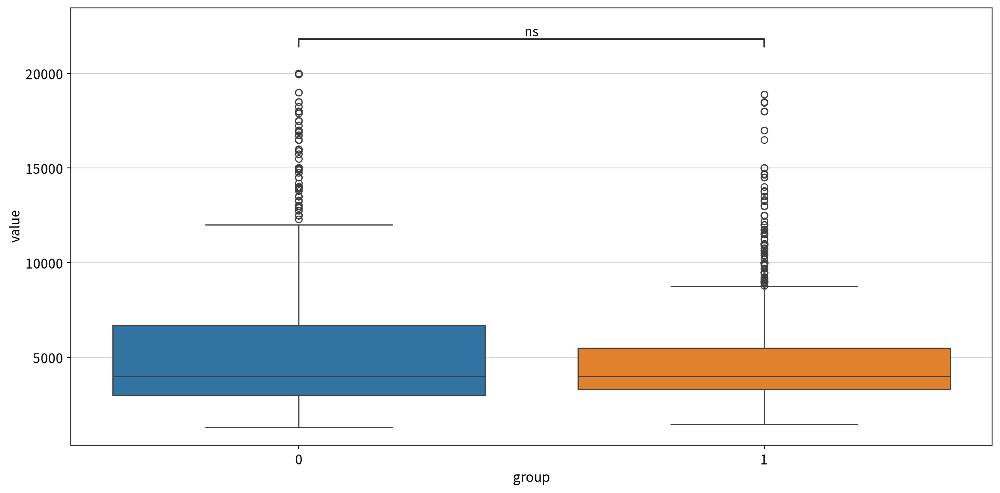

statistic  p-value  significant result
test                alternative                                         
Mann-Whitney U test two-sided   1501349.000    0.595        False  0 = 1
                    less        1501349.000    0.703        False  0 ≥ 1
                    greater     1501349.000    0.297        False  0 ≤ 1

##### ▶︎ has_roofdeck(옥상 데크 보유 여부) → rent

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:5.714e-02 U_stat=7.671e+05


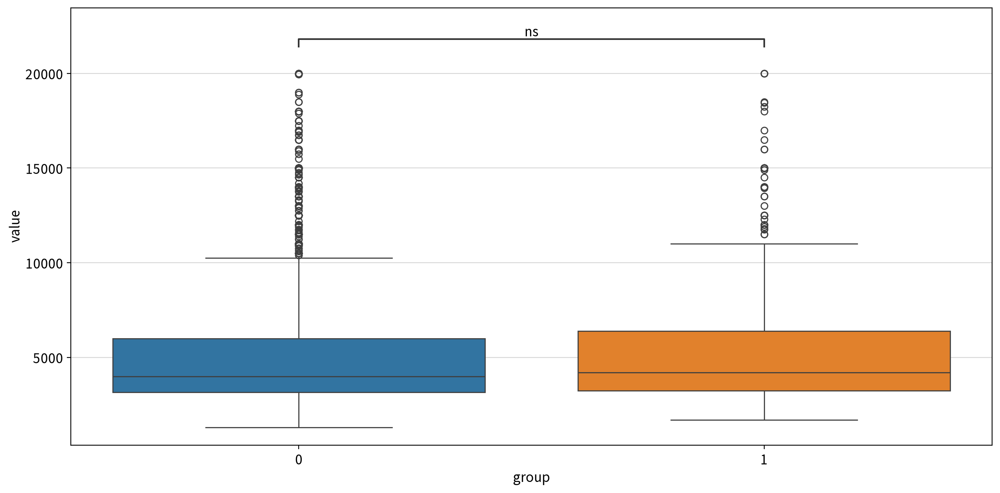

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided   767120.500    0.057        False  0 = 1
                    less        767120.500    0.029         True  0 < 1
                    greater     767120.500    0.971        False  0 ≤ 1

##### ▶︎ has_washer_dryer(세대 내 세탁기·건조기 보유 여부) → rent

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:1.526e-04 U_stat=7.489e+05


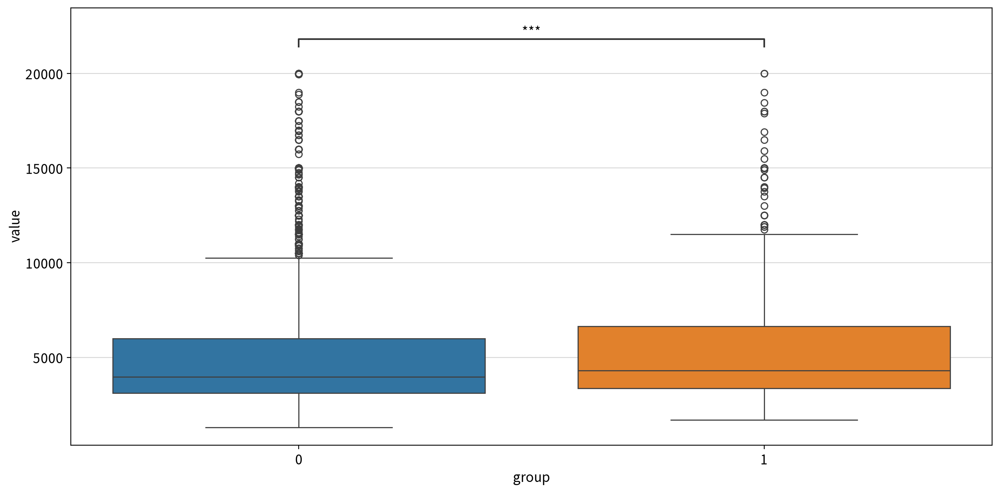

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided   748924.500    0.000         True  0 ≠ 1
                    less        748924.500    0.000         True  0 < 1
                    greater     748924.500    1.000        False  0 ≤ 1

##### ▶︎ has_doorman(도어맨 배치 여부) → rent

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:1.051e-02 U_stat=1.174e+06


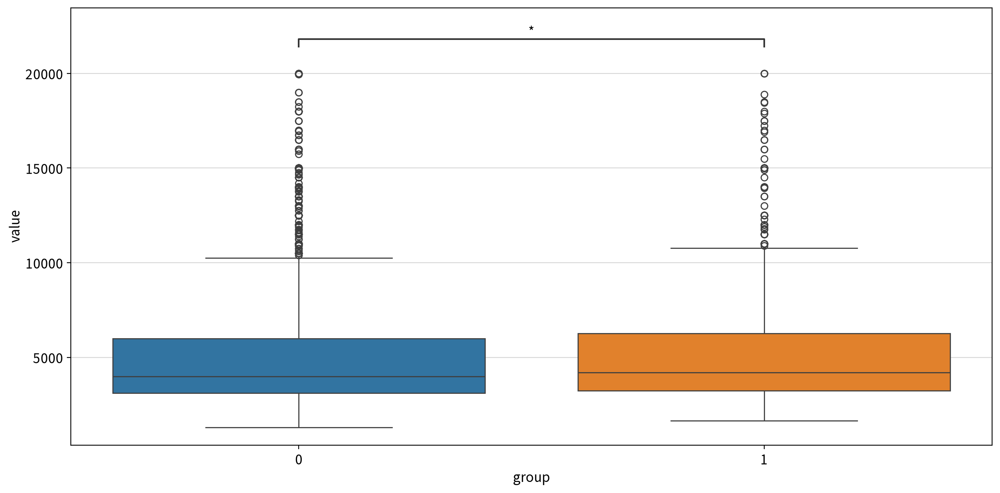

statistic  p-value  significant result
test                alternative                                         
Mann-Whitney U test two-sided   1173977.000    0.011         True  0 ≠ 1
                    less        1173977.000    0.005         True  0 < 1
                    greater     1173977.000    0.995        False  0 ≤ 1

##### ▶︎ has_elevator(엘리베이터 보유 여부) → rent

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.785e-04 U_stat=1.188e+06


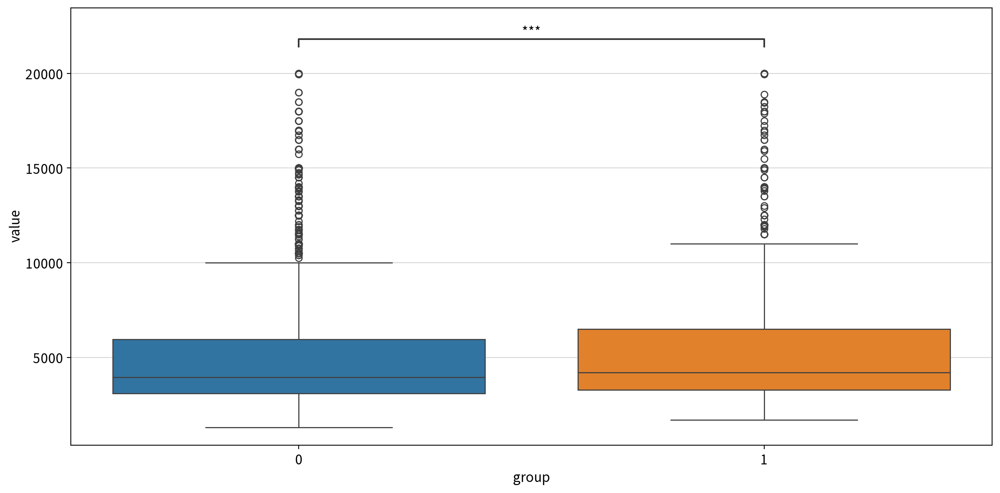

statistic  p-value  significant result
test                alternative                                         
Mann-Whitney U test two-sided   1188398.500    0.001         True  0 ≠ 1
                    less        1188398.500    0.000         True  0 < 1
                    greater     1188398.500    1.000        False  0 ≤ 1

##### ▶︎ has_dishwasher(식기세척기 보유 여부) → rent

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:2.400e-04 U_stat=8.466e+05


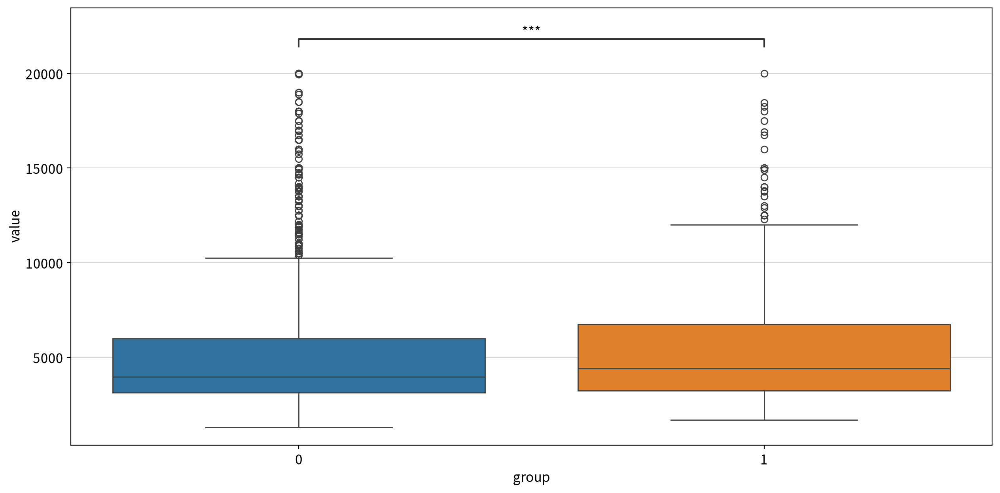

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided   846552.000    0.000         True  0 ≠ 1
                    less        846552.000    0.000         True  0 < 1
                    greater     846552.000    1.000        False  0 ≤ 1

##### ▶︎ has_patio(파티오(테라스·발코니) 보유 여부) → rent

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:5.701e-02 U_stat=2.972e+05


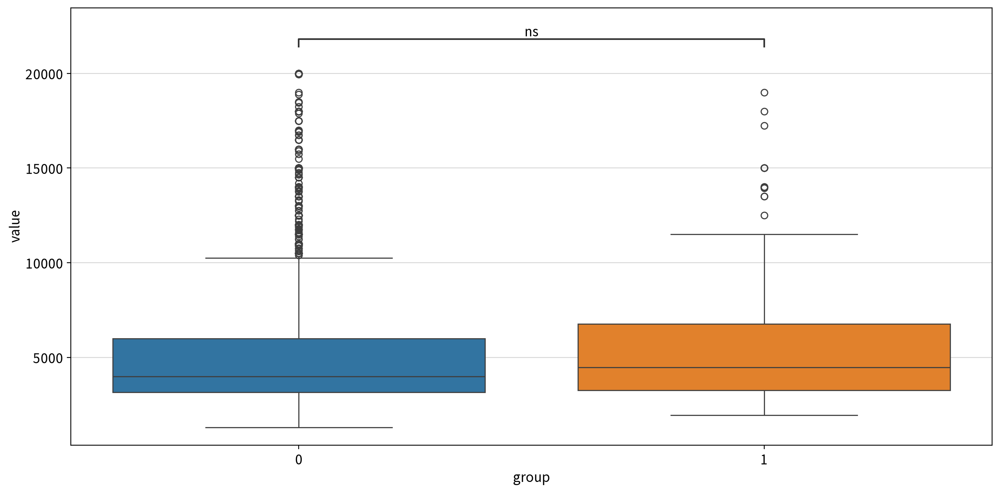

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided   297217.500    0.057        False  0 = 1
                    less        297217.500    0.029         True  0 < 1
                    greater     297217.500    0.972        False  0 ≤ 1

##### ▶︎ has_gym(건물 내 헬스장 보유 여부) → rent

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:5.052e-02 U_stat=8.462e+05


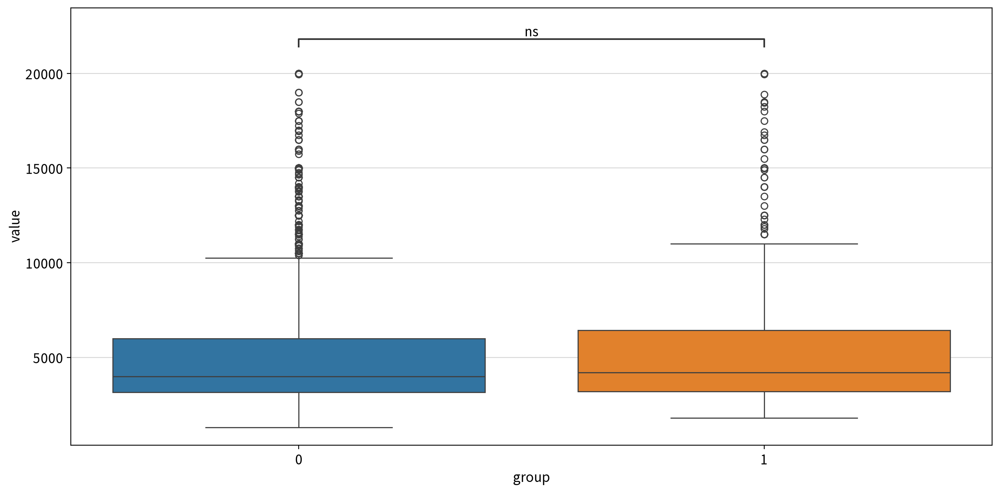

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided   846166.500    0.051        False  0 = 1
                    less        846166.500    0.025         True  0 < 1
                    greater     846166.500    0.975        False  0 ≤ 1

In [20]:
for n in nominal_cols:
    ## 2개의 고유값만 존재하는 명목형 독립변수에 대해서만 검정을 수행한다.
    if len(df[n].unique()) == 2:
        ## 빈 줄 출력용
        print()

        ## 분석 단위 제목 출력
        display(Markdown(f"##### ▶︎ {n}({column_means[n]}) → {target}"))

        ## 수집된 데이터가 long 타입이므로 검정 대상만 wide 타입으로 변환해야 한다.
        wide_df = my_prep.long2wide(df, hue=n, values=target)
        display(my_stats.test_independent(wide_df,
                    group1=wide_df.columns[0], group2=wide_df.columns[1]))

**검정 결과**

| 변수 | 검정 | 통계량 | p-value (양측) | 판단 (α = .05) | 채택 여부 |
|---|---|---:|---:|---|---|
| `no_fee` | Mann–Whitney U | U = 1501349.0 | **0.595** | 차이 없음 | 🟡 보류 |
| `has_roofdeck` | Mann–Whitney U | U = 767120.5 | **0.057** | 차이 없음 | 🟡 보류 |
| `has_washer_dryer` | Mann–Whitney U | U = 748924.5 | **< 0.001** | **차이 있음** | ✅ 채택 |
| `has_doorman` | Mann–Whitney U | U = 1173977.0 | **0.011** | **차이 있음** | ✅ 채택 |
| `has_elevator` | Mann–Whitney U | U = 1188398.5 | **0.001** | **차이 있음** | ✅ 채택 |
| `has_dishwasher` | Mann–Whitney U | U = 846552.0 | **< 0.001** | **차이 있음** | ✅ 채택 |
| `has_patio` | Mann–Whitney U | U = 297217.5 | **0.057** | 차이 없음 | 🟡 보류 |
| `has_gym` | Mann–Whitney U | U = 846166.5 | **0.051** | 차이 없음 | 🟡 보류 |

- 편의시설 변수 7개 중 **`has_washer_dryer`, `has_doorman`, `has_elevator`, `has_dishwasher`의 4개 변수**에서 보유 여부에 따른 임대료 분포에 유의한 차이가 확인되었다(양측 p < .05).
- `no_fee`(p = .595), `has_roofdeck`(p = .057), `has_patio`(p = .057), `has_gym`(p = .051)은 유의한 차이가 확인되지 않아 보류한다. 
    - 기존 결과와 비교하면 **`has_roofdeck`과 `has_gym`이 채택에서 보류로 변경**되었다.
- 다변량 모형에서 다른 변수를 통제한 뒤 계수의 유의성을 다시 확인한다.

##### 3) ANOVA (x: 3집단 명목형 독립변수 → y: 종속변수)

- 3개 이상의 고유값이 존재하는 명목형 독립변수에 대해서만 검정을 수행한다.

In [21]:
for n in nominal_cols:
    ## 3개 이상의 고유값이 존재하는 명목형 독립변수에 대해서만 검정을 수행한다.
    if len(df[n].unique()) >= 3:
        print() ## 빈 줄 출력용

        ## 분석 단위 제목 출력
        display(Markdown(f"##### ▶︎ {n}({column_means[n]}) → {target}"))

        display(my_stats.anova_oneway(df, y=target, between=n))
        
        ## 사후검정
        display(my_stats.posthoc_oneway(df, y=target, between=n, plot=False))

##### ▶︎ neighborhood(매물이 속한 세부 동네명) → rent

C:\백업파일\코딩공부\helpers\my_stats.py:88: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  s, p = normaltest(data[c].dropna())


,test,Source,ddof1,ddof2,F,p_unc,np2,effect_size
0,welch_anova,neighborhood,31,105.321,37.699,0.000,0.128,Medium


C:\백업파일\코딩공부\helpers\my_stats.py:88: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  s, p = normaltest(data[c].dropna())
c:\Users\rhdid\AppData\Local\Programs\Python\Python313\Lib\site-packages\pingouin\effsize.py:830: RuntimeWarning: Degrees of freedom <= 0 for slice
  poolsd = np.sqrt(((nx - 1) * x.var(ddof=1) + (ny - 1) * y.var(ddof=1)) / dof)
c:\Users\rhdid\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\_methods.py:211: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


,test,A,B,mean_A,mean_B,diff,se,T,df,pval,hedges,significant,effet_size
0,Games-Howell,Battery Park City,Central Harlem,5968.962,2980.765,2988.196,325.901,9.169,153.079,0.000,1.248,True,Large
1,Games-Howell,Battery Park City,Central Park South,5968.962,7506.957,-1537.995,802.293,-1.917,28.868,0.978,-0.499,False,Small
2,Games-Howell,Battery Park City,Chelsea,5968.962,6208.862,-239.900,366.309,-0.655,220.885,1.000,-0.080,False,Negligible
3,Games-Howell,Battery Park City,Chinatown,5968.962,2963.571,3005.390,458.369,6.557,16.015,0.001,1.041,True,Large
4,Games-Howell,Battery Park City,East Harlem,5968.962,2519.550,3449.412,303.589,11.362,122.895,0.000,1.360,True,Large
...,...,...,...,...,...,...,...,...,...,...,...,...,...
491,Games-Howell,Upper West Side,West Harlem,5361.863,2406.000,2955.863,336.542,8.783,1.463,0.169,0.878,False,Large
492,Games-Howell,Upper West Side,West Village,5361.863,5970.970,-609.107,449.374,-1.355,80.866,1.000,-0.180,False,Negligible
493,Games-Howell,Washington Heights,West Harlem,2539.333,2406.000,133.333,325.615,0.409,1.282,1.000,0.162,False,Negligible
494,Games-Howell,Washington Heights,West Village,2539.333,5970.970,-3431.637,441.250,-7.777,74.844,0.000,-1.282,True,Large


**검정 결과**

| 변수 | 검정 | 통계량 | p-value | 판단 | 채택 여부 |
|---|---|---|---|---|---|
| `neighborhood` | Welch ANOVA | F = 37.699 | **< 0.001** | **동네별 평균 임대료에 유의한 차이 있음** (α = .05) | ✅ 채택 |

- **효과크기:** 동네별 임대료 차이의 크기는 **중간 수준**이다(`np2` = 0.128)
- **사후검정:** Battery Park City의 평균 임대료는 **Central Harlem·East Harlem보다 유의하게 높고**(각 p < .001), **Chinatown보다도 유의하게 높다**(p = .001)
- **확인 사항:** 일부 동네는 매물 수가 적어 계산 경고가 발생했으므로, 해당 동네의 매물 수와 계산되지 않은 값이 있는지 확인한다.
    - `SmallSampleWarning: One or more sample arguments is too small`

#### 4-3. 다변량 분석 — 독립변수 간 상관

In [22]:
corr = my_stats.multi_correlation(df, columns=continuous_cols, plot=False)
my_stats.correlation_summary(corr)

method   coef  p-value  strength  \
x             y                                                      
bedrooms      bathrooms         Spearman  0.722    0.000    Strong   
              size_sqft         Spearman  0.828    0.000    Strong   
              min_to_subway     Spearman  0.042    0.014      Weak   
              floor             Spearman  0.046    0.006      Weak   
              building_age_yrs  Spearman  0.007    0.682      Weak   
bathrooms     size_sqft         Spearman  0.763    0.000    Strong   
              min_to_subway     Spearman  0.008    0.653      Weak   
              floor             Spearman  0.138    0.000      Weak   
              building_age_yrs  Spearman -0.115    0.000      Weak   
size_sqft     min_to_subway     Spearman -0.009    0.580      Weak   
              floor             Spearman  0.134    0.000      Weak   
              building_age_yrs  Spearman -0.064    0.000      Weak   
min_to_subway floor             Spearman  0.020    0.229      Weak   
              building_age_yrs  Spearman -0.160    0.000      Weak   
floor         building_age_yrs  Spearman -0.408    0.000  Moderate   

                                significant  normality_x  normality_y  \
x             y                                                         
bedrooms      bathrooms                True        False        False   
              size_sqft                True        False        False   
              min_to_subway            True        False        False   
              floor                    True        False        False   
              building_age_yrs        False        False        False   
bathrooms     size_sqft                True        False        False   
              min_to_subway           False        False        False   
              floor                    True        False        False   
              building_age_yrs         True        False        False   
size_sqft     min_to_subway           False        False        False   
              floor                    True        False        False   
              building_age_yrs         True        False        False   
min_to_subway floor                   False        False        False   
              building_age_yrs         True        False        False   
floor         building_age_yrs         True        False        False   

                                linearity  influential  
x             y                                         
bedrooms      bathrooms             False         True  
              size_sqft             False         True  
              min_to_subway          True         True  
              floor                 False         True  
              building_age_yrs      False        False  
bathrooms     size_sqft              True         True  
              min_to_subway         False         True  
              floor                  True         True  
              building_age_yrs      False         True  
size_sqft     min_to_subway         False         True  
              floor                 False         True  
              building_age_yrs      False         True  
min_to_subway floor                  True         True  
              building_age_yrs      False         True  
floor         building_age_yrs      False         True

,bedrooms,bathrooms,size_sqft,min_to_subway,floor,building_age_yrs
bedrooms,1.000,0.722,0.828,0.042,0.046,0.007
bathrooms,0.722,1.000,0.763,0.008,0.138,-0.115
size_sqft,0.828,0.763,1.000,-0.009,0.134,-0.064
min_to_subway,0.042,0.008,-0.009,1.000,0.020,-0.160
floor,0.046,0.138,0.134,0.020,1.000,-0.408
building_age_yrs,0.007,-0.115,-0.064,-0.160,-0.408,1.000


,max-y,max-coef,count,columns
x,,,,
bedrooms,size_sqft,0.828,2,"size_sqft, bathrooms"
size_sqft,bedrooms,0.828,2,"bedrooms, bathrooms"
bathrooms,size_sqft,0.763,2,"size_sqft, bedrooms"
building_age_yrs,floor,-0.408,0,-
floor,building_age_yrs,-0.408,0,-
min_to_subway,building_age_yrs,-0.160,0,-


# 💥💥💥💥💥샤갈 vif💥💥💥💥💥💥💥

**해석**

- **Strong 구간(|ρ| ≥ 0.7)의 쌍:** `bedrooms`–`size_sqft`(+0.828), `bathrooms`–`size_sqft`(+0.763), `bedrooms`–`bathrooms`(+0.722)으로 **총 3쌍**이며, 모두 양의 상관이다(각 p < .001)
- **공통 관계:** 면적이 클수록 침실 수와 욕실 수가 많고, 침실 수가 많을수록 욕실 수도 많은 경향이 확인된다.
- **중복 검토 대상:** `bedrooms`·`bathrooms`·`size_sqft`는 각각 나머지 두 변수와 Strong 관계이므로, 함께 모델에 넣을 때 **다중공선성을 점검한다.**
- **Moderate 구간:** `floor`–`building_age_yrs`는 ρ = **−0.408**로, 건물 연수가 클수록 매물 층수가 낮은 경향이 있다(p < .001)
- **Strong 상대가 없는 변수:** `min_to_subway`·`floor`·`building_age_yrs`는 Strong 관계인 상대가 없다.
- **유의성과 강도 구분:** `bedrooms`–`min_to_subway`는 p = **.014**로 유의하지만, ρ = +0.042로 관계는 매우 약하다.
- **후속 조치:** 상관이 높다는 이유만으로 바로 제거하지 않고, **VIF와 변수 제거 전후의 모델 성능을 비교해 결정한다.**

#### 4-4. 모델링 설계 근거

**가설 확정**

| 가설 | EDA 근거 | 판단 |
|---|---|---|
| **H1. 면적·침실 수·욕실 수 ↑ → 임대료 ↑** | 각각 ρ = +0.838, +0.678, +0.722이며 모두 유의함 | **확정 — EDA에서 지지** |
| **H2. 도보 시간·건물 연수 ↑ → 임대료 ↓** | 각각 ρ = −0.083, −0.253으로 음의 상관이지만 약함 | **수정 — 약한 관계로 해석** |
| **H3. 편의시설 보유 여부에 따른 임대료 차이** | 세탁기·건조기, 도어맨, 엘리베이터, 식기세척기에서 유의한 차이 | **수정 — 일부 시설에서 지지** |
| **H4. 동네별 평균 임대료 차이** | F = 37.699, p < .001, 효과크기 0.128 | **확정 — EDA에서 지지** |

**투입 변수 선정**

- `borough`를 제외한 **독립변수 15개를 기준 모형에 투입**한다.
- 관계가 약하거나 유의하지 않은 변수는 유지·제외에 따른 성능을 비교한다.
- `bedrooms`·`bathrooms`·`size_sqft`는 서로 상관이 높아 **VIF로 다중공선성을 확인**한다.

**변수 변환 필요성**

- **로그 변환 검토:** `rent`, `size_sqft` → `log` / `min_to_subway`, `floor` → `log1p`
- **원래 값 유지 우선:** `bedrooms`, `bathrooms`, `building_age_yrs`
- **이상치:** 바로 삭제하지 않고, 학습 데이터에서 원래 값 유지와 경계값 대체의 성능을 비교한다.

**평가지표 우선순위와 이유**

- **1순위 RMSE:** 예측값을 **USD/월로 되돌려** 같은 검증 데이터에서 비교한다.
- **2순위 간결함:** 검증 RMSE 차이가 **5% 이내**이면 변수가 적고 해석하기 쉬운 모형을 선택한다.

※ 가설 판단은 인과관계의 확정이 아니며, 편의시설 검정은 다중검정 보정 전 기준이다.

### 발견사항 목록, 미션 4

> “겹치는 축은 무엇인가?”

- **겹치는 변수:** `bedrooms`·`bathrooms`·`size_sqft`는 서로 강한 양의 상관을 보인다. 세 변수 모두 **집의 규모**를 나타내므로 정보가 일부 겹친다.

| 변수 쌍 | Spearman 상관계수(ρ) | 해석 |
|---|---:|---|
| `bedrooms`–`size_sqft` | +0.828 | 면적이 클수록 침실이 많은 경향 |
| `bathrooms`–`size_sqft` | +0.763 | 면적이 클수록 욕실이 많은 경향 |
| `bedrooms`–`bathrooms` | +0.722 | 침실이 많을수록 욕실도 많은 경향 |

- **모두 넣을 때:** 다중공선성으로 각 변수의 영향을 구분하기 어려워지고, 회귀계수가 불안정해질 수 있다. 실제 문제가 있는지는 **VIF로 확인한다.**

- **대표 변수:**  **`size_sqft`**를 채택한다. 집의 크기를 직접 나타내며, 월세와의 상관도 세 변수 중 가장 높다(ρ = **0.838**).

- **나머지 정보 활용:** `bedrooms / size_sqft`, `bathrooms / size_sqft`처럼 **면적 대비 침실·욕실 수**를 만들어 공간 구성을 표현할 수 있다. 다만 공선성이 줄고 예측이 좋아지는지는 따로 확인한다.

- **최종 결정:** 세 변수를 모두 넣은 모형과 대표 변수·파생변수를 사용한 모형의 **VIF와 검증 데이터 예측 성능**을 비교한다.

**모델에 넣을 1순위 변수 — 세 줄 정리**

> 1순위 변수는 `size_sqft`(면적)이다.  
> 월세와의 상관계수가 0.838로, 분석한 수치형 독립변수 중 가장 높다.  
> 집의 규모를 직접 표현해 해석하기 쉽고, 침실·욕실 수와 겹치는 정보를 대표할 수 있다.

#### #파생변수 생성
| 관점 | 아이디어 | 이름 |
|---|---|---|
| **방 하나를 얼마나 넓게 쓰나** | 전용 면적 ÷ (침실 수 + 욕실 수) | `size_per_room` |
| **편의시설을 몇 개나 갖췄나** | `has_*` 일곱 개의 합 (0~7) | `amenity_count` |
| **동네에서 큰 집인가 작은 집인가** | 전용 면적 ÷ **그 동네** 평균 전용 면적 | `size_neigh_ratio` |
| **동네에서 높은 층인가** | 층 ÷ **그 동네** 평균 층 | `floor_neigh_ratio` |

In [23]:
# 방 하나 면적
df['size_per_room'] = df['size_sqft'] / (df['bedrooms'] + df['bathrooms'])

# 편의시설 개수
amenity_cols = [
    'has_roofdeck',
    'has_washer_dryer',
    'has_doorman',
    'has_elevator',
    'has_dishwasher',
    'has_patio',
    'has_gym'
]

df['amenity_count'] = df[amenity_cols].astype(int).sum(axis=1)

# 동네 평균 대비 집 면적
df['size_neigh_ratio'] = (df['size_sqft'] / df.groupby('neighborhood', observed=True)['size_sqft'].transform('mean'))

# 동네 평균 대비 층
df['floor_neigh_ratio'] = (df['floor'] / df.groupby('neighborhood', observed=True)['floor'].transform('mean'))

df[[
    "size_per_room",
    "amenity_count",
    "size_neigh_ratio",
    "floor_neigh_ratio",
]].head()

,size_per_room,amenity_count,size_neigh_ratio,floor_neigh_ratio
0,480.000,4,0.471,0.167
1,500.000,0,2.169,0.157
2,458.000,4,0.880,2.198
3,487.500,4,1.057,1.257
4,1200.000,4,3.436,1.022


#### #컬럼 설명 딕셔너리 갱신

새로 만든 네 변수의 한글 의미를 `column_means`에 추가함.

In [24]:
column_means.update({
    "size_per_room": "방 하나당 면적",
    "amenity_count": "편의시설 개수",
    "size_neigh_ratio": "동네 평균 대비 집 크기",
    "floor_neigh_ratio": "동네 평균 대비 층",
})

#### #생성한 파생변수 점검

나눗셈의 분모에 0이 있으면 무한대(`inf`)가 발생함. 따라서 분모의 최솟값, 결과의 결측치, 양·음의 무한대를 확인함.

In [25]:
display(Markdown("### 분모로 사용한 변수의 최솟값 확인"))

print("bedrooms + bathrooms 최솟값:",
      (df["bedrooms"] + df["bathrooms"]).min())

print("동네별 size_sqft 평균의 최솟값:",
      df.groupby("neighborhood", observed=True)["size_sqft"].transform("mean").min())

print("동네별 floor 평균의 최솟값:",
      df.groupby("neighborhood", observed=True)["floor"].transform("mean").min())

display(Markdown("### 편의시설 개수 범위 확인"))

print(df["amenity_count"].agg(["min", "max"]))

check = df[[
    "size_per_room",
    "amenity_count",
    "size_neigh_ratio",
    "floor_neigh_ratio",
]]


display(Markdown("### 파생변수에 결측값이 있는지 확인"))

print(check.isna().sum())

display(Markdown("### 파생변수에 무한대가 있는지 확인"))

print(check.isin([float("inf"), float("-inf")]).sum())

### 분모로 사용한 변수의 최솟값 확인

bedrooms + bathrooms 최솟값: 0.0
동네별 size_sqft 평균의 최솟값: 433.3333333333333
동네별 floor 평균의 최솟값: 2.9375


### 편의시설 개수 범위 확인

min    0
max    7
Name: amenity_count, dtype: int64


### 파생변수에 결측값이 있는지 확인

size_per_room        0
amenity_count        0
size_neigh_ratio     0
floor_neigh_ratio    0
dtype: int64


### 파생변수에 무한대가 있는지 확인

size_per_room        2
amenity_count        0
size_neigh_ratio     0
floor_neigh_ratio    0
dtype: int64


#### 점검 결과

- `bedrooms + bathrooms`의 최솟값이 **0**으로 확인됨.
    - 따라서 `size_per_room` 계산 과정에서 **0으로 나누는 경우가 발생**함.
- 실제로 `size_per_room`에서 **무한대 값이 2개** 확인됨.
- `amenity_count`는 **0~7 범위**로 정상적으로 생성됨.
- `size_neigh_ratio`, `floor_neigh_ratio`의 분모는 모두 0보다 크며 **무한대가 없음**.
- 생성된 파생변수에는 **결측치가 없음**.
    - 따라서 `size_per_room`의 무한대 값 2개에 대한 처리가 필요함.

##### 무한대(inf) 제거

In [26]:
# size_per_room에서 무한대 값이 발생한 행 2개 제거
df = df[~df["size_per_room"].isin([float("inf"), float("-inf")])].copy()

# 제거 확인
print(df["size_per_room"].isin([float("inf"), float("-inf")]).sum())

0


#### #2차 파생변수 생성

| 관점 | 아이디어 | 이름 |
|---|---|---|
| **방 하나가 동네에서 넓은 편인가** | 방 하나당 면적 ÷ **그 동네** 평균 방 하나당 면적 | `room_size_neigh_ratio` |
| **편의시설이 동네에서 많은 편인가** | 편의시설 개수 ÷ **그 동네** 평균 편의시설 개수 | `amenity_neigh_ratio` |

In [27]:
# 방 하나당 면적의 동네 평균 대비 비율
df['room_size_neigh_ratio'] = (df['size_per_room'] / df.groupby('neighborhood', observed=True)['size_per_room'].transform('mean'))

# 편의시설 개수의 동네 평균 대비 비율
df['amenity_neigh_ratio'] = (df['amenity_count'] / df.groupby('neighborhood', observed=True)['amenity_count'].transform('mean'))

df[[
    "room_size_neigh_ratio",
    "amenity_neigh_ratio"
]].head()

,room_size_neigh_ratio,amenity_neigh_ratio
0,1.327,2.718
1,1.104,0.000
2,1.117,2.088
3,1.076,2.694
4,2.782,2.974


#### #2차 파생변수 점검

나눗셈의 분모에 0이 있으면 무한대(`inf`)가 발생함. 따라서 분모의 최솟값, 결과의 결측치, 양·음의 무한대를 확인함.

In [28]:
# 2차 파생변수의 분모, 결측값, 무한대 여부를 점검
display(Markdown("### 분모로 사용한 변수의 최솟값 확인"))

print("동네별 size_per_room 평균의 최솟값:",
      df.groupby("neighborhood", observed=True)["size_per_room"].transform("mean").min())

print("동네별 amenity_count 평균의 최솟값:",
      df.groupby("neighborhood", observed=True)["amenity_count"].transform("mean").min())

display(Markdown("### 2차 파생변수 범위 확인"))

print(df[["room_size_neigh_ratio", "amenity_neigh_ratio"]].agg(["min", "max"]))

check = df[[
    "room_size_neigh_ratio",
    "amenity_neigh_ratio"
]]

display(Markdown("### 파생변수에 결측값이 있는지 확인"))

print(check.isna().sum())

display(Markdown("### 파생변수에 무한대가 있는지 확인"))

print(check.isin([float("inf"), float("-inf")]).sum())

### 분모로 사용한 변수의 최솟값 확인

동네별 size_per_room 평균의 최솟값: 229.16666666666669
동네별 amenity_count 평균의 최솟값: 0.0


### 2차 파생변수 범위 확인

     room_size_neigh_ratio  amenity_neigh_ratio
min                  0.343                0.000
max                  4.688               27.000


### 파생변수에 결측값이 있는지 확인

room_size_neigh_ratio    0
amenity_neigh_ratio      3
dtype: int64


### 파생변수에 무한대가 있는지 확인

room_size_neigh_ratio    0
amenity_neigh_ratio      0
dtype: int64


In [69]:
column_means.update({ "room_size_neigh_ratio": "지역 평균 대비 방당 면적 비율",  "amenity_neigh_ratio": "지역 평균 대비 편의시설 수 비율" })

#### 점검 결과

- `room_size_neigh_ratio`의 분모인 동네별 평균 `size_per_room`의 최솟값은 약 **229.17**로 0보다 큼
- `amenity_neigh_ratio`의 분모인 동네별 평균 `amenity_count`의 최솟값은 **0**으로 확인됨
- `room_size_neigh_ratio`는 **0.343~4.688** 범위이며 결측값과 무한대가 없음
- `amenity_neigh_ratio`는 **0~27** 범위이며 무한대는 없지만 **결측값이 3개** 존재함
    - `amenity_neigh_ratio`의 결측값은 동네 평균 편의시설 개수가 0인 경우 `0 ÷ 0`이 발생하면서 생성된 것으로 판단됨
- `room_size_neigh_ratio`는 정상적으로 생성되었으며, `amenity_neigh_ratio`의 **결측값 3개에 대한 처리가 필요함**
    - 해당 동네의 편의시설 개수와 동네 평균 편의시설 개수가 모두 0이어서 발생한 계산상 **결측값을 0으로 처리**

In [29]:
# amenity_neigh_ratio 계산 과정에서 0 ÷ 0으로 발생한 결측값을 0으로 처리
df["amenity_neigh_ratio"] = df["amenity_neigh_ratio"].fillna(0)

# amenity_neigh_ratio 결측값 확인
print(df["amenity_neigh_ratio"].isna().sum())

# 결측값 처리 후 전체 데이터의 행 수와 열 수 확인
print("행 수:", df.shape[0])
print("열 수:", df.shape[1])
print("데이터 크기:", df.shape)

0
행 수: 3510
열 수: 22
데이터 크기: (3510, 22)


### 발견사항 목록, 미션 5

> "없는 변수를 만든다"

| 구분 | 항목 | 결과 및 처리 |
|---|---|---|
| **1차 파생변수** | `size_per_room` | 전용 면적 ÷ (침실 수 + 욕실 수) |
|  | `amenity_count` | 편의시설 7개 항목의 합 (0~7) |
|  | `size_neigh_ratio` | 전용 면적 ÷ 동네 평균 전용 면적 |
|  | `floor_neigh_ratio` | 층 ÷ 동네 평균 층 |
| **1차 점검** | `bedrooms + bathrooms` 분모 최솟값 | 0 → `size_per_room`에서 무한대 2개 발생 |
|  | 무한대 처리 | 무한대가 발생한 2개 행 제거 |
|  | `amenity_count` 범위 | 0~7 |
| **2차 파생변수** | `room_size_neigh_ratio` | 방 하나당 면적 ÷ 동네 평균 방 하나당 면적 |
|  | `amenity_neigh_ratio` | 편의시설 개수 ÷ 동네 평균 편의시설 개수 |
| **2차 점검** | 동네별 `size_per_room` 평균 최솟값 | 약 229.17 |
|  | 동네별 `amenity_count` 평균 최솟값 | 0 |
|  | `room_size_neigh_ratio` | 결측값 0개 / 무한대 0개 |
|  | `amenity_neigh_ratio` | 결측값 3개 / 무한대 0개 |
| **결측값 처리** | `amenity_neigh_ratio` 결측값 3개 | 동네 평균 편의시설 수가 0이어서 `0 ÷ 0`으로 발생 → 0으로 처리 |
| **최종 점검** | 처리 후 결측값 | 0개 |
|  | 처리 후 데이터 행 수 | **3,510행** |
|  | 처리 후 데이터 열 수 | **23열** |
|  | 최종 데이터 크기 | **(3510, 23)** |

##### ①희소 수준 병합 동네(전체의 1% 미만인 동네)를 Other로 병합

In [30]:
neigh_count = df["neighborhood"].value_counts()

# 전체 데이터의 1% 기준
threshold = len(df) * 0.01

# 희소 동네
rare_neigh = neigh_count[neigh_count < threshold].index

print("전체 동네 수:", df["neighborhood"].nunique())
print("1% 기준 매물 수:", threshold)
print("희소 동네 수:", len(rare_neigh))
print("희소 동네 목록:", list(rare_neigh))

# 희소 동네를 Other로 병합
df["neighborhood_group"] = df["neighborhood"].astype(str)

df.loc[
    df["neighborhood_group"].isin(rare_neigh),
    "neighborhood_group"
] = "Other"

print("병합 후 동네 수:", df["neighborhood_group"].nunique())

전체 동네 수: 32
1% 기준 매물 수: 35.1
희소 동네 수: 12
희소 동네 목록: ['Central Park South', 'Hamilton Heights', 'Morningside Heights', 'Inwood', 'Nolita', 'Chinatown', 'Roosevelt Island', 'Long Island City', 'Little Italy', 'Stuyvesant Town/PCV', 'West Harlem', 'Manhattanville']
병합 후 동네 수: 21


### 군집분석

##### ② 동네를 성격별로 묶기 (군집)

StandardScaler 적용 (5개 컬럼)
컬럼                            변환 전                  변환 후
--------------------------------------------------------
mean_size_sqft    768.04 ~ 1396.84          -1.14 ~ 2.87
mean_floor          3.11 ~ 23.20          -1.24 ~ 2.33
mean_building_age       20.40 ~ 84.50          -2.03 ~ 1.49
mean_subway_min        2.17 ~ 11.66          -1.05 ~ 3.37
mean_amenity_count         0.19 ~ 1.92          -2.80 ~ 1.82


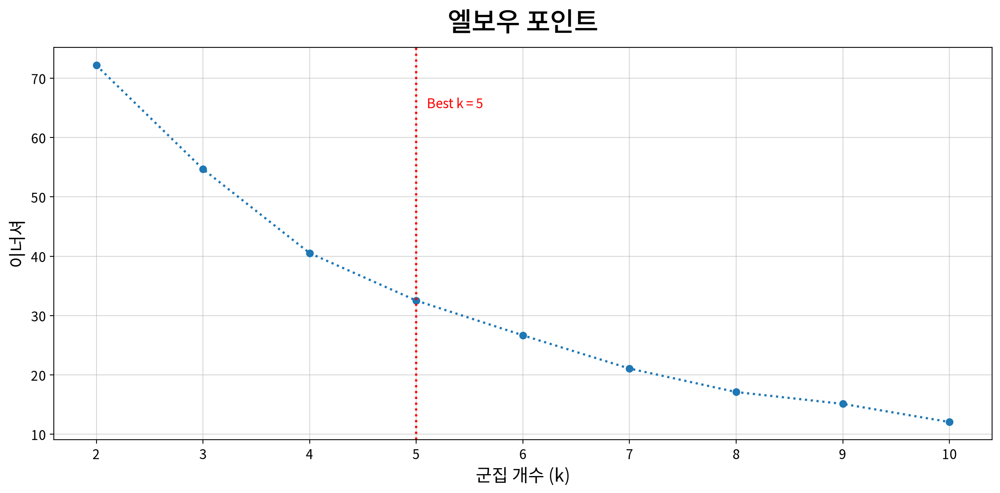

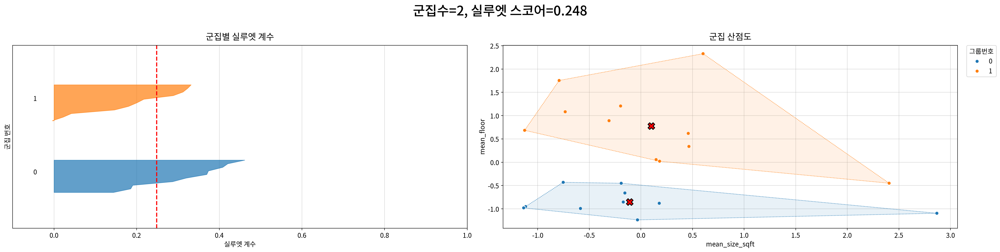

[1단계] 엘보우 포인트   : k = 5  (뭉침만 확인 → 후보)
[2단계] 실루엣 균형지수 : k = 2  (뭉침 + 분리 + 크기 균형)
------------------------------------------------------------
두 지표가 다른 k를 가리킵니다.
  · k = 5 : 균형지수 0.0 (스코어 0.2429, 두께비 9.0)
  · k = 2 : 균형지수 0.1782 (스코어 0.2484, 두께비 1.1)
------------------------------------------------------------
>>> 최종 선택: k = 2
    (지표는 후보를 좁혀줄 뿐이므로, 목적과 도메인 지식으로 한 번 더 확인할 것)


(2,
     k    이너셔    감소량   스코어  전체면적   두께비  최소상대면적  균형지수
 0   2 72.164    NaN 0.248 5.216 1.100   0.789 0.178
 1   3 54.682 17.481 0.290 6.095 5.000   0.386 0.022
 2   4 40.524 14.159 0.289 6.071 9.000   0.000 0.000
 3   5 32.524  8.000 0.243 5.101 9.000   0.000 0.000
 4   6 26.667  5.857 0.221 4.643 8.000   0.000 0.000
 5   7 21.065  5.603 0.222 4.655 5.000   0.000 0.000
 6   8 17.108  3.957 0.219 4.594 4.000   0.000 0.000
 7   9 15.112  1.996 0.208 4.367 4.000   0.000 0.000
 8  10 12.058  3.054 0.169 3.546 4.000   0.000 0.000)

In [31]:
neigh_profile = (
    df.groupby("neighborhood_group", observed=True)
      .agg(
          listing_count=("neighborhood_group", "size"),
          mean_size_sqft=("size_sqft", "mean"),
          mean_floor=("floor", "mean"),
          mean_building_age=("building_age_yrs", "mean"),
          mean_subway_min=("min_to_subway", "mean"),
          mean_amenity_count=("amenity_count", "mean"),
      )
      .reset_index()
)

cluster_cols = [
    "mean_size_sqft",
    "mean_floor",
    "mean_building_age",
    "mean_subway_min",
    "mean_amenity_count",
]

my_cluster.best_k(neigh_profile,
    columns=cluster_cols,
    scaling="standard",
    plot=True,
    plot_each=False,)

#### **최적 군집 수 선정 결과**
- **k=5**가 주요 후보로 나타났으며, Silhouette 분석에서는 **k=2**가 가장 높은 균형지수와 실루엣 점수를 보였다. 실제로 k=2의 Silhouette Score는 0.2484로, k=5의 0.2429보다 높았다.
- 그러나 본 분석은 단순히 통계적으로 가장 잘 분리되는 군집을 찾는 것뿐만 아니라, **맨해튼 임대시장의 지역별 특성을 해석하는 것**을 목적으로 한다.

- StreetEasy는 Manhattan 임대시장을 **Downtown, Midtown, Upper East Side, Upper West Side, Upper Manhattan의 5개 상위 시장권역(Submarket)**으로 구분하여 분석하고 있다. 
    - k=5는 군집 구조와 실제 부동산 시장에서 활용되는 지역 구분 체계를 동시에 반영할 수 있다.

> 이에 따라 **통계적 군집 구조와 도메인 해석 가능성을 종합적으로 고려하여 최종 군집 수를 k=5로 선정하였다.**

##### #최적 군집 수를 적용해 동네 권역 군집 생성

StandardScaler 적용 (5개 컬럼)
컬럼                            변환 전                  변환 후
--------------------------------------------------------
mean_size_sqft    768.04 ~ 1396.84          -1.14 ~ 2.87
mean_floor          3.11 ~ 23.20          -1.24 ~ 2.33
mean_building_age       20.40 ~ 84.50          -2.03 ~ 1.49
mean_subway_min        2.17 ~ 11.66          -1.05 ~ 3.37
mean_amenity_count         0.19 ~ 1.92          -2.80 ~ 1.82


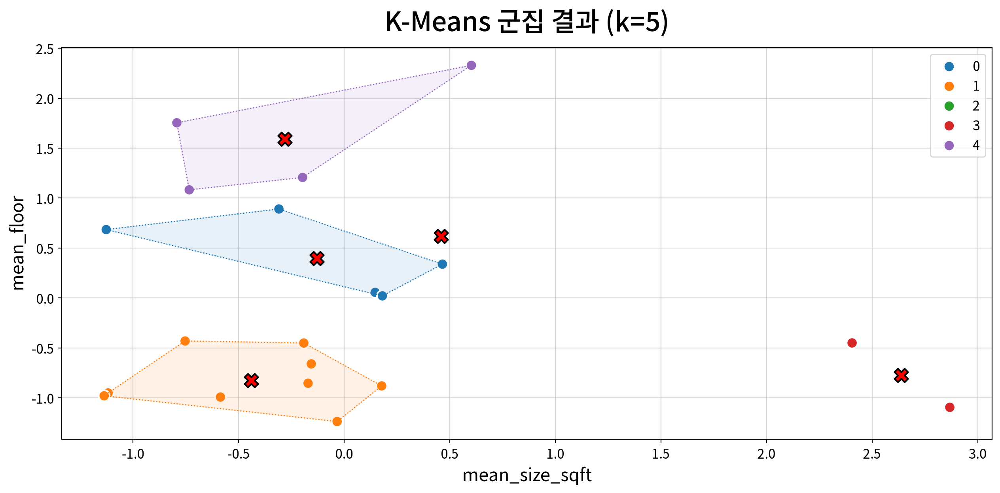

In [32]:
cluster_result = my_cluster.kmeans(
    neigh_profile,
    k=5,
    columns=cluster_cols,
    scaling="standard",
    cluster_name="지역군집",
    plot=True)

##### 

#### #권역별 매물 수 · 평균 월세 확인

In [33]:
# kmeans 반환 튜플에서 군집 결과 DataFrame 추출
cluster_df = next(
    item for item in cluster_result
    if isinstance(item, pd.DataFrame)
)

display(cluster_df)

,mean_size_sqft,mean_floor,mean_building_age,mean_subway_min,mean_amenity_count,지역군집
0,0.459,0.619,-2.033,3.370,1.409,2
1,-0.171,-0.854,0.907,-0.306,-1.280,1
2,0.147,0.056,-0.960,-0.352,0.103,0
3,-1.118,-0.951,-0.193,0.082,0.181,1
4,-1.137,-0.979,0.602,0.225,-1.239,1
5,-0.734,1.082,0.462,-0.940,0.166,4
6,-0.197,1.206,-1.432,-1.047,0.088,4
7,-0.753,-0.431,-0.235,0.597,-1.015,1
8,-0.156,-0.660,1.494,-0.818,0.675,1
9,0.178,-0.880,0.728,0.541,0.292,1


##### 군집별 동네 수 확인

In [34]:
# 각 지역군집에 몇 개의 동네가 포함됐는지 확인
cluster_df["지역군집"].value_counts().sort_index()

지역군집
0    5
1    9
2    1
3    2
4    4
Name: count, dtype: int64

In [35]:
# neigh_profile에 k=5 군집 번호 연결
neigh_clustered = neigh_profile.copy()

neigh_clustered["지역군집"] = cluster_df["지역군집"].values

display(neigh_clustered.head())

,neighborhood_group,listing_count,mean_size_sqft,mean_floor,mean_building_age,mean_subway_min,mean_amenity_count,지역군집
0,Battery Park City,104,1018.538,13.567,20.404,11.663,1.760,2
1,Central Harlem,81,919.654,5.272,73.840,3.765,0.753,1
2,Chelsea,181,969.569,10.398,39.917,3.669,1.271,0
3,East Harlem,40,770.975,4.725,53.850,4.600,1.300,1
4,East Village,108,768.037,4.565,68.296,4.907,0.769,1


In [ ]:
# 동네별 최종 지역군집 번호 추출
cluster_map = neigh_clustered[["neighborhood_group", "지역군집"]].copy()

display(cluster_map.head())

,neighborhood_group,지역군집
0,Battery Park City,2
1,Central Harlem,1
2,Chelsea,0
3,East Harlem,1
4,East Village,1


In [ ]:
# 원본 매물 데이터에 지역군집 번호 연결
df_cluster = df.merge(cluster_map, on="neighborhood_group", how="left")

display(df_cluster.head())

,rent,bedrooms,bathrooms,size_sqft,min_to_subway,floor,building_age_yrs,no_fee,has_roofdeck,has_washer_dryer,has_doorman,has_elevator,has_dishwasher,has_patio,has_gym,neighborhood,size_per_room,amenity_count,size_neigh_ratio,floor_neigh_ratio,room_size_neigh_ratio,amenity_neigh_ratio,neighborhood_group,지역군집
0,2550,0.000,1,480,9,2.000,17,1,1,0,0,1,1,0,1,Upper East Side,480.000,4,0.471,0.167,1.327,2.718,Upper East Side,0
1,11500,2.000,2,2000,4,1.000,96,0,0,0,0,0,0,0,0,Greenwich Village,500.000,0,2.169,0.157,1.104,0.000,Greenwich Village,1
2,4500,1.000,1,916,2,51.000,29,0,1,0,1,1,1,0,0,Midtown,458.000,4,0.880,2.198,1.117,2.088,Midtown,4
3,4795,1.000,1,975,3,8.000,31,0,0,0,1,1,1,0,1,Greenwich Village,487.500,4,1.057,1.257,1.076,2.694,Greenwich Village,1
4,17500,2.000,2,4800,3,4.000,136,0,0,0,1,1,1,0,1,Soho,1200.000,4,3.436,1.022,2.782,2.974,Soho,3


In [41]:
# 지역군집별 매물 수와 평균 월세 확인
cluster_summary = (df_cluster.groupby("지역군집", observed=True)
    .agg(매물수=("rent", "size"), 평균월세=("rent", "mean")).round(2))

display(cluster_summary)

,매물수,평균월세
지역군집,,
0,2015,5138.520
1,614,4274.030
2,104,5968.960
3,177,8136.610
4,600,5027.850


##### 각 권역 동네 나열

In [45]:
# 지역군집별 포함된 동네 목록 확인
cluster_neighborhoods = (df_cluster.groupby("지역군집", observed=True)["neighborhood_group"].unique())

for cluster, neighborhoods in cluster_neighborhoods.items():
    print(f"[지역군집 {cluster}]")
    print(", ".join(neighborhoods))
    print()

[지역군집 0]
Upper East Side, Midtown East, Midtown West, Upper West Side, Chelsea

[지역군집 1]
Greenwich Village, Central Harlem, East Village, Lower East Side, Gramercy Park, East Harlem, West Village, Other, Washington Heights

[지역군집 2]
Battery Park City

[지역군집 3]
Soho, Tribeca

[지역군집 4]
Midtown, Flatiron, Financial District, Midtown South



#### #지역군집별 군집분석 변수의 평균 특성 확인

In [47]:
cluster_profile = (
    df_cluster.groupby("지역군집", observed=True)
    .agg(
        평균면적=("size_sqft", "mean"),
        평균층=("floor", "mean"),
        평균건물연식=("building_age_yrs", "mean"),
        평균지하철거리=("min_to_subway", "mean"),
        평균편의시설수=("amenity_count", "mean")
    ).round(2)
)

display(cluster_profile)

,평균면적,평균층,평균건물연식,평균지하철거리,평균편의시설수
지역군집,,,,,
0,936.300,12.340,47.160,5.810,1.350
1,872.430,5.540,71.880,4.160,0.970
2,1018.540,13.570,20.400,11.660,1.760
3,1347.990,6.360,58.420,2.820,1.440
4,889.780,18.250,51.180,2.420,1.390


#### # 권역별 구성 동네 목록과 매물 수·평균 월세 표

In [49]:
cluster_analysis = cluster_profile.join(cluster_summary)

display(cluster_analysis)

,평균면적,평균층,평균건물연식,평균지하철거리,평균편의시설수,매물수,평균월세
지역군집,,,,,,,
0,936.300,12.340,47.160,5.810,1.350,2015,5138.520
1,872.430,5.540,71.880,4.160,0.970,614,4274.030
2,1018.540,13.570,20.400,11.660,1.760,104,5968.960
3,1347.990,6.360,58.420,2.820,1.440,177,8136.610
4,889.780,18.250,51.180,2.420,1.390,600,5027.850


##### #지역군집 번호를 해석 가능한 권역명으로 변환

In [52]:
region_name_map = {
    0: "중심부 주거·상업 혼합권",
    1: "생활형 주거 혼합권",
    2: "신도심 워터프런트 주거권",
    3: "다운타운 프리미엄 주거권",
    4: "도심 업무·주거 복합권",
}

df_cluster["권역명"] = df_cluster["지역군집"].map(region_name_map)
df_cluster[["neighborhood_group", "지역군집", "권역명"]].drop_duplicates()

,neighborhood_group,지역군집,권역명
0,Upper East Side,0,중심부 주거·상업 혼합권
1,Greenwich Village,1,생활형 주거 혼합권
2,Midtown,4,도심 업무·주거 복합권
4,Soho,3,다운타운 프리미엄 주거권
5,Central Harlem,1,생활형 주거 혼합권
6,Battery Park City,2,신도심 워터프런트 주거권
7,Flatiron,4,도심 업무·주거 복합권
10,Midtown East,0,중심부 주거·상업 혼합권
11,East Village,1,생활형 주거 혼합권
12,Midtown West,0,중심부 주거·상업 혼합권


#### #범주형 파생변수 생성
- 역세권 여부 ― 도보 15분 이내
- 신축 여부 ― 준공 5년 이내 : 신축 | 준공 5 ~ 10년 이내 : 준신축 | 준공 10년 이상 : 구축

In [63]:
# 역세권 여부
df["is_station_area"] = np.where(
    df["min_to_subway"] <= 15,
    "역세권",
    "비역세권"
)

# 건물 연식 구분 (신축 | 준신축 | 구축)
df["building_age_group"] = np.where(
    df["building_age_yrs"] <= 5,
    "신축",
    np.where(
        df["building_age_yrs"] <= 10,
        "준신축",
        "구축"
    )
)


# 새로 만든 파생변수를 범주형으로 변환
df = my_qtcheck.set_type(df, as_category=["is_station_area", "building_age_group"])

df[[
    "min_to_subway",
    "is_station_area",
    "building_age_yrs",
    "building_age_group"
]].head()

<class 'pandas.core.frame.DataFrame'>
Index: 3510 entries, 0 to 3538
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   rent                   3510 non-null   int64   
 1   bedrooms               3510 non-null   float64 
 2   bathrooms              3510 non-null   int64   
 3   size_sqft              3510 non-null   int64   
 4   min_to_subway          3510 non-null   int64   
 5   floor                  3510 non-null   float64 
 6   building_age_yrs       3510 non-null   int64   
 7   no_fee                 3510 non-null   category
 8   has_roofdeck           3510 non-null   category
 9   has_washer_dryer       3510 non-null   category
 10  has_doorman            3510 non-null   category
 11  has_elevator           3510 non-null   category
 12  has_dishwasher         3510 non-null   category
 13  has_patio              3510 non-null   category
 14  has_gym                3510 non-null   catego

,min_to_subway,is_station_area,building_age_yrs,building_age_group
0,9,역세권,17,구축
1,4,역세권,96,구축
2,2,역세권,29,구축
3,3,역세권,31,구축
4,3,역세권,136,구축


##### 컬럼에 새로 생성한 파생변수 추가

In [70]:
column_means.update({"is_station_area": "역세권 여부", "building_age_group": "건물 연식 구분"})

#### 범주형 파생변수 점검

##### 생성한 범주형 파생변수 결측치 확인

In [71]:
# 생성한 범주형 파생변수 점검
display(Markdown("### 범주형 파생변수 자료형 확인"))

print(df[[
    "is_station_area",
    "building_age_group"
]].dtypes)


display(Markdown("### 범주형 파생변수에 결측값이 있는지 확인"))

check = df[[
    "is_station_area",
    "building_age_group"
]]

print(check.isna().sum())


display(Markdown("### 역세권 여부 분포 확인"))

print(df["is_station_area"].value_counts())


display(Markdown("### 건물 연식 구분 분포 확인"))

print(df["building_age_group"].value_counts())

### 범주형 파생변수 자료형 확인

is_station_area       category
building_age_group    category
dtype: object


### 범주형 파생변수에 결측값이 있는지 확인

is_station_area       0
building_age_group    0
dtype: int64


### 역세권 여부 분포 확인

is_station_area
역세권     3449
비역세권      61
Name: count, dtype: int64


### 건물 연식 구분 분포 확인

building_age_group
구축     2919
준신축     408
신축      183
Name: count, dtype: int64


#### 범주형 파생변수 생성

| 관점 | 기준 | 이름 |
|---|---|---|
| **지하철 접근성이 좋은 역세권인가** | 지하철 도보 **15분 이하 → 역세권**, 15분 초과 → 비역세권 | `is_station_area` |
| **건물 연식이 어느 수준인가** | 준공 후 **5년 이하 → 신축**, 5년 초과~10년 이하 → 준신축, 10년 초과 → 구축 | `building_age_group` |

### 발견사항 목록, 미션 6

> "동네 32개를 다시 그린다"

**해석**

- **최적 군집수 판단**: 전체 32개 동네 중 매물 수가 전체의 1%인 **35.1개 미만인 12개 희소 동네를 `Other`로 병합**하여 총 **21개 수준**으로 축소하였다. 엘보우 포인트에서는 **k=5**, 실루엣 균형지수에서는 **k=2**가 제시되었다. 실루엣 스코어는 k=2가 **0.2484**, k=5가 **0.2429**로 k=2가 조금 높았으나, 뉴욕 맨해튼 임대시장의 지역별 특성을 해석하려는 분석 목적과 5개 상위 시장권역 구조를 고려하여 **최종 군집수는 k=5로 선정**하였다.

- **권역별 매물수와 평균월세의 묶임 판단**: 군집별 매물수와 평균월세는 **0번 2,015개/5,138.52, 1번 614개/4,274.03, 2번 104개/5,968.96, 3번 177개/8,136.61, 4번 600개/5,027.85**로 나타났다. 특히 1번 군집은 평균월세가 가장 낮고, 3번 군집은 가장 높아 권역별 임대시장 특성의 차이가 확인되었다.

- **각 권역 동네 명명**

| 지역군집 | 권역명 | 구성 동네 |
|:---:|---|---|
| 0 | 중심부 주거·상업 혼합권 | Upper East Side, Midtown East, Midtown West, Upper West Side, Chelsea |
| 1 | 생활형 주거 혼합권 | Greenwich Village, Central Harlem, East Village, Lower East Side, Gramercy Park, East Harlem, West Village, Other, Washington Heights |
| 2 | 신도심 워터프런트 주거권 | Battery Park City |
| 3 | 다운타운 프리미엄 주거권 | Soho, Tribeca |
| 4 | 도심 업무·주거 복합권 | Midtown, Flatiron, Financial District, Midtown South |


 **<최종 인사이트>**
>
> - 32개 동네의 희소 수준을 병합한 뒤 면적, 층수, 건물연식, 지하철 거리, 편의시설 수를 기준으로 군집분석한 결과, 맨해튼 임대시장을 **5개의 서로 다른 특성을 가진 권역**으로 재구성할 수 있었다. 특히 **다운타운 프리미엄 주거권의 평균월세가 8,136.61로 가장 높았고**, 생활형 주거 혼합권은 **4,274.03으로 가장 낮아** 권역에 따른 임대시장 차이가 확인되었다. 추가로 **도보 15분 이하를 역세권**, 건물연식은 **5년 이하 신축·5년 초과~10년 이하 준신축·10년 초과 구축**으로  범주화하여 이후 지역 및 임대료 특성을 비교할 수 있는 파생변수를 생성하였다.
    - 건물 연식은 부동산 시장에서 통상적으로 활용되는 구분을 참고하여, 준공 후 5년 이하를 신축, 5년 초과~10년 이하를 준신축, 10년 초과를 구축으로 분류하였다. 해당 기준은 법적 공식 기준이 아닌 시장 관행에 따른 구분이다.
    
     > 출처: 집품 콘텐츠팀(2026), *구축 vs 신축 vs 준신축 아파트 차이 | 아파트 연식 기준 완벽 정리*. [원문 보기](https://zippoom.com/%EB%B8%94%EB%A1%9C%EA%B7%B8/%EA%B5%AC%EC%B6%95-%EC%8B%A0%EC%B6%95-%ED%8A%B9%EC%A7%95-%EC%B0%A8%EC%9D%B4%EC%A0%90/339)

### #생성한 파생변수 전체 점검
- 연속형 파생 → 종속변수 : 상관분석 (강도·부호·유의성)
- 2집단 범주형 파생 → 종속변수 : 두 집단 평균 비교
- 3집단 이상 범주형 파생 → 종속변수 : 분산분석 + 사후검정
- 파생변수끼리 : 상관행렬로 중복 점검

##### 파생변수 EDA 범위 정리

| 종속유형 | 파생변수 유형 | 분석 유형 | 대상 변수 | 적용 여부 | 비고 |
|---|---|---|---|:---:|---|
| 연속형 | 연속형 | 상관분석 | 연속형 파생변수 6종 ↔ `rent` | ✅ 적용 | 강도·부호·유의성 확인 |
| 연속형 | 명목형(2집단) | 두 집단 비교 | `is_station_area` → `rent` | ✅ 적용 | 역세권·비역세권 간 임대료 차이 확인 |
| 연속형 | 명목형(3집단) | ANOVA + 사후검정 | `building_age_group` → `rent` | ✅ 적용 | 신축·준신축·구축 간 임대료 차이 확인 |
| 연속형 | 연속형 | 상관행렬 | 연속형 파생변수 6종 ↔ 파생변수 6종 | ✅ 적용 | 파생변수 간 중복 및 높은 상관관계 확인 |

- 종속변수는 연속형 `rent(임대료)`이며, 생성한 파생변수와의 관계를 탐색하여 **모델링 최종 투입 변수를 선정**한다.
- **연속형 파생변수 6종:** `size_per_room`, `amenity_count`, `size_neigh_ratio`, `floor_neigh_ratio`, `room_size_neigh_ratio`, `amenity_neigh_ratio`
- **2집단 범주형 파생변수 1종:** `is_station_area` (역세권 / 비역세권)
- **3집단 범주형 파생변수 1종:** `building_age_group` (신축 / 준신축 / 구축)
- **파생변수 간 중복 점검:** 연속형 파생변수 6종의 상관행렬을 확인하여 유사한 정보를 갖는 변수의 중복 가능성을 검토한다.

#### 1) 파생변수 ▶ 연속형 독립변수에 대한 단변량 분석

In [76]:
# 연속형 파생변수 컬럼 목록
derived_continuous_cols = [
    'size_per_room',
    'amenity_count',
    'size_neigh_ratio',
    'floor_neigh_ratio',
    'room_size_neigh_ratio',
    'amenity_neigh_ratio'
]

In [82]:
# 연속형 파생변수 기술통계량 생성
derived_num_desc = my_qtcheck.numerical_summary(df[derived_continuous_cols])
derived_num_desc

,count,mean,std,min,25%,50%,75%,max,rel_diff,rdiff_flag,iqr,upper_bound,lower_bound,upper_outliers,upper_outliers_ratio,lower_outliers,lower_outliers_ratio,outliers,outliers_ratio,skew,skew_interpret,kurt,kurt_interpret,log_need
size_per_room,3510.000,373.432,118.452,124.000,300.000,350.000,425.000,1800.000,0.067,similar,125.000,612.500,112.500,108,0.031,0,0.000,108,0.031,2.342,right_tail,15.058,leptokurtic,log1p
amenity_count,3510.000,1.307,1.843,0.000,0.000,0.000,2.000,7.000,inf,large_diff,2.000,5.000,-3.000,131,0.037,0,0.000,131,0.037,1.198,right_tail,0.159,leptokurtic,log1p
size_neigh_ratio,3510.000,1.000,0.480,0.200,0.669,0.872,1.208,4.782,0.147,diff,0.539,2.017,-0.140,155,0.044,0,0.000,155,0.044,1.686,right_tail,4.365,leptokurtic,log1p
floor_neigh_ratio,3510.000,1.000,0.794,0.000,0.404,0.784,1.373,7.941,0.275,diff,0.968,2.825,-1.048,130,0.037,0,0.000,130,0.037,1.702,right_tail,4.948,leptokurtic,log1p
room_size_neigh_ratio,3510.000,1.000,0.296,0.343,0.807,0.948,1.136,4.688,0.054,similar,0.329,1.630,0.314,110,0.031,0,0.000,110,0.031,1.992,right_tail,12.220,leptokurtic,log1p
amenity_neigh_ratio,3510.000,0.999,1.522,0.000,0.000,0.000,1.935,27.000,inf,large_diff,1.935,4.837,-2.902,61,0.017,0,0.000,61,0.017,2.904,right_tail,27.701,leptokurtic,log1p


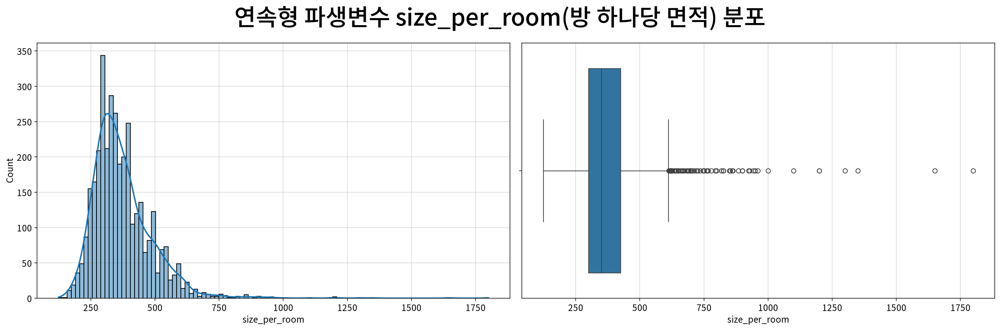

,size_per_room
count,3510.000
mean,373.432
std,118.452
min,124.000
25%,300.000
50%,350.000
75%,425.000
max,1800.000
rel_diff,0.067
rdiff_flag,similar


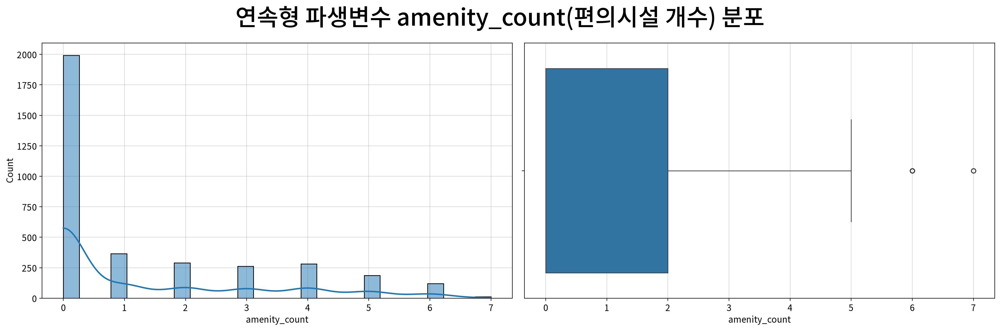

,amenity_count
count,3510.000
mean,1.307
std,1.843
min,0.000
25%,0.000
50%,0.000
75%,2.000
max,7.000
rel_diff,inf
rdiff_flag,large_diff


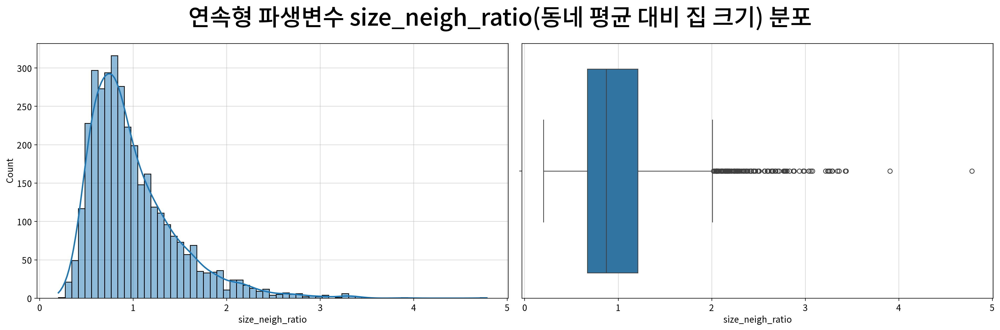

,size_neigh_ratio
count,3510.000
mean,1.000
std,0.480
min,0.200
25%,0.669
50%,0.872
75%,1.208
max,4.782
rel_diff,0.147
rdiff_flag,diff


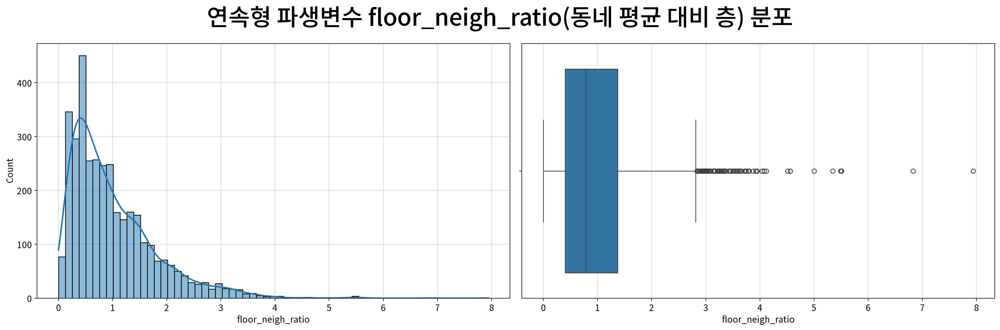

,floor_neigh_ratio
count,3510.000
mean,1.000
std,0.794
min,0.000
25%,0.404
50%,0.784
75%,1.373
max,7.941
rel_diff,0.275
rdiff_flag,diff


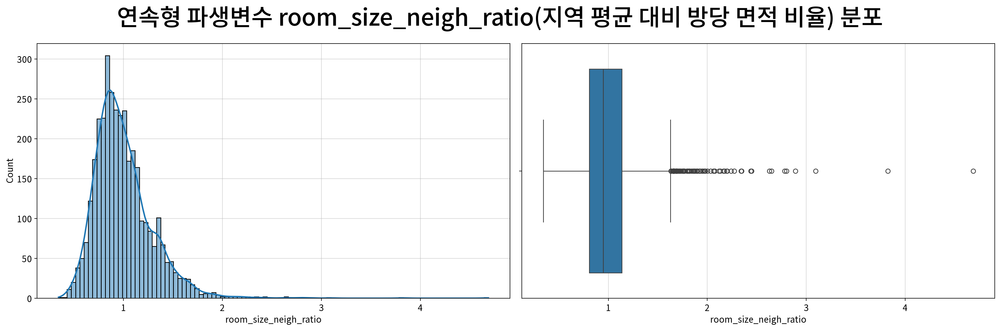

,room_size_neigh_ratio
count,3510.000
mean,1.000
std,0.296
min,0.343
25%,0.807
50%,0.948
75%,1.136
max,4.688
rel_diff,0.054
rdiff_flag,similar


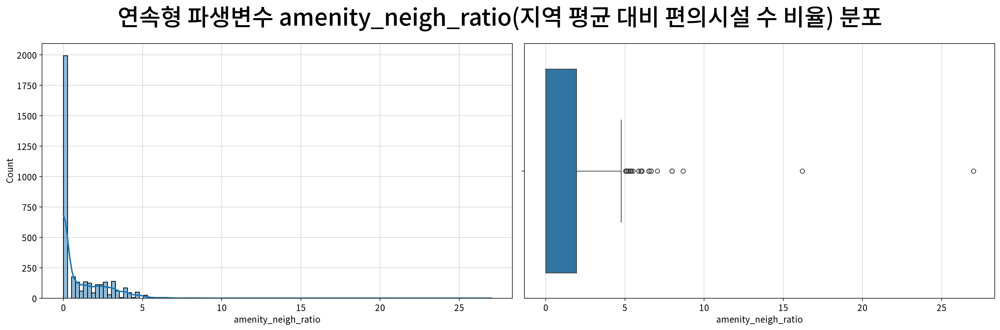

,amenity_neigh_ratio
count,3510.000
mean,0.999
std,1.522
min,0.000
25%,0.000
50%,0.000
75%,1.935
max,27.000
rel_diff,inf
rdiff_flag,large_diff


In [84]:
for c in derived_continuous_cols:
    fig, ax = my_plot.init(rows=1, cols=2, width=960, height=640,
                           title=f"연속형 파생변수 {c}({column_means[c]}) 분포")
    my_plot.histplot(data=df, x=c, kde=True, ax=ax[0])
    my_plot.boxplot(data=df, x=c, ax=ax[1])
    my_plot.show()

    display(derived_num_desc[derived_num_desc.index == c].T)

#### 2) 파생변수 ▶ 명목형 독립변수에 대한 단변량 분석

In [77]:
# 범주형 파생변수 컬럼 목록
derived_categorical_cols = [
    'is_station_area',
    'building_age_group'
]

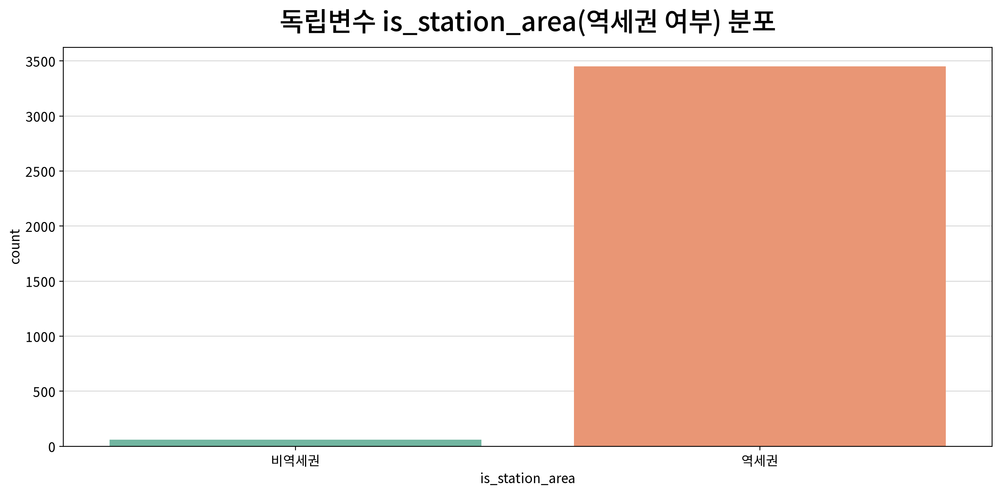

,count,unique,top,freq
is_station_area,3510,2,역세권,3449


,빈도,비율
is_station_area,,
역세권,3449,0.983
비역세권,61,0.017


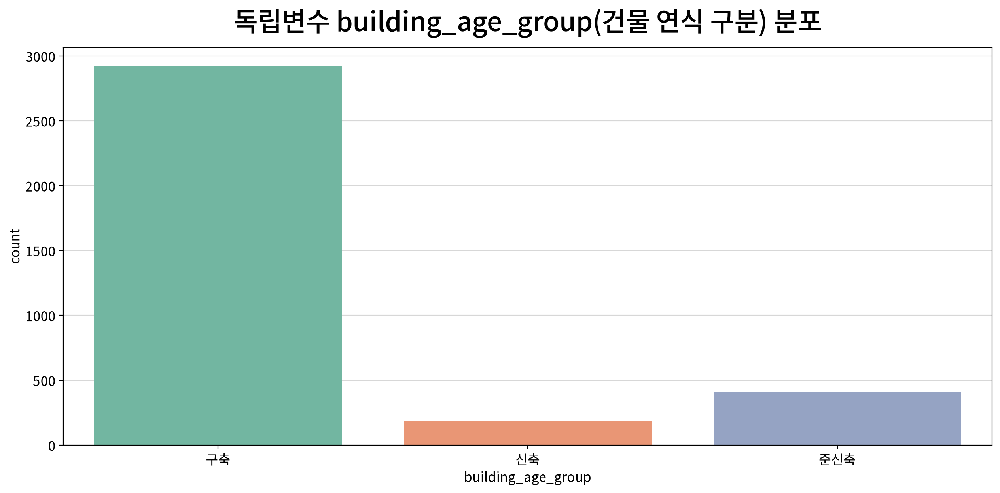

,count,unique,top,freq
building_age_group,3510,3,구축,2919


,빈도,비율
building_age_group,,
구축,2919,0.832
준신축,408,0.116
신축,183,0.052


In [80]:
# 범주형 파생변수 기술통계량 생성
derived_cat_desc = df[derived_categorical_cols].describe(include='all')

# 범주형 파생변수 단변량 분석
for n in derived_categorical_cols:
    ## 명목형 분포는 카운트 플롯으로 처리한다.
    my_plot.countplot(data=df, x=n, hue=n, palette="Set2", title=f"독립변수 {n}({column_means[n]}) 분포")

    ## 명목형 기술통계량
    display(derived_cat_desc[[n]].T)

    ## 추가적으로 빈도표 생성
    freq = df[n].value_counts().rename("빈도").to_frame()
    ## value_counts(normalize=True)
    ## --> 전체 고유값의 개수(빈도수) 대신 전체 데이터의 비율을 계산
    freq["비율"] = df[n].value_counts(normalize=True)

    display(freq)

**검정 결과**

| 변수 | 분포 모양(왜도) | 봉우리·집중 구간 | 이상치 | 판단·조치 |
|---|---|---|---|---|
| `size_per_room` | **강한 우편향 (+2.342)** | 약 300~400 부근에 집중 | 108건(3.1%) | **로그 변환(`log1p`) 검토** — 우측 꼬리가 길고 첨도가 높음 |
| `amenity_count` | **우편향 (+1.198)** | 0개에 가장 많이 집중 | 131건(3.7%) | **로그 변환(`log1p`) 검토** — 0을 포함하고 우편향이 확인됨 |
| `size_neigh_ratio` | **우편향 (+1.686)** | 약 0.7~1.0 부근에 집중 | 155건(4.4%) | **로그 변환(`log1p`) 검토** — 우측 꼬리와 상단 이상치가 확인됨 |
| `floor_neigh_ratio` | **우편향 (+1.702)** | 약 0.3~1.0 부근에 집중 | 130건(3.7%) | **로그 변환(`log1p`) 검토** — 0을 포함하고 우측 꼬리가 길게 나타남 |
| `room_size_neigh_ratio` | **우편향 (+1.992)** | 약 0.8~1.1 부근에 집중 | 110건(3.1%) | **로그 변환(`log1p`) 검토** — 우측 꼬리와 높은 첨도가 확인됨 |
| `amenity_neigh_ratio` | **강한 우편향 (+2.904)** | 0에 가장 많이 집중 | 61건(1.7%) | **로그 변환(`log1p`) 검토** — 0을 포함하고 매우 긴 우측 꼬리가 나타남 |
| `is_station_area` | 범주형 | 역세권 98.3%에 집중 | — | **변환 불필요** — 역세권/비역세권 범주형 변수로 라벨링 대상 |
| `building_age_group` | 범주형 | 구축 83.2%에 집중 | — | **변환 불필요** — 신축/준신축/구축 범주형 변수로 라벨링 대상 |

#### 3) 파생변수 ▶ 상관분석(x: 연속형 독립변수 → y: 연속형 종속변수)

##### ▶︎ size_per_room(방 하나당 면적) → rent

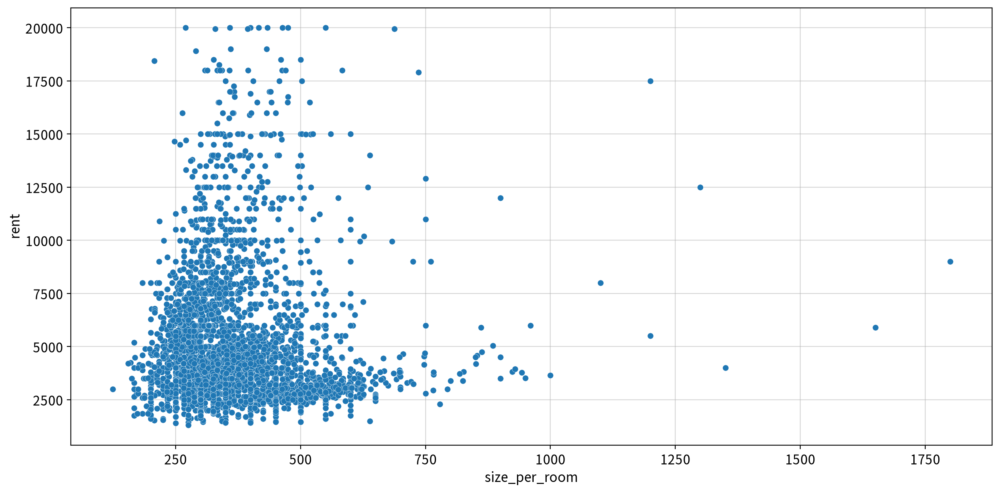

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential
x,y,,,,,,,,,
size_per_room,rent,Spearman,-0.097,0.000,Weak,True,False,False,True,True


##### ▶︎ amenity_count(편의시설 개수) → rent

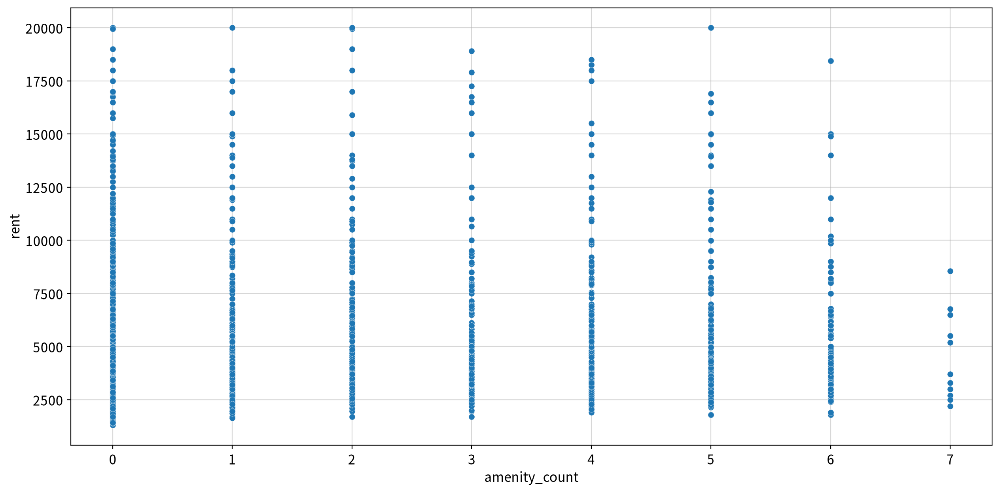

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential
x,y,,,,,,,,,
amenity_count,rent,Spearman,0.080,0.000,Weak,True,False,False,False,True


##### ▶︎ size_neigh_ratio(동네 평균 대비 집 크기) → rent

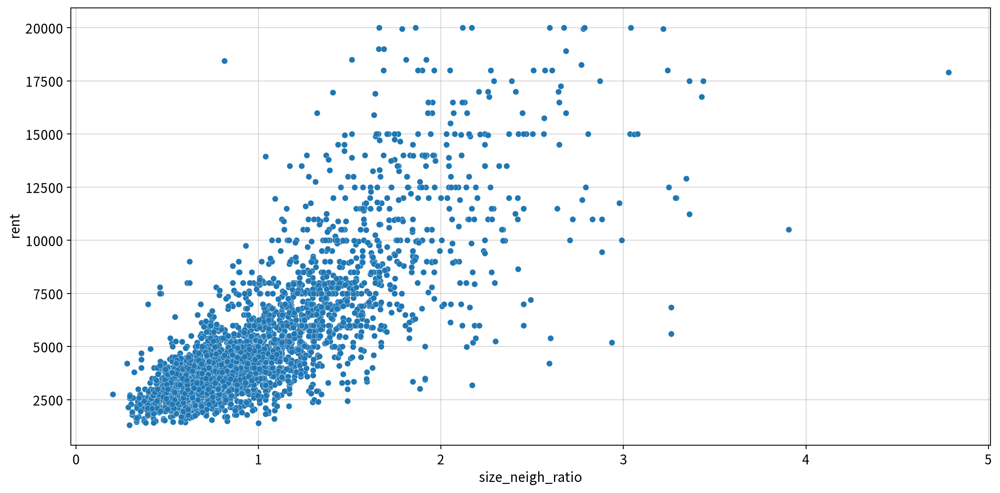

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential
x,y,,,,,,,,,
size_neigh_ratio,rent,Spearman,0.783,0.000,Strong,True,False,False,False,True


##### ▶︎ floor_neigh_ratio(동네 평균 대비 층) → rent

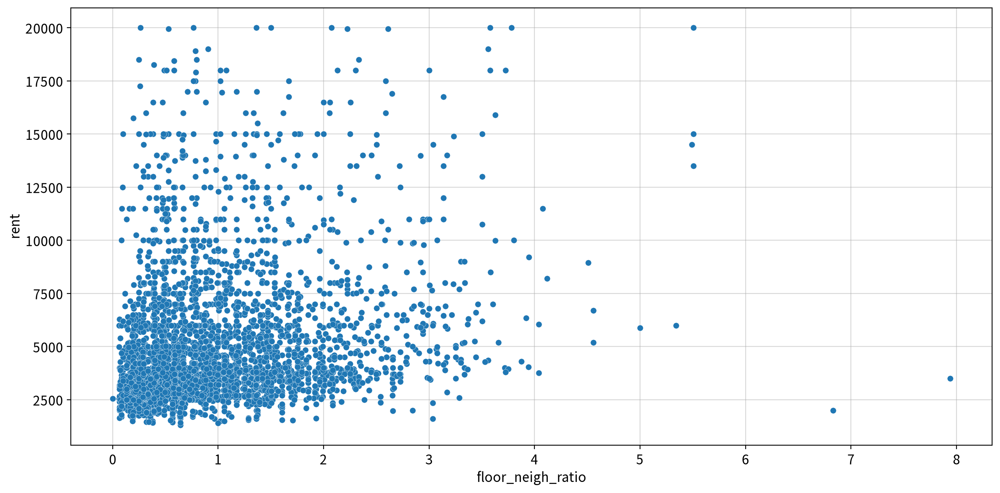

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential
x,y,,,,,,,,,
floor_neigh_ratio,rent,Spearman,0.287,0.000,Weak,True,False,False,True,True


##### ▶︎ room_size_neigh_ratio(지역 평균 대비 방당 면적 비율) → rent

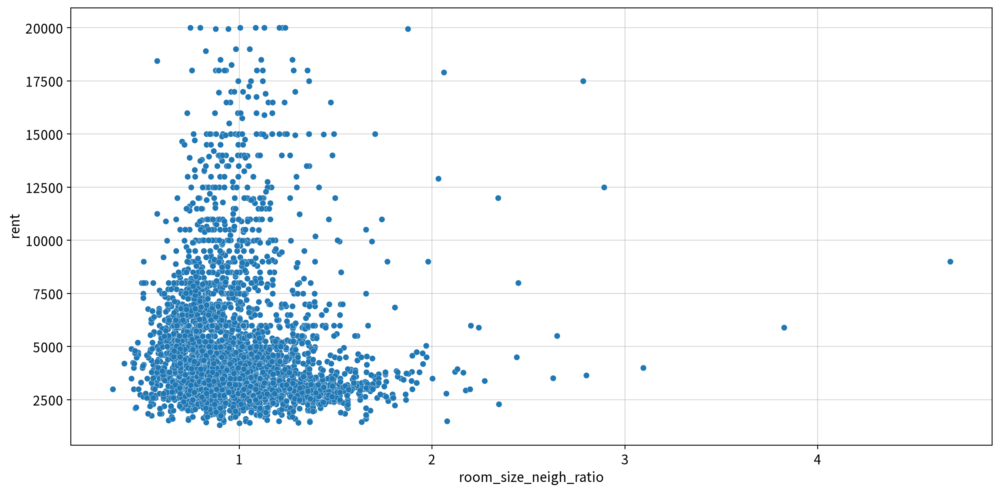

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential
x,y,,,,,,,,,
room_size_neigh_ratio,rent,Spearman,-0.178,0.000,Weak,True,False,False,False,True


##### ▶︎ amenity_neigh_ratio(지역 평균 대비 편의시설 수 비율) → rent

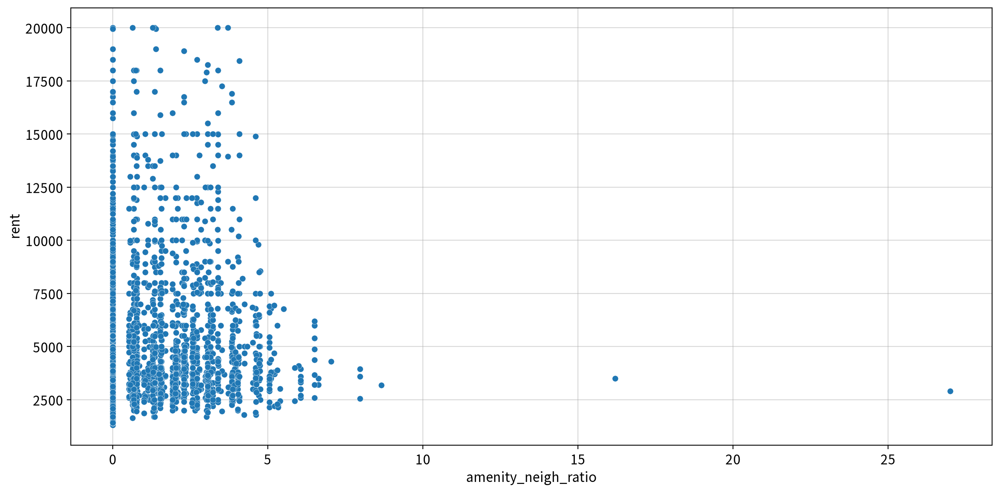

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential
x,y,,,,,,,,,
amenity_neigh_ratio,rent,Spearman,0.071,0.000,Weak,True,False,False,False,True


In [ ]:
for f in derived_continuous_cols:
    ## 빈 줄 출력용
    print()

    ## 분석 단위 제목 출력
    display(Markdown(f"##### ▶︎ {f}({column_means[f]}) → {target}"))

    ## 시각화
    my_plot.scatterplot(data=df, x=f, y=target, outline=False,
                        ## 데이터 밀도에 따라 외곽선 굵기와 점 크기 조절
                        linewidth=0.2, size=30)

    ## my_stats는 시각화까지 일괄처리 한다.
    display(my_stats.correlation(df, x=f, y=target, plot=False))


**검정 결과**

| 변수 | 선형/비선형 | 단조성 | 산포 | 이상치·특이점 | 채택 여부 |
|---|---|---|---|---|---|
| `size_per_room` | 선형성 있음 | 약한 음의 단조↓ (ρ = -0.097, 약함) | 동일 구간에서도 임대료 산포가 큼 | 고가 매물 및 큰 방당 면적의 일부 이상치 관찰 | 🟡 보류 |
| `amenity_count` | 뚜렷한 선형 없음 | 매우 약한 양의 단조↑ (ρ = +0.080, 약함) | 편의시설 개수별 임대료 편차가 큼 | 모든 개수 구간에서 고가 매물 관찰 | 🟡 보류 |
| `size_neigh_ratio` | 뚜렷한 선형 없음 | 강한 양의 단조↑ (ρ = +0.783, 강함) | 비율이 증가할수록 임대료 산포도 확대 | 높은 비율 구간의 일부 특이 매물 관찰 | ✅ 채택 |
| `floor_neigh_ratio` | 선형성 있음 | 약한 양의 단조↑ (ρ = +0.287, 약함) | 같은 비율에서도 임대료 차이가 큼 | 매우 높은 비율의 일부 특이점 관찰 | 🟡 보류 |
| `room_size_neigh_ratio` | 뚜렷한 선형 없음 | 약한 음의 단조↓ (ρ = -0.178, 약함) | 1 전후 구간에 밀집하며 임대료 편차가 큼 | 큰 비율의 일부 이상치 관찰 | 🟡 보류 |
| `amenity_neigh_ratio` | 뚜렷한 선형 없음 | 매우 약한 양의 단조↑ (ρ = +0.071, 약함) | 낮은 비율 구간에 밀집하며 산포가 큼 | 매우 높은 비율의 일부 특이점 관찰 | 🟡 보류 |

- 6개 연속형 파생변수 중 `size_neigh_ratio`가 임대료와 가장 강한 관계를 보였다(ρ = +0.783, p < .001) 
    - 동네 평균 대비 주택 면적이 클수록 임대료도 증가하는 경향이 뚜렷하여 지역 수준을 반영한 상대적 면적 변수가 임대료 설명에 유용한 것으로 판단된다.
- `floor_neigh_ratio`는 임대료와 **약한 양의 관계**(ρ = +0.287)를 보여 분석 후보로 유지한다.
- 나머지 4개 변수는 모두 통계적으로 유의하지만 **상관 강도가 약해 우선 보류**한다.

- 파생변수 중에서는 `size_neigh_ratio`를 핵심 변수로 채택하고, `floor_neigh_ratio`는 보조 변수로 유지한다. 나머지 변수는 단변량 기준으로 보류하되, 다변량 모델에서 계수 유의성과 모델 성능 개선 여부를 다시 확인한다.

#### 4) 파생변수 ▶ T-Test (x: 2집단 명목형 독립변수 → y: 종속변수)

##### ▶︎ is_station_area(역세권 여부) → rent

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

비역세권 vs. 역세권: Mann-Whitney-Wilcoxon test two-sided, P_val:3.773e-08 U_stat=1.484e+05


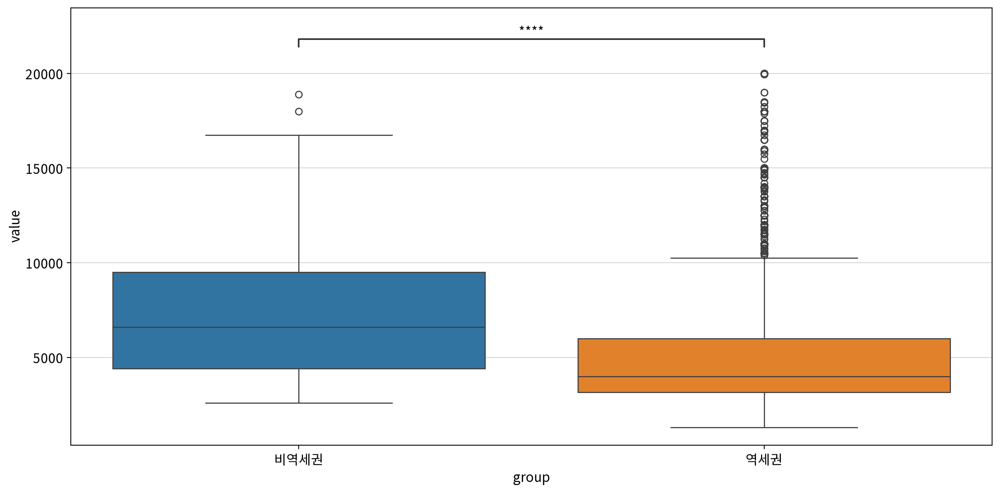

statistic  p-value  significant      result
test                alternative                                             
Mann-Whitney U test two-sided   148355.000    0.000         True  비역세권 ≠ 역세권
                    less        148355.000    1.000        False  비역세권 ≥ 역세권
                    greater     148355.000    0.000         True  비역세권 > 역세권

In [ ]:
for d in derived_categorical_cols:
    ## 2개의 고유값만 존재하는 명목형 독립변수에 대해서만 검정을 수행한다.
    if len(df[d].unique()) == 2:
        ## 빈 줄 출력용
        print()

        ## 분석 단위 제목 출력
        display(Markdown(f"##### ▶︎ {d}({column_means[d]}) → {target}"))

        ## 수집된 데이터가 long 타입이므로 검정 대상만 wide 타입으로 변환해야 한다.
        wide_df = my_prep.long2wide(df, hue=d, values=target)
        display(my_stats.test_independent(wide_df,
                    group1=wide_df.columns[0], group2=wide_df.columns[1]))

**검정 결과**

| 변수 | 검정 | 통계량 | p-value | 판단 | 채택 여부 |
|---|---|---:|---:|---|---|
| `is_station_area` | Mann–Whitney U | U = 148,355.0 | **< 0.001** | **역세권 여부에 따른 임대료 차이 있음** | ✅ 채택 |




- is_station_area는 역세권 여부에 따라 임대료 분포에 유의한 차이가 확인되었으며(p < .001), 비역세권의 임대료 수준이 더 높게 나타나 모델링 후보로 채택한다.

#### 5) 파생변수 ▶ ANOVA (x: 3집단 명목형 독립변수 → y: 종속변수)

In [75]:
for d in derived_categorical_cols:
    ## 3개 이상의 고유값이 존재하는 명목형 독립변수에 대해서만 검정을 수행한다.
    if len(df[d].unique()) >= 3:
        print() ## 빈 줄 출력용

        ## 분석 단위 제목 출력
        display(Markdown(f"##### ▶︎ {d}({column_means[d]}) → {target}"))

        display(my_stats.anova_oneway(df, y=target, between=d))
        
        ## 사후검정
        display(my_stats.posthoc_oneway(df, y=target, between=d, plot=False))

##### ▶︎ building_age_group(건물 연식 구분) → rent

,test,Source,ddof1,ddof2,F,p_unc,np2,effect_size
0,welch_anova,building_age_group,2,372.476,47.311,0.000,0.033,Small


,test,A,B,mean_A,mean_B,diff,se,T,df,pval,hedges,significant,effet_size
0,Games-Howell,구축,신축,4888.265,6728.322,-1840.057,302.980,-6.073,194.939,0.000,-0.598,True,Medium
1,Games-Howell,구축,준신축,4888.265,6264.451,-1376.186,172.978,-7.956,505.655,0.000,-0.452,True,Small
2,Games-Howell,신축,준신축,6728.322,6264.451,463.871,339.874,1.365,296.579,0.361,0.131,False,Negligible


**검정 결과**

| 변수 | 검정 | 통계량 | p-value | 효과크기 | 판단 | 채택 여부 |
|---|---|---:|---:|---|---|---|
| `building_age_group` | Welch ANOVA | F = 47.311 | **< 0.001** | `np2` = 0.033, Small | **건물 연식 그룹별 평균 임대료에 유의한 차이 있음** | ✅ 채택 |

- building_age_group은 연식 그룹별 임대료 차이가 유의했으며(p < .001), 특히 구축의 임대료가 신축·준신축보다 낮게 나타나 모델링 후보로 채택한다. 다만 효과크기는 Small 수준으로 영향력 자체는 크지 않다.

#### 6) 파생변수 ▶ 다변량 분석 — 파생변수 간 상관

In [85]:
# 연속형 파생변수 간 상관분석
corr_derived = my_stats.multi_correlation(df, columns=derived_continuous_cols, plot=False)
my_stats.correlation_summary(corr_derived)

method   coef  p-value  \
x                     y                                                 
size_per_room         amenity_count          Spearman  0.086    0.000   
                      size_neigh_ratio       Spearman -0.145    0.000   
                      floor_neigh_ratio      Spearman  0.006    0.738   
                      room_size_neigh_ratio  Spearman  0.944    0.000   
                      amenity_neigh_ratio    Spearman  0.082    0.000   
amenity_count         size_neigh_ratio       Spearman  0.049    0.004   
                      floor_neigh_ratio      Spearman  0.049    0.004   
                      room_size_neigh_ratio  Spearman  0.060    0.000   
                      amenity_neigh_ratio    Spearman  0.994    0.000   
size_neigh_ratio      floor_neigh_ratio      Spearman  0.162    0.000   
                      room_size_neigh_ratio  Spearman -0.142    0.000   
                      amenity_neigh_ratio    Spearman  0.054    0.001   
floor_neigh_ratio     room_size_neigh_ratio  Spearman  0.001    0.949   
                      amenity_neigh_ratio    Spearman  0.049    0.004   
room_size_neigh_ratio amenity_neigh_ratio    Spearman  0.061    0.000   

                                            strength  significant  \
x                     y                                             
size_per_room         amenity_count             Weak         True   
                      size_neigh_ratio          Weak         True   
                      floor_neigh_ratio         Weak        False   
                      room_size_neigh_ratio   Strong         True   
                      amenity_neigh_ratio       Weak         True   
amenity_count         size_neigh_ratio          Weak         True   
                      floor_neigh_ratio         Weak         True   
                      room_size_neigh_ratio     Weak         True   
                      amenity_neigh_ratio     Strong         True   
size_neigh_ratio      floor_neigh_ratio         Weak         True   
                      room_size_neigh_ratio     Weak         True   
                      amenity_neigh_ratio       Weak         True   
floor_neigh_ratio     room_size_neigh_ratio     Weak        False   
                      amenity_neigh_ratio       Weak         True   
room_size_neigh_ratio amenity_neigh_ratio       Weak         True   

                                             normality_x  normality_y  \
x                     y                                                 
size_per_room         amenity_count                False        False   
                      size_neigh_ratio             False        False   
                      floor_neigh_ratio            False        False   
                      room_size_neigh_ratio        False        False   
                      amenity_neigh_ratio          False        False   
amenity_count         size_neigh_ratio             False        False   
                      floor_neigh_ratio            False        False   
                      room_size_neigh_ratio        False        False   
                      amenity_neigh_ratio          False        False   
size_neigh_ratio      floor_neigh_ratio            False        False   
                      room_size_neigh_ratio        False        False   
                      amenity_neigh_ratio          False        False   
floor_neigh_ratio     room_size_neigh_ratio        False        False   
                      amenity_neigh_ratio          False        False   
room_size_neigh_ratio amenity_neigh_ratio          False        False   

                                             linearity  influential  
x                     y                                              
size_per_room         amenity_count              False         True  
                      size_neigh_ratio           False         True  
                      floor_neigh_ratio          False         True  
                      room_size_neigh_r

,size_per_room,amenity_count,size_neigh_ratio,floor_neigh_ratio,room_size_neigh_ratio,amenity_neigh_ratio
size_per_room,1.000,0.086,-0.145,0.006,0.944,0.082
amenity_count,0.086,1.000,0.049,0.049,0.060,0.994
size_neigh_ratio,-0.145,0.049,1.000,0.162,-0.142,0.054
floor_neigh_ratio,0.006,0.049,0.162,1.000,0.001,0.049
room_size_neigh_ratio,0.944,0.060,-0.142,0.001,1.000,0.061
amenity_neigh_ratio,0.082,0.994,0.054,0.049,0.061,1.000


,max-y,max-coef,count,columns
x,,,,
amenity_count,amenity_neigh_ratio,0.994,1,amenity_neigh_ratio
amenity_neigh_ratio,amenity_count,0.994,1,amenity_count
room_size_neigh_ratio,size_per_room,0.944,1,size_per_room
size_per_room,room_size_neigh_ratio,0.944,1,room_size_neigh_ratio
floor_neigh_ratio,size_neigh_ratio,0.162,0,-
size_neigh_ratio,floor_neigh_ratio,0.162,0,-


**해석**

- **Strong 구간(|ρ| ≥ 0.7)의 쌍:** `size_per_room`–`room_size_neigh_ratio`(+0.944), `amenity_count`–`amenity_neigh_ratio`(+0.994)로 **총 2쌍**이며, 모두 양의 상관이다(각 p < .001).
- **공통 관계:** `room_size_neigh_ratio`는 `size_per_room`을 지역 평균과 비교해 만든 변수이므로 두 변수 간 중복성이 매우 크고, `amenity_neigh_ratio` 역시 `amenity_count`와 거의 동일한 정보를 반영한다.
- **중복 검토 대상:** `size_per_room`·`room_size_neigh_ratio`, `amenity_count`·`amenity_neigh_ratio`는 각각 Strong 관계이므로 **동시에 모델에 투입할 경우 다중공선성을 우선 점검한다.**
- **Strong 상대가 없는 변수:** `size_neigh_ratio`와 `floor_neigh_ratio`는 서로 ρ = +0.162로 약한 관계만 보이며, 다른 파생변수와도 Strong 수준의 상관이 없다.
- **유의성과 강도 구분:** `size_per_room`–`floor_neigh_ratio`는 p = .738, `floor_neigh_ratio`–`room_size_neigh_ratio`는 p = .949로 유의하지 않으며, 그 외 일부 쌍은 p < .05이더라도 상관계수는 모두 Weak 수준이다.
- **후속 조치:** 상관이 매우 높은 파생변수 쌍은 중복 가능성이 크므로 **변수 의미·단변량 결과·종속변수와의 관계를 함께 비교한 뒤 하나를 우선 선택하고, 최종적으로 VIF와 모델 성능을 통해 유지 여부를 결정한다.**

**모델링 최종 투입 파생변수**

| 변수 | 이상치 · 특이점 | 채택여부 |
|---|---|---|
| `size_per_room` | 일부 큰 값과 고가 매물이 존재하며 임대료와의 관계가 매우 약함(ρ = -0.097) | ❌ 제외 — 유의하지만 효과가 매우 약하고 `size_sqft`, `bedrooms` 정보와 중복 |
| `amenity_count` | 0~7의 이산형 값에 밀집하며 동일 개수에서도 임대료 산포가 큼(ρ = +0.080) | ❌ 제외 — 유의하지만 효과가 매우 약해 파생 효과가 충분하지 않음 |
| `size_neigh_ratio` | 일부 동네 평균의 3~5배 수준인 큰 값이 존재하나 뚜렷한 양의 관계 확인(ρ = +0.783) | ✅ 채택 — **Strong 수준의 상관 검증을 통과**했고 지역 내 상대적 주택 규모라는 추가 정보를 제공 |
| `floor_neigh_ratio` | 일부 5~8배 수준의 높은 값이 존재하며 관계는 약함(ρ = +0.287) | ✅ 채택 — 상관은 약하지만 유의하며, 절대 층수가 아닌 **동네 내 상대적 층수**라는 별도 정보를 제공 |
| `room_size_neigh_ratio` | 일부 큰 비율의 이상치가 있으며 약한 음의 관계(ρ = -0.178) | ❌ 제외 — 효과가 약하고 `size_per_room`과 지역 평균 정보를 다시 조합하여 중복성이 큼 |
| `amenity_neigh_ratio` | 0 부근 밀집 및 최대 약 27배의 극단값이 관찰됨(ρ = +0.071) | ❌ 제외 — 효과가 매우 약하고 극단값 영향도 커 파생변수로서 이득이 작음 |
| `is_station_area` | 예상과 달리 비역세권의 임대료가 더 높게 나타남(p < .001) | ✅ 채택 — **2집단 검정에서 유의한 차이를 통과**했으며, 역방향 결과는 지역·주택 규모 등의 영향 가능성이 있어 다변량 모델에서 재검증할 가치가 있음 |
| `building_age_group` | 구축은 신축·준신축보다 낮지만 신축↔준신축은 유의하지 않음(p = .361), 전체 효과크기 Small | ❌ 제외 — 전체 차이는 유의하지만 효과크기가 작고 `building_age_yrs`와 정보가 중복됨 |

**최종 채택 파생변수 :**
`size_neigh_ratio`, `floor_neigh_ratio`, `is_station_area`


### 파생변수 탐색적 분석 및 모델링 변수 선정

#### 1. 분석 목적

기존 변수에서 생성한 파생변수가 실제로 `rent`(월 임대료)를 설명하는 데 영향이 있는지 확인하였다. 연속형 파생변수는 분포·이상치·왜도를 확인한 뒤 임대료와의 상관관계를 검토하였고, 범주형 파생변수는 집단 간 임대료 차이를 검정하였다. 또한 파생변수 간 상관분석을 통해 정보 중복 가능성을 확인하였다.

#### 2. 파생변수 탐색 결과

| 변수 | 단변량·분포 특징 | `rent`와의 관계 | 파생변수 간 중복 | 모델링 채택 |
|---|---|---|---|---|
| `size_per_room` | 우편향 +2.342, 상단 이상치 108건(3.1%) | ρ = **-0.097**, '약함' | `room_size_neigh_ratio`와 **ρ = +0.944** | ❌ 제외 |
| `amenity_count` | 우편향 +1.198, 0에 크게 집중 | ρ = **+0.080**, '약함' | `amenity_neigh_ratio`와 **ρ = +0.994** | ❌ 제외 |
| `size_neigh_ratio` | 우편향 +1.686, 상단 이상치 155건(4.4%) | ρ = **+0.783**, '강함' | 중복성 낮음 | ✅ **채택** |
| `floor_neigh_ratio` | 우편향 +1.702, 상단 이상치 130건(3.7%) | ρ = **+0.287**, '약함' | 중복성 낮음 | ✅ **채택** |
| `room_size_neigh_ratio` | 우편향 +1.992, 상단 이상치 110건(3.1%) | ρ = **-0.178**, '약함' | `size_per_room`과 **ρ = +0.944** | ❌ 제외 |
| `amenity_neigh_ratio` | 강한 우편향 +2.904, 0에 집중, 최대 27 | ρ = **+0.071**, '약함' | `amenity_count`와 **ρ = +0.994** | ❌ 제외 |
| `is_station_area` | 역세권 98.3%, 비역세권 1.7%로 심한 불균형 | Mann–Whitney **p < .001** | `min_to_subway` 정보를 15분 기준으로 재가공 | ❌ 제외 |
| `building_age_group` | 구축 83.2%, 준신축 11.6%, 신축 5.2% | Welch ANOVA **p < .001**, `np2 = 0.033` | `building_age_yrs`를 범주화한 정보 | ❌ 제외 |

#### 3. 변수별 선정 근거

**`size_neigh_ratio` → 채택**

`rent`(임대료)와 **'강함' 수준의 양의 상관관계(ρ = +0.783, p < .001)**를 보여 8개 파생변수 중 가장 뚜렷한 설명력을 보였다. 또한 다른 파생변수와 '강함' 수준의 상관이 없어 정보 중복 가능성도 낮다. 단순한 집 크기가 아니라 **해당 동네 평균과 비교했을 때 매물이 상대적으로 얼마나 큰지**를 나타내므로 지역별 주거 규모 차이를 보정한 추가 정보를 제공한다.

**`floor_neigh_ratio` → 채택**

`rent`(임대료)와의 관계는 '약함' 수준이지만 **유의한 양의 관계(ρ = +0.287, p < .001)**가 나타났다. 다른 파생변수와 높은 상관관계가 없어 중복 위험이 낮으며, 원본 `floor`(층수)와 달리 같은 동네의 평균 층수와 비교해 해당 매물이 얼마나 높은 층에 위치하는지를 나타내므로, 모델에서 실제 성능 개선 여부를 확인할 가치가 있다.

**`size_per_room`, `room_size_neigh_ratio` → 제외**

두 변수 모두 `rent`(임대료)와의 관계가 약하며 각각 ρ = -0.097, -0.178에 그쳤다. 특히 두 변수끼리 ρ = +0.944로 매우 높은 상관을 보여 유사한 정보를 반복적으로 포함할 가능성이 크다. 따라서 두 변수를 추가로 사용할 필요성이 낮다고 판단하였다.

**`amenity_count`, `amenity_neigh_ratio` → 제외**

`rent`(임대료)와의 상관이 각각 **+0.080, +0.071**로 매우 약하고 두 변수 사이에는 **ρ = +0.994**의 거의 완전한 상관관계가 나타났다. 특히 `amenity_neigh_ratio`는 최대 27의 극단값도 존재하므로 추가적인 설명력보다 중복 및 극단값 영향이 더 큰 것으로 판단하였다.

**`is_station_area` → 제외**

집단 간 `rent`(임대료) 차이는 통계적으로 유의했지만(p < .001), **역세권 3,449건(98.3%) / 비역세권 61건(1.7%)**으로 집단 불균형이 매우 심하다. 또한 연속형 원본 변수인 `min_to_subway`를 15분 기준으로 이분화하면서 거리 정보가 줄어들기 때문에, 파생변수보다는 원본 변수를 유지하는 것이 적절하다고 판단하였다.

**`building_age_group` → 제외**

연식 집단 간 전체 차이는 유의했지만(p < .001), 효과크기가 **Small(`np2 = 0.033`)** 수준이고 신축과 준신축 사이에는 유의한 차이가 없었다(p = .361). 또한 기존 `building_age_yrs`의 정보를 3개 집단으로 다시 범주화한 변수이므로 정보 손실과 중복 가능성이 있다.

#### 4. 모델링 투입 파생변수 확정

`size_neigh_ratio`, `floor_neigh_ratio`

> **최종 인사이트:** 파생변수 중 임대료와의 관계가 확인되고 변수 간 중복이 낮으면서 지역 내 상대적 특성이라는 추가 정보를 제공하는 `size_neigh_ratio`와 `floor_neigh_ratio`를 모델링 변수로 채택하였다.

#### 로그변환 전 파일 저장

In [96]:
## 종속변수
target = "rent"

## 원본 연속형 독립변수
continuous_cols = [
    "bedrooms", "bathrooms", "size_sqft",
    "min_to_subway", "floor", "building_age_yrs"
]

## 원본 명목형 독립변수
nominal_cols = [
    "no_fee", "has_roofdeck", "has_washer_dryer",
    "has_doorman", "has_elevator", "has_dishwasher",
    "has_patio", "has_gym", "neighborhood"
]

## 최종 채택 파생변수
derived_cols = ["size_neigh_ratio", "floor_neigh_ratio"]

## 최종 투입 변수만 선택
model_cols = [target] + continuous_cols + nominal_cols + derived_cols
df_before = df[model_cols].copy()

## 결측값·무한대 확인
assert not df_before.isna().any().any(), "결측값을 확인하세요."
assert np.isfinite(
    df_before[[target] + continuous_cols + derived_cols].to_numpy()
).all(), "무한대 값을 확인하세요."

df_before.to_excel(r"C:\백업파일\코딩공부\포트폴리오\07_[머신러닝_예측]_뉴욕_맨해튼\manhattan_before.xlsx")

print("변환 전 데이터 크기:", df_before.shape)  # 현재 노트북 기준 (3510, 18)

변환 전 데이터 크기: (3510, 18)


#### 로그 변환

In [117]:
# 최종 채택 변수와 종속변수만 모델링용 데이터로 구성한다.
model_cols = [
    # 종속 변수
    "rent",

    # 원본 변수
    "bedrooms",
    "bathrooms",
    "size_sqft",
    "floor",
    "building_age_yrs",
    "has_washer_dryer",
    "has_doorman",
    "has_elevator",
    "has_dishwasher",
    "neighborhood",

    # 파생변수
    "size_neigh_ratio",
    "floor_neigh_ratio",
]

df_model = df[model_cols].copy()

In [119]:
# 변환 후 데이터를 별도로 생성
df_model_transformed = df_model.copy()

# 모든 값이 0보다 큰 변수
log_cols = [
    "rent",
    "size_sqft",
    "size_neigh_ratio"
]

# 0이 포함된 변수
log1p_cols = [
    "floor",
    "floor_neigh_ratio"
]

# 로그 변환
for col in log_cols:
    df_model_transformed[col] = np.log(
        df_model_transformed[col]
    )

# 0을 유지할 수 있도록 log1p 적용
for col in log1p_cols:
    df_model_transformed[col] = np.log1p(
        df_model_transformed[col]
    )

display(df_model_transformed[log_cols + log1p_cols].head())

,rent,size_sqft,size_neigh_ratio,floor,floor_neigh_ratio
0,7.844,6.174,-0.753,1.099,0.154
1,9.350,7.601,0.774,0.693,0.146
2,8.412,6.820,-0.128,3.951,1.163
3,8.475,6.882,0.056,2.197,0.814
4,9.770,8.476,1.234,1.609,0.704


#### 라벨링 (범주형 변수)

In [125]:
# 범주형 변수의 데이터 타입을 category로 지정한다.
categorical_cols = [
    "has_washer_dryer",
    "has_doorman",
    "has_elevator",
    "has_dishwasher",
    "neighborhood"
]

for col in categorical_cols:
    df_model_transformed[col] = df_model_transformed[col].astype("category")

df_model_transformed.dtypes

rent                  float64
bedrooms              float64
bathrooms               int64
size_sqft             float64
floor                 float64
building_age_yrs        int64
has_washer_dryer     category
has_doorman          category
has_elevator         category
has_dishwasher       category
neighborhood         category
size_neigh_ratio      float64
floor_neigh_ratio     float64
dtype: object

In [126]:
df_model_transformed.to_excel(r"C:\백업파일\코딩공부\포트폴리오\07_[머신러닝_예측]_뉴욕_맨해튼\manhattan_rent_after_transform.xlsx")

print("변환 후 데이터 크기:", df_model_transformed.shape)
print(df_model_transformed.dtypes)

display(df_model_transformed.head())

변환 후 데이터 크기: (3510, 13)
rent                  float64
bedrooms              float64
bathrooms               int64
size_sqft             float64
floor                 float64
building_age_yrs        int64
has_washer_dryer     category
has_doorman          category
has_elevator         category
has_dishwasher       category
neighborhood         category
size_neigh_ratio      float64
floor_neigh_ratio     float64
dtype: object


,rent,bedrooms,bathrooms,size_sqft,floor,building_age_yrs,has_washer_dryer,has_doorman,has_elevator,has_dishwasher,neighborhood,size_neigh_ratio,floor_neigh_ratio
0,7.844,0.000,1,6.174,1.099,17,0,0,1,1,20,-0.753,0.154
1,9.350,2.000,2,7.601,0.693,96,0,0,0,0,2,0.774,0.146
2,8.412,1.000,1,6.820,3.951,29,0,1,1,1,9,-0.128,1.163
3,8.475,1.000,1,6.882,2.197,31,0,1,1,1,2,0.056,0.814
4,9.770,2.000,2,8.476,1.609,136,0,1,1,1,17,1.234,0.704


#### 모델링 변수들만 추출하여 분석

In [127]:
# 원본 변수와 파생변수 중 최종 채택된 변수만 모델링 변수로 선택한다.
selected_features = [
    # 원본 연속형 변수
    "bedrooms",
    "bathrooms",
    "size_sqft",
    "floor",
    "building_age_yrs",

    # 원본 범주형 변수
    "has_washer_dryer",
    "has_doorman",
    "has_elevator",
    "has_dishwasher",
    "neighborhood",

    # 최종 채택 파생변수
    "size_neigh_ratio",
    "floor_neigh_ratio",
]

feature = df[selected_features]
target = df["rent"]

print(f"최종 모델링 변수 수: {feature.shape[1]}개")
print(feature.columns.tolist())

최종 모델링 변수 수: 12개
['bedrooms', 'bathrooms', 'size_sqft', 'floor', 'building_age_yrs', 'has_washer_dryer', 'has_doorman', 'has_elevator', 'has_dishwasher', 'neighborhood', 'size_neigh_ratio', 'floor_neigh_ratio']


In [128]:
df_model_transformed = my_qtcheck.set_type(df_model_transformed, as_category=categorical_cols)

<class 'pandas.core.frame.DataFrame'>
Index: 3510 entries, 0 to 3538
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   rent               3510 non-null   float64 
 1   bedrooms           3510 non-null   float64 
 2   bathrooms          3510 non-null   int64   
 3   size_sqft          3510 non-null   float64 
 4   floor              3510 non-null   float64 
 5   building_age_yrs   3510 non-null   int64   
 6   has_washer_dryer   3510 non-null   category
 7   has_doorman        3510 non-null   category
 8   has_elevator       3510 non-null   category
 9   has_dishwasher     3510 non-null   category
 10  neighborhood       3510 non-null   category
 11  size_neigh_ratio   3510 non-null   float64 
 12  floor_neigh_ratio  3510 non-null   float64 
dtypes: category(5), float64(6), int64(2)
memory usage: 265.7 KB


#### #분석 데이터 확인

- 탐색적 데이터 분석을 통해 최종 변수를 선정하였다.
- 연속형 변수의 로그변환과 범주형 변수의 라벨링을 완료한 데이터를 모델링에 사용한다.
- 동일한 노트북에서 전처리를 수행하였으므로 저장된 파일을 다시 불러오지 않고 현재 데이터프레임을 그대로 사용한다.

##### #모델링 라이브러리 참조

In [129]:
# 훈련, 검증 데이터 분리 함수
from sklearn.model_selection import train_test_split

# 성능평가 지표 계산 함수
from sklearn.metrics import (
    r2_score,                       # 결정계수 (R2)
    mean_absolute_error,            # 평균절대오차 (MAE)
    mean_squared_error,             # 평균제곱오차 (MSE)
    mean_squared_log_error,         # 평균제곱로그오차 (MSLE)
    mean_absolute_percentage_error, # 평균절대백분율오차 (MAPE)
)

In [130]:
df_model_transformed.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3510 entries, 0 to 3538
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   rent               3510 non-null   float64 
 1   bedrooms           3510 non-null   float64 
 2   bathrooms          3510 non-null   int64   
 3   size_sqft          3510 non-null   float64 
 4   floor              3510 non-null   float64 
 5   building_age_yrs   3510 non-null   int64   
 6   has_washer_dryer   3510 non-null   category
 7   has_doorman        3510 non-null   category
 8   has_elevator       3510 non-null   category
 9   has_dishwasher     3510 non-null   category
 10  neighborhood       3510 non-null   category
 11  size_neigh_ratio   3510 non-null   float64 
 12  floor_neigh_ratio  3510 non-null   float64 
dtypes: category(5), float64(6), int64(2)
memory usage: 265.7 KB


#### #독립변수와 종속변수 분리
- 머신러닝 모델의 입력값으로 사용되는 독립변수를 'feature'로 지정한다.
- 예측 대상인 맨해튼 월 임대료 `rent`를 'target'으로 지정한다.

In [131]:
# 독립변수(feature)와 종속변수(target)를 분리
feature = df_model_transformed.drop(columns=["rent"])
target = df_model_transformed["rent"]

feature.shape, target.shape

((3510, 12), (3510,))

In [132]:
# 모델링에 투입되는 독립변수와 종속변수를 확인
print("독립변수:")
display(feature.head())

print("종속변수:")
display(target.head())

독립변수:


,bedrooms,bathrooms,size_sqft,floor,building_age_yrs,has_washer_dryer,has_doorman,has_elevator,has_dishwasher,neighborhood,size_neigh_ratio,floor_neigh_ratio
0,0.000,1,6.174,1.099,17,0,0,1,1,20,-0.753,0.154
1,2.000,2,7.601,0.693,96,0,0,0,0,2,0.774,0.146
2,1.000,1,6.820,3.951,29,0,1,1,1,9,-0.128,1.163
3,1.000,1,6.882,2.197,31,0,1,1,1,2,0.056,0.814
4,2.000,2,8.476,1.609,136,0,1,1,1,17,1.234,0.704


종속변수:


0   7.844
1   9.350
2   8.412
3   8.475
4   9.770
Name: rent, dtype: float64

#### 훈련 데이터와 검증 데이터 분리

> 전체 데이터를 훈련용 데이터 80%와 검증용 데이터 20%로 분리하였다.
> 모델별 성능을 동일한 조건에서 비교하기 위해 모든 알고리즘에서 동일한 훈련·검증 데이터를 사용하며, 데이터 분할 결과가 실행할 때마다 달라지지 않도록 난수 시드를 고정하였다.

- `x_train`: 모델 학습에 사용할 독립변수
- `x_test`: 학습된 모델의 성능 검증에 사용할 독립변수
- `y_train`: 모델 학습에 사용할 실제 임대료
- `y_test`: 모델의 예측 성능을 검증할 실제 임대료

In [133]:
# 전체 데이터를 훈련용 80%와 검증용 20%로 분리한다.
x_train, x_test, y_train, y_test = train_test_split(
    feature,
    target,
    test_size=0.2,
    random_state=RANDOM_STATE
)

x_train.shape, x_test.shape, y_train.shape, y_test.shape

((2808, 12), (702, 12), (2808,), (702,))

##### 학습을 완료한 모델이 저장될 폴더

In [135]:
project_name = "manhattan_rent"
workdir = f"{project_name}/baseline"

if not os.path.exists(workdir):
    os.makedirs(workdir)

작업 폴더: manhattan_rent\baseline
학습 완료 [ 1/11] : linear
학습 완료 [ 2/11] : ridge
학습 완료 [ 3/11] : lasso
학습 완료 [ 4/11] : elasticnet
학습 완료 [ 5/11] : kneighbors
학습 완료 [ 6/11] : svr
학습 완료 [ 7/11] : decisiontree
학습 완료 [ 8/11] : randomforest
학습 완료 [ 9/11] : xgb
학습 완료 [10/11] : lgbm
학습 완료 [11/11] : catboost


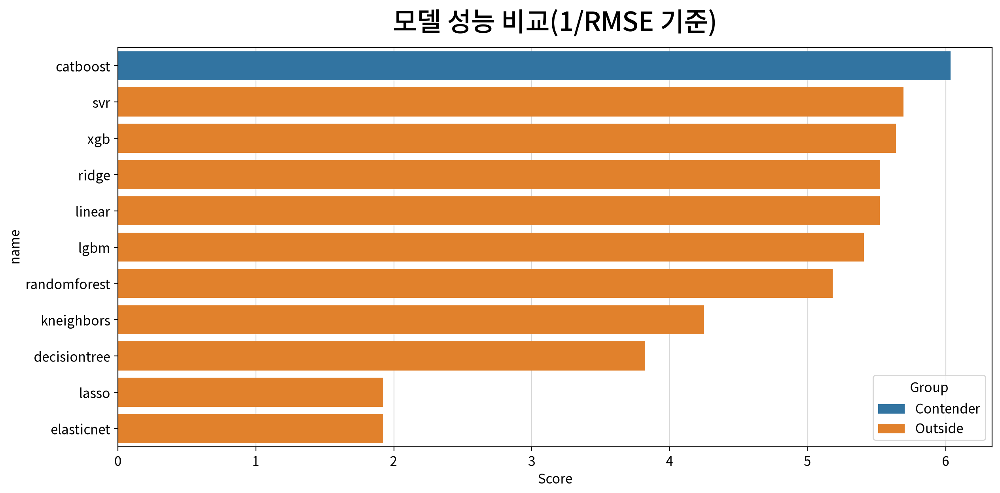


모델 11개 학습·저장 완료 → manhattan_rent\baseline


,Rank,Group,Model,R2,MAE,MSE,RMSE,RMSLE,MAPE,MPE,RMSE_Gap,Score
name,,,,,,,,,,,,
catboost,1,Contender,CatBoostRegressor,0.898,0.118,0.027,0.166,0.017,0.014,-0.001,0.000,6.035
svr,2,Outside,SVR,0.886,0.128,0.031,0.176,0.018,0.015,0.000,0.060,5.694
xgb,3,Outside,XGBRegressor,0.883,0.124,0.031,0.177,0.018,0.015,-0.001,0.070,5.639
ridge,4,Outside,Ridge,0.879,0.131,0.033,0.181,0.019,0.015,0.000,0.092,5.525
linear,5,Outside,LinearRegression,0.878,0.132,0.033,0.181,0.019,0.016,-0.000,0.093,5.521
lgbm,6,Outside,LGBMRegressor,0.873,0.129,0.034,0.185,0.019,0.015,-0.001,0.116,5.408
randomforest,7,Outside,RandomForestRegressor,0.862,0.134,0.037,0.193,0.020,0.016,-0.001,0.165,5.182
kneighbors,8,Outside,KNeighborsRegressor,0.795,0.169,0.055,0.235,0.025,0.020,0.001,0.421,4.247
decisiontree,9,Outside,DecisionTreeRegressor,0.746,0.179,0.069,0.262,0.027,0.021,0.001,0.580,3.821


CPU times: total: 58 s
Wall time: 49.8 s


In [136]:
%%time
my_ml.reg_baseline("manhattan_rent", x_train, y_train, x_test, y_test)

#### 하이퍼파라미터 튜닝

In [145]:
# 베이스라인 폴더 위치 지정 (이전 실습에서 생성한 폴더를 그대로 사용해야 함)
project_name = "manhattan_rent"
base_dir = f"{project_name}/baseline"

if not os.path.exists(base_dir):
    os.makedirs(base_dir)

# 튜닝이 완료된 모델이 저장될 폴더 위치 지정
tuned_dir = f"{project_name}/tuned"

if not os.path.exists(tuned_dir):
    os.makedirs(tuned_dir)

##### 모델 로드

In [153]:
# KNN 베이스라인 모델만 학습하여 기존 baseline 폴더에 저장한다.
from sklearn.neighbors import KNeighborsRegressor

model = KNeighborsRegressor(n_jobs=-1)

model_knn = my_ml.fit_pipeline(
    model=model,
    x_train=x_train,
    y_train=y_train,
    vif=True,
    scale=True,
    drop_first=True,
    name="kneighbors",
    save_path="manhattan_rent/baseline/kneighbors.pkl",
    verbose=False
)

print("KNN 모델 저장 완료")

KNN 모델 저장 완료


In [158]:
# 튜닝하기 원하는 모델을 로드하여 딕셔너리 형태로 저장
models = {
    "linear": my_ml.load_model(f"{base_dir}/linear.pkl"),
    "ridge": my_ml.load_model(f"{base_dir}/ridge.pkl"),
    "lasso": my_ml.load_model(f"{base_dir}/lasso.pkl"),
    "elasticnet": my_ml.load_model(f"{base_dir}/elasticnet.pkl"),
    "kneighbors": my_ml.load_model(f"{base_dir}/kneighbors.pkl"),
    "svr": my_ml.load_model(f"{base_dir}/svr.pkl"),
    "decisiontree": my_ml.load_model(f"{base_dir}/decisiontree.pkl"),
    "randomforest": my_ml.load_model(f"{base_dir}/randomforest.pkl"),
    "xgb": my_ml.load_model(f"{base_dir}/xgb.pkl"),
    "lgbm": my_ml.load_model(f"{base_dir}/lgbm.pkl"),
    "catboost": my_ml.load_model(f"{base_dir}/catboost.pkl")
}

작업 폴더: manhattan_rent\tuned
탐색 범위: 실무용
탐색 완료 [ 1/11] : linear (2.6초, CV RMSE=0.1788)
    최적 조합: {'model__fit_intercept': True, 'model__positive': False}
탐색 완료 [ 2/11] : ridge (0.6초, CV RMSE=0.1787)
    최적 조합: {'model__alpha': 0.1, 'model__solver': 'lsqr'}
탐색 완료 [ 3/11] : lasso (0.5초, CV RMSE=0.1791)
    최적 조합: {'model__alpha': 0.0001, 'model__max_iter': 1000}
탐색 완료 [ 4/11] : elasticnet (0.6초, CV RMSE=0.1788)
    최적 조합: {'model__alpha': 0.0001, 'model__l1_ratio': 0.1}
탐색 완료 [ 5/11] : kneighbors (1.0초, CV RMSE=0.2118)
    최적 조합: {'model__n_neighbors': 10, 'model__p': 1, 'model__weights': 'distance'}
탐색 완료 [ 6/11] : svr (3.7초, CV RMSE=0.1661)
    최적 조합: {'model__C': 10.0, 'model__epsilon': 0.05, 'model__gamma': 0.01}
탐색 완료 [ 7/11] : decisiontree (0.8초, CV RMSE=0.2466)
    최적 조합: {'model__max_depth': 10, 'model__min_samples_leaf': 1}
탐색 완료 [ 8/11] : randomforest (16.1초, CV RMSE=0.1910)
    최적 조합: {'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__n_estimators': 300}
탐색 완료 [ 9/1

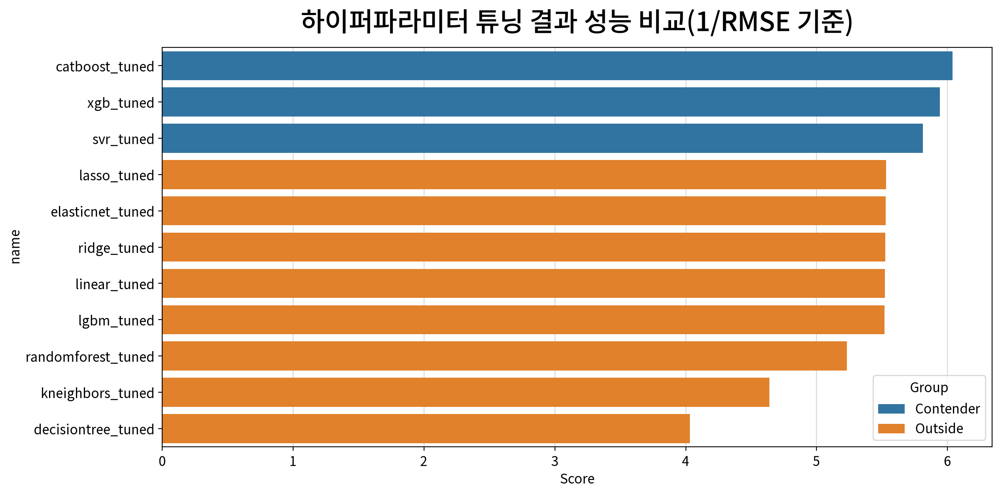


모델 11개 튜닝·저장 완료 → manhattan_rent\tuned


,Rank,Group,Model,R2,MAE,MSE,RMSE,RMSLE,MAPE,MPE,RMSE_Gap,Score
name,,,,,,,,,,,,
catboost_tuned,1,Contender,CatBoostRegressor,0.898,0.118,0.027,0.166,0.017,0.014,-0.001,0.000,6.039
xgb_tuned,2,Contender,XGBRegressor,0.895,0.121,0.028,0.168,0.018,0.014,-0.000,0.017,5.941
svr_tuned,3,Contender,SVR,0.890,0.123,0.030,0.172,0.018,0.014,0.001,0.039,5.813
lasso_tuned,4,Outside,Lasso,0.879,0.131,0.033,0.181,0.019,0.015,0.000,0.092,5.529
elasticnet_tuned,5,Outside,ElasticNet,0.879,0.131,0.033,0.181,0.019,0.015,-0.000,0.092,5.528
ridge_tuned,6,Outside,Ridge,0.879,0.132,0.033,0.181,0.019,0.015,-0.000,0.093,5.524
linear_tuned,7,Outside,LinearRegression,0.878,0.132,0.033,0.181,0.019,0.016,-0.000,0.094,5.521
lgbm_tuned,8,Outside,LGBMRegressor,0.878,0.127,0.033,0.181,0.019,0.015,-0.000,0.094,5.519
randomforest_tuned,9,Outside,RandomForestRegressor,0.865,0.133,0.037,0.191,0.020,0.016,-0.001,0.154,5.231


CPU times: total: 2min 27s
Wall time: 19min 42s


In [159]:
%%time
my_ml.reg_tunes("manhattan_rent", models, x_train, y_train, x_test, y_test, practice=False)

In [160]:
import joblib

TUNED_DIR = Path("manhattan_rent") / "tuned"

model_files = sorted(TUNED_DIR.glob("*_tuned.pkl"))
if not model_files:
    raise FileNotFoundError(f"튜닝 모델이 없습니다: {TUNED_DIR.resolve()}")

models = {path.stem: joblib.load(path) for path in model_files}

score_rows = []
for name, model in models.items():
    row = my_ml.reg_score(model, x_test, y_test).iloc[0].to_dict()
    row["name"] = name
    score_rows.append(row)

score_table = (
    pd.DataFrame(score_rows)
      .set_index("name")
      .sort_values("R2", ascending=False)
)
top6_names = score_table.head(6).index.tolist()
display(score_table.loc[top6_names, ["R2", "MAE", "RMSE"]].round(4))

,R2,MAE,RMSE
name,,,
catboost_tuned,0.898,0.118,0.166
xgb_tuned,0.895,0.121,0.168
svr_tuned,0.890,0.123,0.172
lasso_tuned,0.879,0.131,0.181
elasticnet_tuned,0.879,0.131,0.181
ridge_tuned,0.879,0.132,0.181


In [161]:
tuned_dir = "manhattan_rent/tuned"

models = {
    "catboost_tuned": my_ml.load_model(f"{tuned_dir}/catboost_tuned.pkl"),
    "xgb_tuned": my_ml.load_model(f"{tuned_dir}/xgb_tuned.pkl"),
    "svr_tuned": my_ml.load_model(f"{tuned_dir}/svr_tuned.pkl"),
    "lasso_tuned": my_ml.load_model(f"{tuned_dir}/lasso_tuned.pkl"),
    "elasticnet_tuned": my_ml.load_model(f"{tuned_dir}/elasticnet_tuned.pkl"),
    "ridge_tuned": my_ml.load_model(f"{tuned_dir}/ridge_tuned.pkl")
}

models

{'catboost_tuned': GridSearchCV(cv=5,
              estimator=Pipeline(steps=[('preprocessor',
                                         ColumnTransformer(n_jobs=-1,
                                                           remainder='passthrough',
                                                           transformers=[('num',
                                                                          Pipeline(steps=[('vif_selector',
                                                                                           VIFSelector())]),
                                                                          ['bedrooms',
                                                                           'bathrooms',
                                                                           'size_sqft',
                                                                           'floor',
                                                                           'building_age_yrs',
            

#### 과적합 진단 

#### ▶︎ catboost_tuned

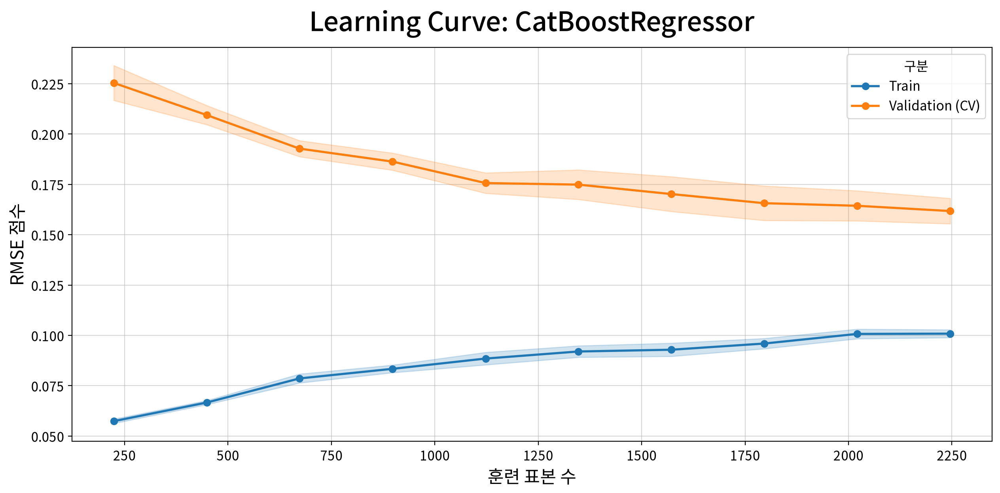

,Train,CV,CV_std,Test,Gap,Gap%,Overfit
Metric,,,,,,,
RMSE,0.107,0.162,0.006,0.166,0.055,33.890,과대적합
MAE,0.080,0.118,0.004,0.118,0.038,32.210,과대적합
R2,0.954,0.895,0.007,0.898,0.059,5.920,일반화



◆ Fit Diagnosis: CatBoostRegressor    (threshold=20%, 기준=Train↔CV 5-Fold)
    ※ threshold 는 학술 표준이 아닌 경험칙입니다  임계값보다 학습곡선 추세를 함께 보세요.
   - RMSE  : Train=     0.1070  CV=     0.1618 (±0.0056) Test=     0.1656  Gap%=   33.89%  [과대적합] [주의]
   - MAE   : Train=     0.0803  CV=     0.1185 (±0.0035) Test=     0.1178  Gap%=   32.21%  [과대적합] [주의]
   - R2    : Train=     0.9544  CV=     0.8952 (±0.0072) Test=     0.8984  Gap%=    5.92%  [일반화] [정상]

  ▶ 진단: ⚠ 과대적합 (Overfit · 高분산) - 훈련↔CV 격차가 큼
    · train R2=0.9544 (과소적합 기준 < 0.05) · CV R2=0.8952



#### ▶︎ xgb_tuned

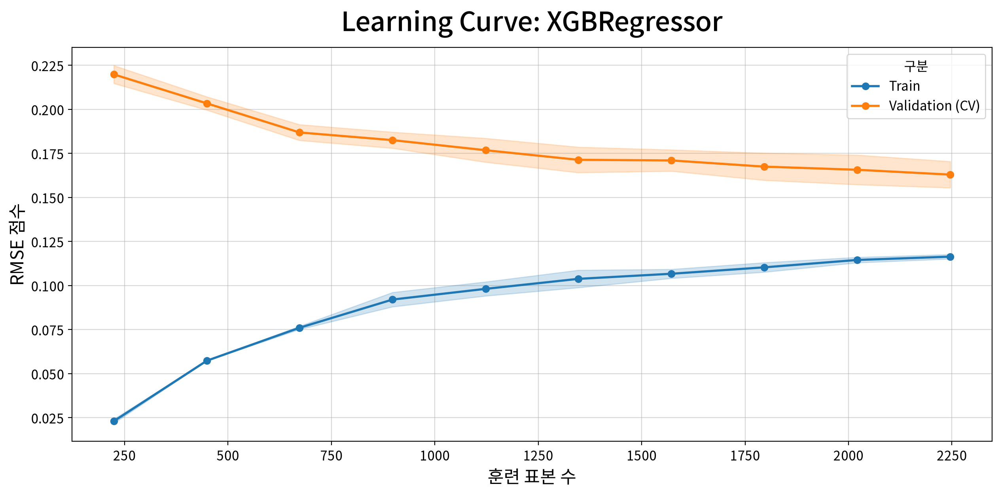

,Train,CV,CV_std,Test,Gap,Gap%,Overfit
Metric,,,,,,,
RMSE,0.121,0.164,0.007,0.168,0.043,26.320,과대적합
MAE,0.091,0.121,0.004,0.121,0.030,25.000,과대적합
R2,0.942,0.893,0.009,0.895,0.049,4.940,일반화



◆ Fit Diagnosis: XGBRegressor    (threshold=20%, 기준=Train↔CV 5-Fold)
    ※ threshold 는 학술 표준이 아닌 경험칙입니다  임계값보다 학습곡선 추세를 함께 보세요.
   - RMSE  : Train=     0.1206  CV=     0.1636 (±0.0065) Test=     0.1683  Gap%=   26.32%  [과대적합] [주의]
   - MAE   : Train=     0.0908  CV=     0.1210 (±0.0037) Test=     0.1208  Gap%=   25.00%  [과대적합] [주의]
   - R2    : Train=     0.9421  CV=     0.8927 (±0.0091) Test=     0.8950  Gap%=    4.94%  [일반화] [정상]

  ▶ 진단: ⚠ 과대적합 (Overfit · 高분산) - 훈련↔CV 격차가 큼
    · train R2=0.9421 (과소적합 기준 < 0.05) · CV R2=0.8927



#### ▶︎ svr_tuned

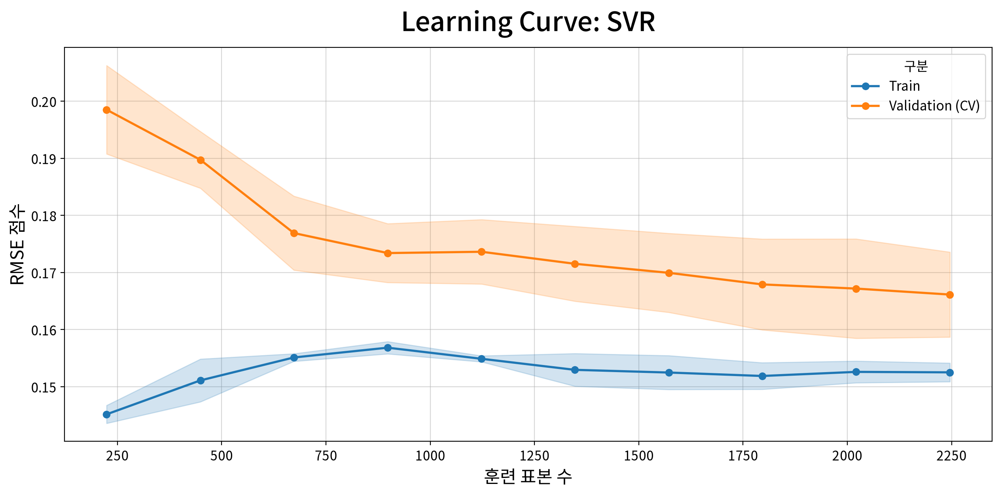

,Train,CV,CV_std,Test,Gap,Gap%,Overfit
Metric,,,,,,,
RMSE,0.153,0.166,0.007,0.172,0.014,8.140,일반화
MAE,0.112,0.123,0.004,0.123,0.011,8.970,일반화
R2,0.907,0.889,0.008,0.890,0.018,1.780,일반화



◆ Fit Diagnosis: SVR    (threshold=20%, 기준=Train↔CV 5-Fold)
    ※ threshold 는 학술 표준이 아닌 경험칙입니다  임계값보다 학습곡선 추세를 함께 보세요.
   - RMSE  : Train=     0.1526  CV=     0.1661 (±0.0067) Test=     0.1720  Gap%=    8.14%  [일반화] [정상]
   - MAE   : Train=     0.1120  CV=     0.1230 (±0.0042) Test=     0.1228  Gap%=    8.97%  [일반화] [정상]
   - R2    : Train=     0.9073  CV=     0.8895 (±0.0084) Test=     0.8903  Gap%=    1.78%  [일반화] [정상]

  ▶ 진단: ✓ 일반화 (Good fit) - 격차가 작고 훈련 성능도 양호
    · train R2=0.9073 (과소적합 기준 < 0.05) · CV R2=0.8895



#### ▶︎ lasso_tuned

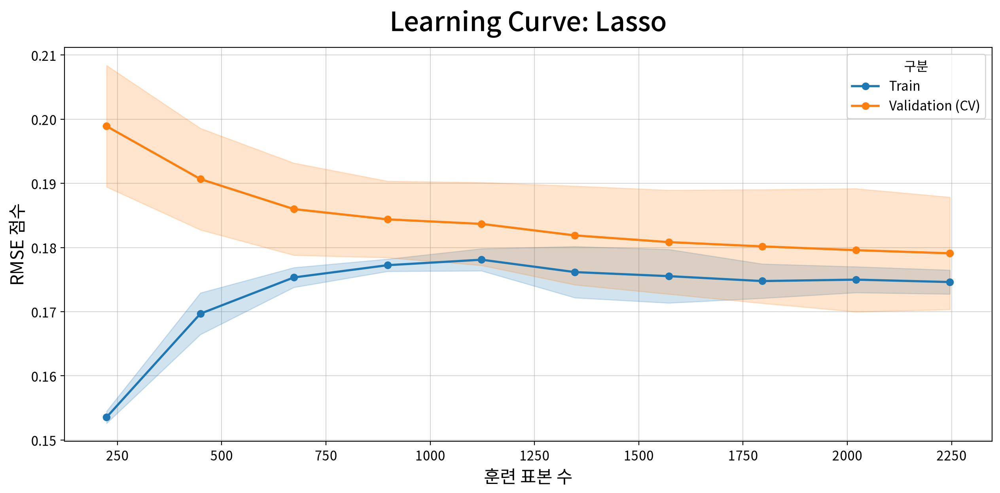

,Train,CV,CV_std,Test,Gap,Gap%,Overfit
Metric,,,,,,,
RMSE,0.175,0.179,0.008,0.181,0.004,2.300,일반화
MAE,0.133,0.136,0.005,0.131,0.003,1.900,일반화
R2,0.878,0.872,0.011,0.879,0.007,0.660,일반화



◆ Fit Diagnosis: Lasso    (threshold=20%, 기준=Train↔CV 5-Fold)
    ※ threshold 는 학술 표준이 아닌 경험칙입니다  임계값보다 학습곡선 추세를 함께 보세요.
   - RMSE  : Train=     0.1750  CV=     0.1791 (±0.0078) Test=     0.1809  Gap%=    2.30%  [일반화] [정상]
   - MAE   : Train=     0.1333  CV=     0.1359 (±0.0047) Test=     0.1310  Gap%=    1.90%  [일반화] [정상]
   - R2    : Train=     0.8781  CV=     0.8715 (±0.0108) Test=     0.8788  Gap%=    0.66%  [일반화] [정상]

  ▶ 진단: ✓ 일반화 (Good fit) - 격차가 작고 훈련 성능도 양호
    · train R2=0.8781 (과소적합 기준 < 0.05) · CV R2=0.8715



#### ▶︎ elasticnet_tuned

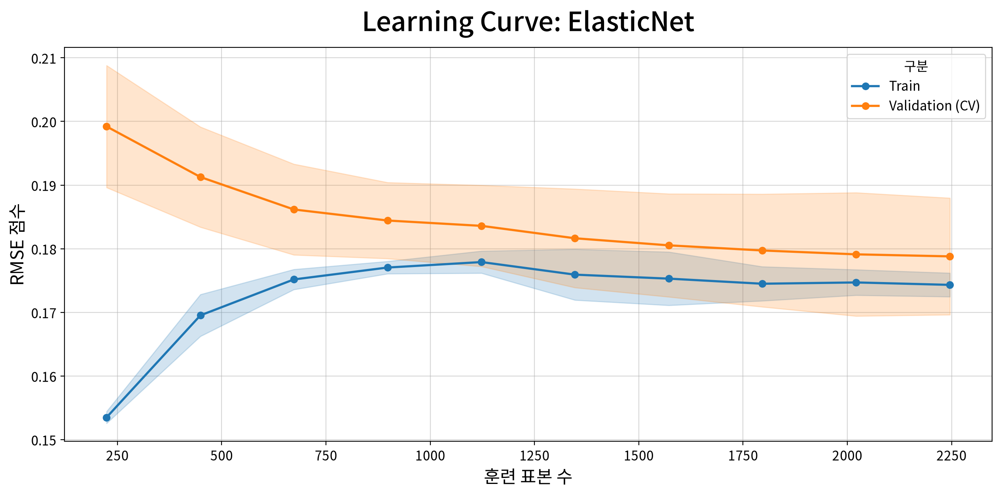

,Train,CV,CV_std,Test,Gap,Gap%,Overfit
Metric,,,,,,,
RMSE,0.175,0.179,0.008,0.181,0.004,2.300,일반화
MAE,0.133,0.136,0.005,0.131,0.003,1.980,일반화
R2,0.878,0.872,0.011,0.879,0.007,0.660,일반화



◆ Fit Diagnosis: ElasticNet    (threshold=20%, 기준=Train↔CV 5-Fold)
    ※ threshold 는 학술 표준이 아닌 경험칙입니다  임계값보다 학습곡선 추세를 함께 보세요.
   - RMSE  : Train=     0.1747  CV=     0.1788 (±0.0082) Test=     0.1809  Gap%=    2.30%  [일반화] [정상]
   - MAE   : Train=     0.1329  CV=     0.1356 (±0.0049) Test=     0.1313  Gap%=    1.98%  [일반화] [정상]
   - R2    : Train=     0.8785  CV=     0.8719 (±0.0111) Test=     0.8787  Gap%=    0.66%  [일반화] [정상]

  ▶ 진단: ✓ 일반화 (Good fit) - 격차가 작고 훈련 성능도 양호
    · train R2=0.8785 (과소적합 기준 < 0.05) · CV R2=0.8719



#### ▶︎ ridge_tuned

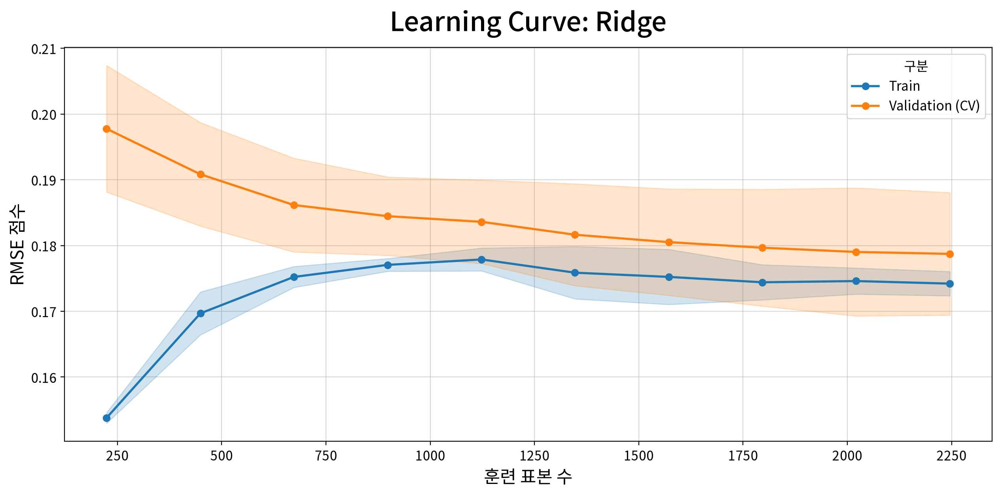

,Train,CV,CV_std,Test,Gap,Gap%,Overfit
Metric,,,,,,,
RMSE,0.175,0.179,0.008,0.181,0.004,2.340,일반화
MAE,0.133,0.136,0.005,0.132,0.003,2.040,일반화
R2,0.879,0.872,0.011,0.879,0.007,0.670,일반화



◆ Fit Diagnosis: Ridge    (threshold=20%, 기준=Train↔CV 5-Fold)
    ※ threshold 는 학술 표준이 아닌 경험칙입니다  임계값보다 학습곡선 추세를 함께 보세요.
   - RMSE  : Train=     0.1745  CV=     0.1787 (±0.0083) Test=     0.1810  Gap%=    2.34%  [일반화] [정상]
   - MAE   : Train=     0.1328  CV=     0.1355 (±0.0050) Test=     0.1315  Gap%=    2.04%  [일반화] [정상]
   - R2    : Train=     0.8787  CV=     0.8720 (±0.0112) Test=     0.8786  Gap%=    0.67%  [일반화] [정상]

  ▶ 진단: ✓ 일반화 (Good fit) - 격차가 작고 훈련 성능도 양호
    · train R2=0.8787 (과소적합 기준 < 0.05) · CV R2=0.8720

CPU times: total: 5.09 s
Wall time: 8min 29s


In [164]:
%%time

for model_name, model in models.items():
    display(Markdown(f"#### ▶︎ {model_name}"))
    my_diag.overfit(model, x_train, y_train, x_test, y_test)

**해석**

이 중 과대적합이 확인된 모델은 **`catboost_tuned`**, **`xgb_tuned`**이다.

- `catboost_tuned`는 Test R2 0.898, RMSE 0.166으로 가장 높은 예측 성능을 보였으나, RMSE와 MAE 격차가 각각 **33.89%, 32.21%**로 과대적합이 확인되었다.
- `xgb_tuned`도 Test R2 0.895로 높은 성능을 보였지만, RMSE와 MAE 격차가 각각 **26.32%, 25.00%**로 과대적합이 나타났다.
- 반면 `SVR`, `Lasso`, `ElasticNet`, `Ridge`의 RMSE 격차는 각각 **8.14%, 2.30%, 2.30%, 2.34%**로 모두 20% 미만이어서 안정적인 일반화 성능을 보였다. 특히 `SVR`은 Test R2 0.890으로 높은 예측 성능과 안정적인 일반화 성능을 함께 보였다.


### #Feature Importance

In [165]:
# 튜닝이 완료된 모델이 저장되어 있는 폴더 위치 지정
project_name = "manhattan_rent"
tuned_dir = f"{project_name}/tuned"

if not os.path.exists(tuned_dir):
    os.makedirs(tuned_dir)

# feature importance 기반 재학습된 모델이 저장될 폴더
work_dir = f"{project_name}/importance"

if not os.path.exists(work_dir):
    os.makedirs(work_dir)

### 5. 임계값 정하기

- 여기서 정한 값을 기준으로 변수 중요도를 산출한다.
  - **0.95** : 변수 중요도 95% 이내

In [166]:
cum_ratio = 0.95

if not 0.0 < cum_ratio <= 1.0:    # (0, 1] 범위를 벗어난 경우
        raise ValueError(f"cum_ratio 는 (0.0, 1.0] 범위여야 합니다: {cum_ratio}")

##### 하이퍼파라미터 튜닝 후 최고 성능 모델 로드 및 성능 확인

In [167]:
estimator = my_ml.load_model(f"{tuned_dir}/catboost_tuned.pkl")
my_ml.reg_score(estimator, x_test, y_test)

,R2,MAE,MSE,RMSE,RMSLE,MAPE,MPE
Model,,,,,,,
CatBoostRegressor,0.898,0.118,0.027,0.166,0.017,0.014,-0.001


#### CatBoost 모델에 대한 Feature Importance

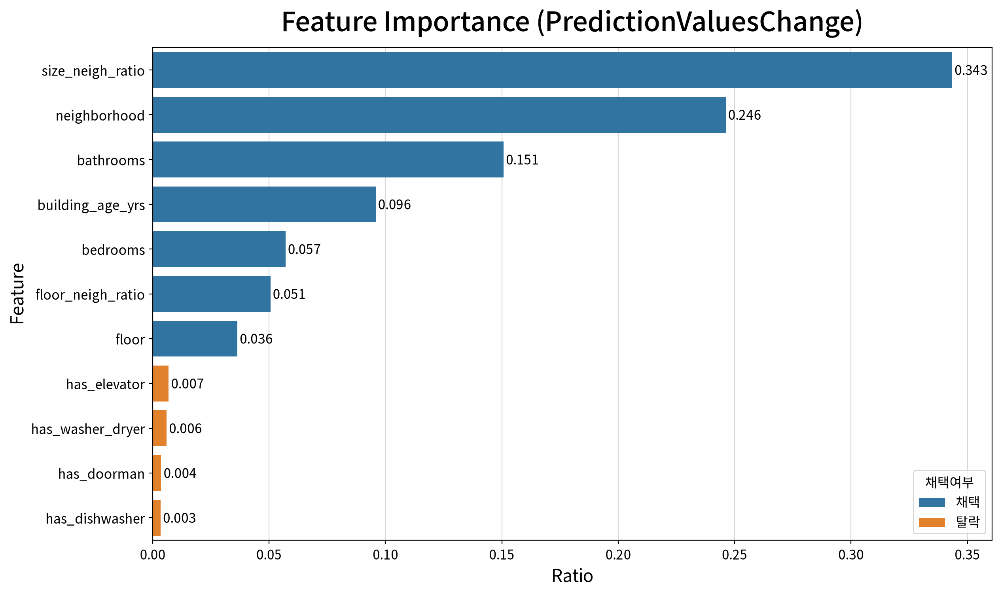

,Importance,Ratio,CumRatio,채택여부
Feature,,,,
size_neigh_ratio,34.342,0.343,0.343,채택
neighborhood,24.618,0.246,0.590,채택
bathrooms,15.073,0.151,0.740,채택
building_age_yrs,9.579,0.096,0.836,채택
bedrooms,5.705,0.057,0.893,채택
floor_neigh_ratio,5.057,0.051,0.944,채택
floor,3.638,0.036,0.980,채택
has_elevator,0.686,0.007,0.987,탈락
has_washer_dryer,0.597,0.006,0.993,탈락


In [168]:
fi = my_diag.feature_importance(estimator, cum_ratio=0.95)
fi

#### #채택된 변수 추출

In [169]:
feature_names = fi[fi['채택여부'] == '채택'].index.tolist()
feature_names

['size_neigh_ratio',
 'neighborhood',
 'bathrooms',
 'building_age_yrs',
 'bedrooms',
 'floor_neigh_ratio',
 'floor']

#### #채택된 변수 필터링

In [170]:
x_train_imp = x_train[feature_names]
x_test_imp = x_test[feature_names]

print("원본 훈련 데이터셋 변수 개수:", x_train.shape[1])
print("원본 검증 데이터셋 변수 개수:", x_test.shape[1])
print("채택된 변수만 남긴 훈련 데이터셋 변수 개수:", x_train_imp.shape[1])
print("채택된 변수만 남긴 검증 데이터셋 변수 개수:", x_test_imp.shape[1])

원본 훈련 데이터셋 변수 개수: 12
원본 검증 데이터셋 변수 개수: 12
채택된 변수만 남긴 훈련 데이터셋 변수 개수: 7
채택된 변수만 남긴 검증 데이터셋 변수 개수: 7


#### #채택된 변수로 베이스모델 재학습

In [171]:
from catboost import CatBoostRegressor

model = CatBoostRegressor(random_state=RANDOM_STATE, verbose=0)

model_name = model.__class__.__name__.lower().removesuffix('regressor')

model_imp = my_ml.fit_pipeline(
    model=model, x_train=x_train_imp, y_train=y_train,
    vif=True, scale=False, encode=False,
    name=model_name, save_path=f"{work_dir}/{model_name}_imp.pkl", verbose=False,
    model__cat_features=my_qtcheck.get_categorical_column_names(x_train_imp))

model_imp

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](0,)",[]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['size_neigh_ratio','neighborhood','bathrooms',...,'bedrooms', 'floor_neigh_ratio','floor']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
name_,str,'ca...st'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['si...io', 'ba...ms', 'bu...rs', 'be...ms', ...], 'dr...st': False, 'encode': False, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"


#### #하이퍼파라미터 튜닝

In [173]:
models = {"catboost_imp": model_imp}

my_ml.reg_tunes("manhattan_rent", models, x_train=x_train_imp, y_train=y_train,
                x_test=x_test_imp, y_test=y_test, practice=False, plot=False,
                workdir="importance")

작업 폴더: manhattan_rent\importance
탐색 범위: 실무용
탐색 완료 [ 1/ 1] : catboost_imp (1033.5초, CV RMSE=0.1622)
    최적 조합: {'model__depth': 4, 'model__iterations': 2000, 'model__learning_rate': 0.03}

모델 1개 튜닝·저장 완료 → manhattan_rent\importance


,Rank,Group,Model,R2,MAE,MSE,RMSE,RMSLE,MAPE,MPE,RMSE_Gap,Score
name,,,,,,,,,,,,
catboost_imp_tuned,1,Contender,CatBoostRegressor,0.896,0.120,0.028,0.168,0.017,0.014,-0.001,0.000,5.968


#### #과적합 진단

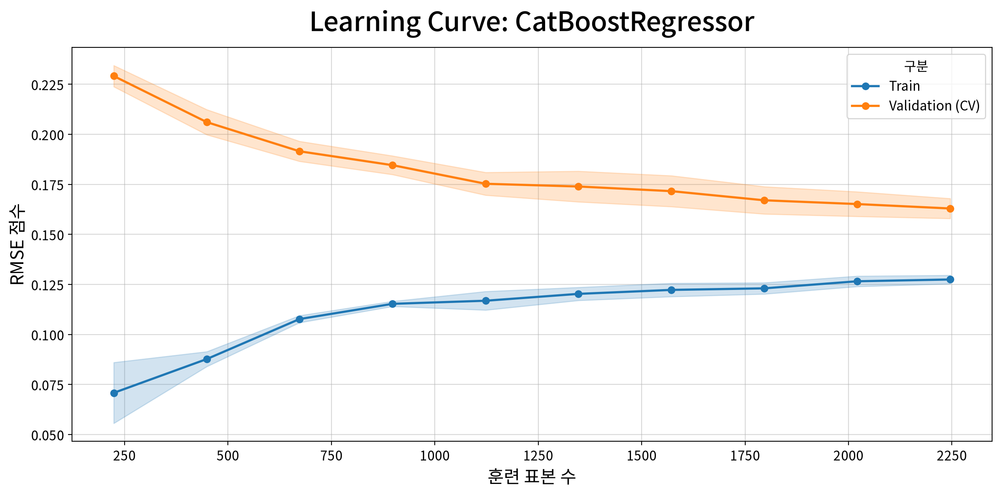

,Train,CV,CV_std,Test,Gap,Gap%,Overfit
Metric,,,,,,,
RMSE,0.130,0.162,0.005,0.168,0.032,19.900,일반화
MAE,0.098,0.120,0.004,0.120,0.022,18.310,일반화
R2,0.933,0.895,0.007,0.896,0.038,3.820,일반화



◆ Fit Diagnosis: CatBoostRegressor    (threshold=20%, 기준=Train↔CV 5-Fold)
    ※ threshold 는 학술 표준이 아닌 경험칙입니다  임계값보다 학습곡선 추세를 함께 보세요.
   - RMSE  : Train=     0.1299  CV=     0.1622 (±0.0049) Test=     0.1676  Gap%=   19.90%  [일반화] [정상]
   - MAE   : Train=     0.0982  CV=     0.1202 (±0.0036) Test=     0.1198  Gap%=   18.31%  [일반화] [정상]
   - R2    : Train=     0.9328  CV=     0.8946 (±0.0072) Test=     0.8960  Gap%=    3.82%  [일반화] [정상]

  ▶ 진단: ✓ 일반화 (Good fit) - 격차가 작고 훈련 성능도 양호
    · train R2=0.9328 (과소적합 기준 < 0.05) · CV R2=0.8946



In [174]:
tune_model = my_ml.load_model(f"{work_dir}/catboost_imp_tuned.pkl")
my_diag.overfit(tune_model, x_train=x_train_imp, y_train=y_train, x_test=x_test_imp, y_test=y_test)

**해석**

- 기존 `CatBoost`는 RMSE와 MAE의 격차 비율이 각각 **33.89%, 32.21%**로 과대적합 판정을 받았습니다. 변수를 줄여 다시 학습한 뒤에는 RMSE **6.27%**, MAE **5.84%**, 결정계수 **2.99%**로 모두 20% 미만이 되어 **세 지표 전부 일반화 판정**으로 바뀌었습니다. 결정계수도 기존 Train **0.9544** → CV **0.8952** → Test **0.8984**에서, 변수 축소 후 Train **0.7849** → CV **0.7550** → Test **0.7440**으로 변화하여 예측 성능은 낮아졌지만 훈련과 교차검증의 격차가 크게 줄어 과대적합이 완화되었습니다.

#### #SAHP 분석 수행

In [175]:
final_model = my_ml.load_model(f"manhattan_rent/importance/catboost_imp_tuned.pkl")
final_model

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step... verbose=0))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__depth': [4, 6, ...], 'model__iterations': [500, 1000, ...], 'model__learning_rate': [0.03, 0.05, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",

In [177]:
my_diag.shap_analysis("manhattan_rent", final_model, x_train)

SHAP 분석 결과 저장 완료 → manhattan_rent\shap\catboost_imp_tuned_shap.pkl


,mean_abs_shap,ratio,cum_ratio,mean_shap,std_shap,direction,cv,stability
Feature,,,,,,,,
size_neigh_ratio,0.235,0.401,0.401,0.003,0.302,증가,1.286,비선형/불안정
neighborhood,0.127,0.217,0.618,0.004,0.186,증가,1.465,비선형/불안정
bathrooms,0.075,0.128,0.746,-0.002,0.083,감소,1.107,비선형/불안정
building_age_yrs,0.050,0.086,0.831,-0.002,0.068,감소,1.358,비선형/불안정
bedrooms,0.044,0.075,0.906,-0.001,0.059,감소,1.346,비선형/불안정
floor_neigh_ratio,0.034,0.059,0.965,-0.001,0.043,감소,1.235,비선형/불안정
floor,0.021,0.035,1.000,0.002,0.026,증가,1.274,비선형/불안정


**해석**

- 근거(계산 결과): SHAP 분석 결과 `size_negh_ratio`가 전체 영향력의 **40.1%**로 가장 중요한 변수였으며, `neighborhood` 21.7%, `bathrooms` **12.8%** 순이었다. 사위 3개 변수만으로 누적 영향력 **74.6%**를 차지하여 모델의 예측이 일부 핵심 변수에 집중되어 있음을 알 수 있다. 또한 모든 변수의 변동계수가 1을 초과하여 개별 주택에 따라 영향의 크기와 방향이 달라지는 비선형적인 특징이 보인다.
누적 영향력 95%를 적용하면 `floor`를 제외한 6개 변수가 선택된다.
    - *direction=증가/감소* 는 평균 SHAP 부호에 따른 방향이므로, 단순 인과관계로 해석해서는 안된다. 평균적인 모델 기여 방향이 감소로 나타났다 라고 해석해야 한다.

### #폴더 지정

In [179]:
project_name = "manhattan_rent"

# shap 분석 결과가 저장되어 있는 폴더
shap_dir = f"{project_name}/shap"

# 저장되어 있는 분석 결과 목록 — 이 중 하나를 골라 불러온다
os.listdir(shap_dir)

['catboost_imp_tuned_shap.pkl']

#### #파라미터 정하기

In [180]:
cum_ratio = 0.95        # 채택・탈락을 가르는 누적 비율

if not 0.0 < cum_ratio <= 1.0:    # 0~1 범위를 벗어난 경우
    raise ValueError(f"cum_ratio 는 `0.0 ~ 1.0` 범위여야 합니다: {cum_ratio}")

##### 분석 결과 불러오기

In [181]:
# SHAP 분석 결과를 불러온다
summary = my_ml.load_model(f"{shap_dir}/catboost_imp_tuned_shap.pkl")

# pkl 파일에 저장되어 있는 SHAP 분석 결과를 확인한다
shap_2d = summary.attrs['shap_values']      # (n, f) 기여도 배열
x_df = summary.attrs['data']                # Beeswarm 의 점 색(변수값)
model_class = summary.attrs['model_class']  # 그래프 제목

print(f"모델: {model_class} / explainer: {summary.attrs['explainer_type']}")
print(f"설명 대상: {shap_2d.shape[0]}행 × {shap_2d.shape[1]}변수")
print(f"base value: {summary.attrs['expected_value']}")
print(f"SHAP 값의 단위: {summary.attrs['output_space']}")

summary

모델: CatBoostRegressor / explainer: TreeExplainer
설명 대상: 2808행 × 7변수
base value: 8.402039408735057
SHAP 값의 단위: 예측값(y 단위)


,mean_abs_shap,ratio,cum_ratio,mean_shap,std_shap,direction,cv,stability
Feature,,,,,,,,
size_neigh_ratio,0.235,0.401,0.401,0.003,0.302,증가,1.286,비선형/불안정
neighborhood,0.127,0.217,0.618,0.004,0.186,증가,1.465,비선형/불안정
bathrooms,0.075,0.128,0.746,-0.002,0.083,감소,1.107,비선형/불안정
building_age_yrs,0.050,0.086,0.831,-0.002,0.068,감소,1.358,비선형/불안정
bedrooms,0.044,0.075,0.906,-0.001,0.059,감소,1.346,비선형/불안정
floor_neigh_ratio,0.034,0.059,0.965,-0.001,0.043,감소,1.235,비선형/불안정
floor,0.021,0.035,1.000,0.002,0.026,증가,1.274,비선형/불안정


#### #컬럼명에 따른 의미 정의

In [182]:
column_means = {
    "size_neigh_ratio": "동네 평균 대비 집 크기",
    "neighborhood": "매물이 속한 세부 동네명",
    "bathrooms": "욕실 수(개)",
    "building_age_yrs": "건물 준공 후 경과 연수(년)",
    "bedrooms": "침실 수(개)",
    "floor_neigh_ratio": "동네 평균 대비 층",
    "floor": "매물이 위치한 층"
}

#### SHAP Bar Plot

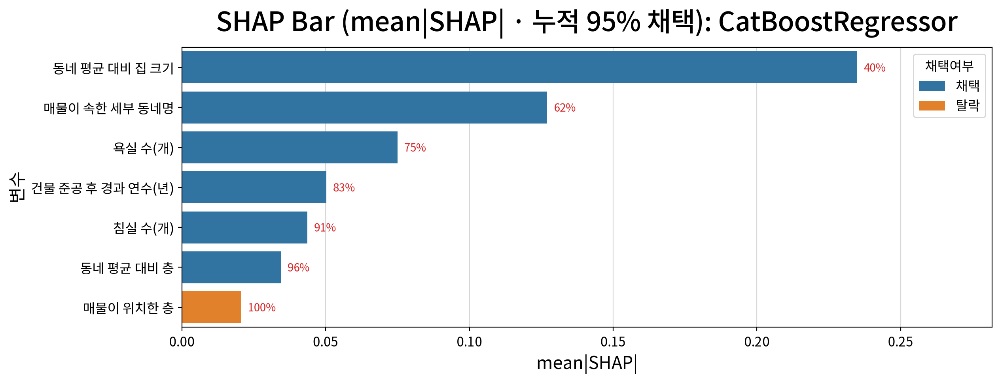

In [183]:
my_diag.shap_bar_plot(summary, cum_ratio=cum_ratio, column_means=column_means)

#### Summary Plot (Beeswarm Plot)

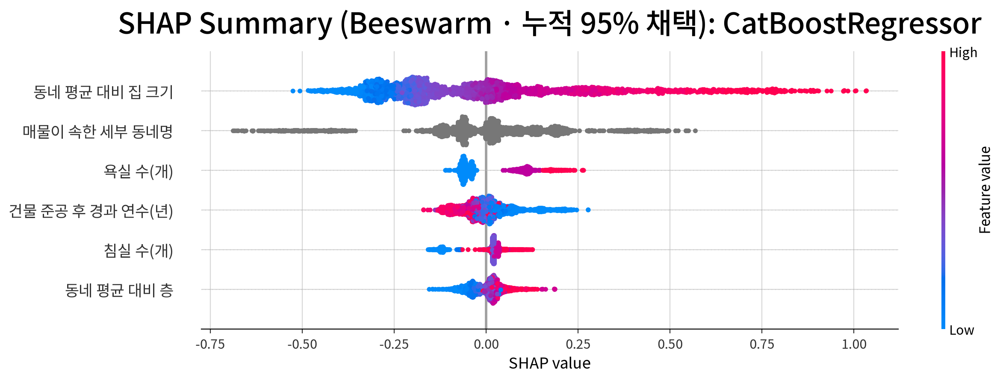

In [184]:
my_diag.shap_summary_plot(summary,
                          cum_ratio=cum_ratio,
                          column_means=column_means)

#### Dependence Plot

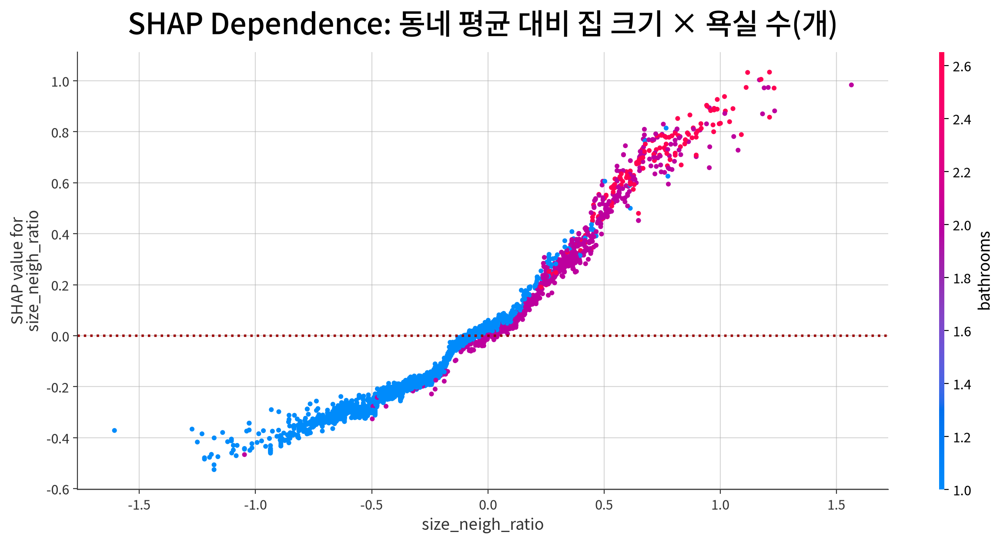

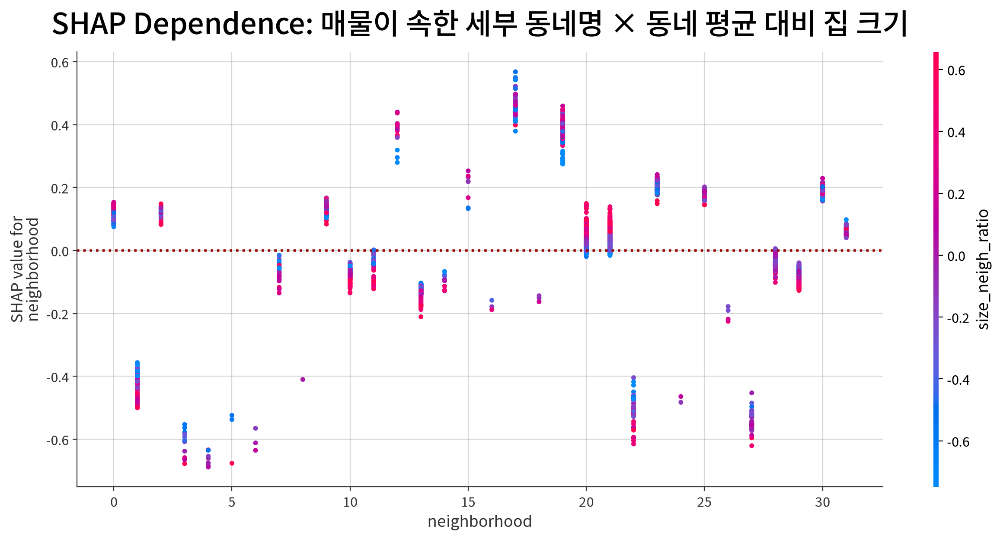

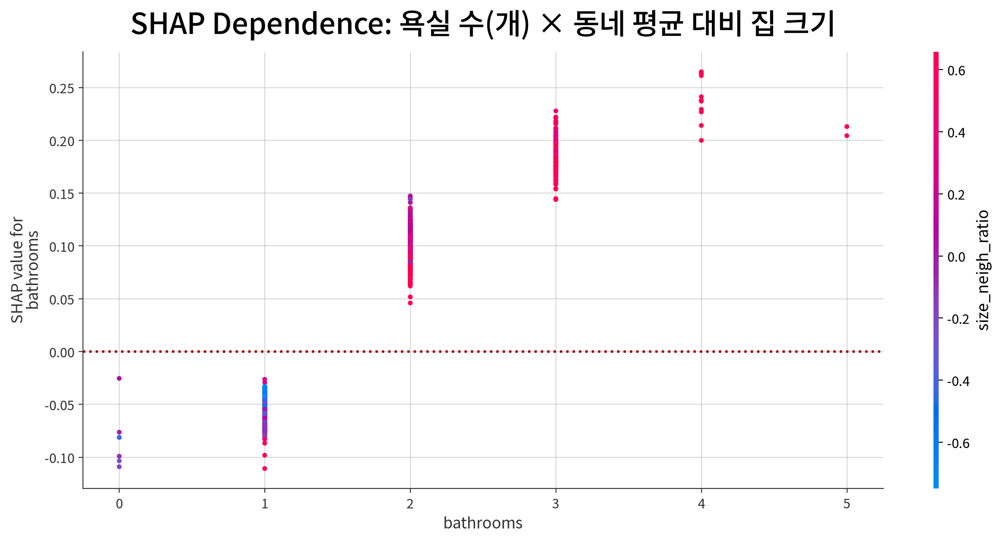

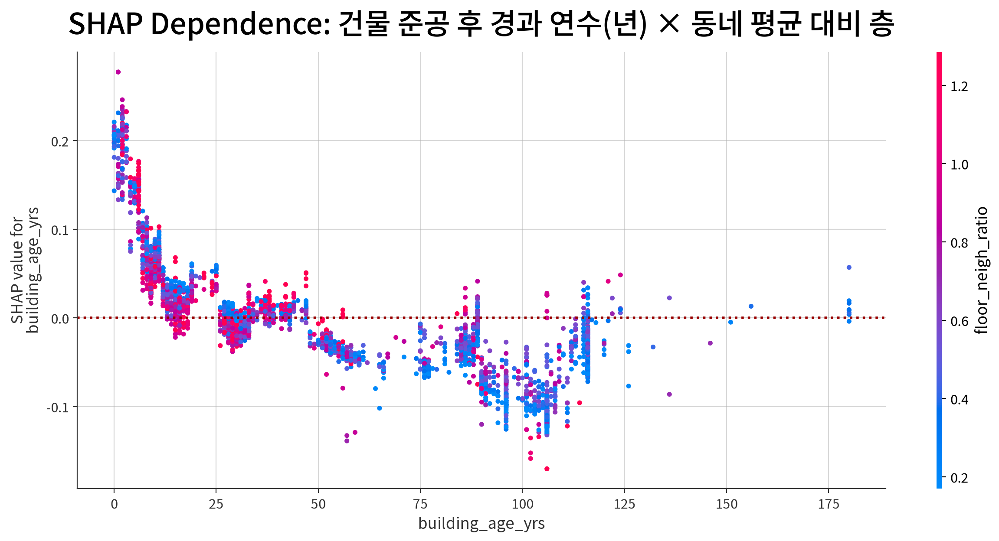

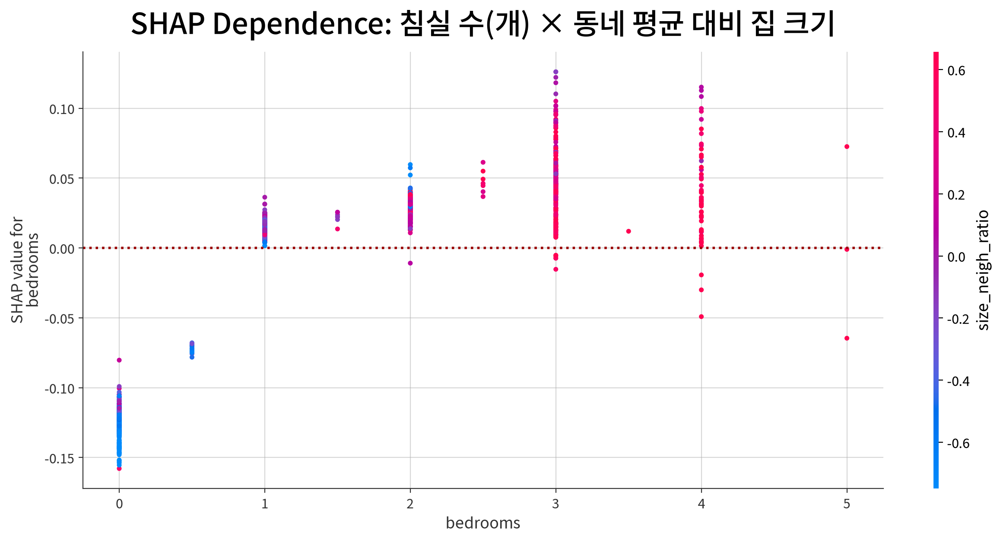

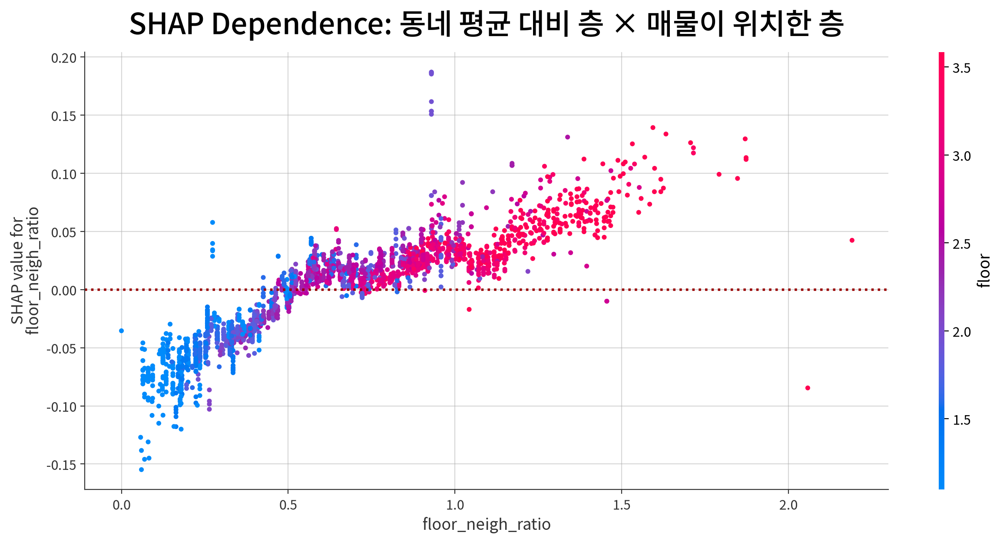

In [185]:
my_diag.shap_dependence_plot(summary, 
                             cum_ratio=cum_ratio, 
                             column_means=column_means)

#### 대표 통계량별 Waterfall Plot

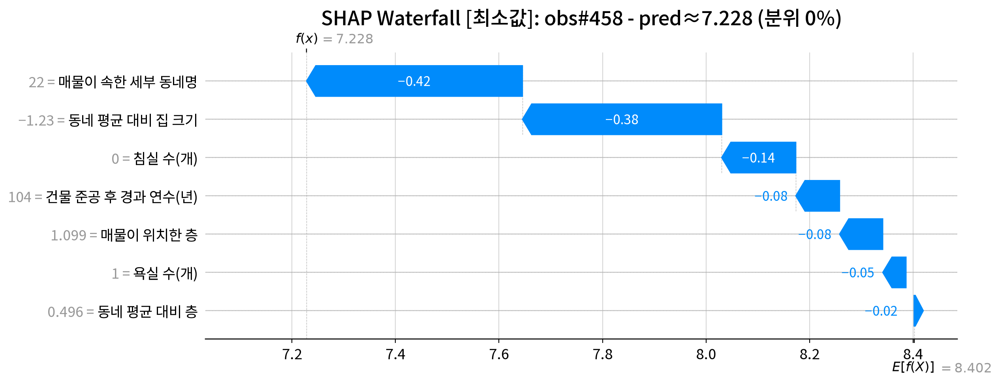

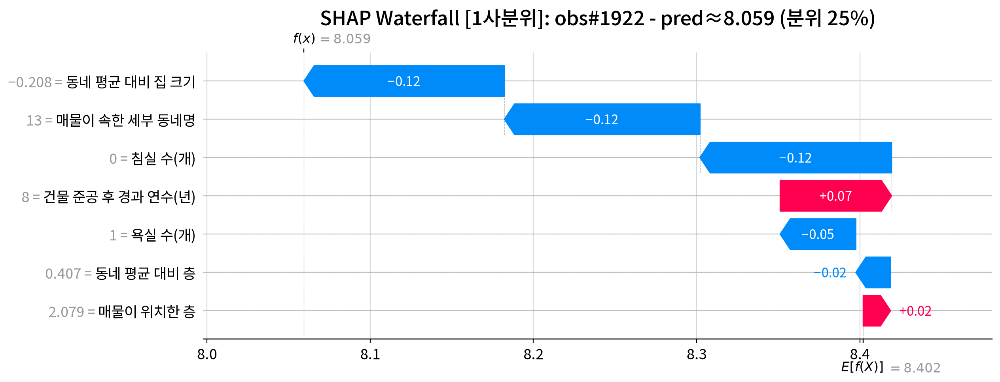

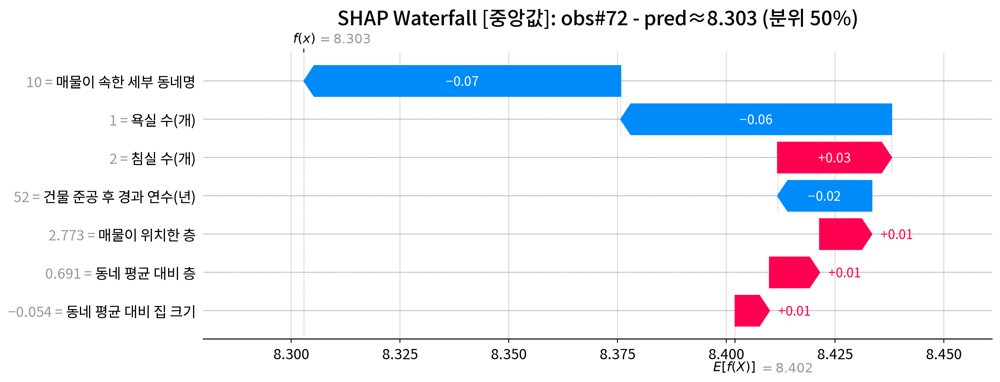

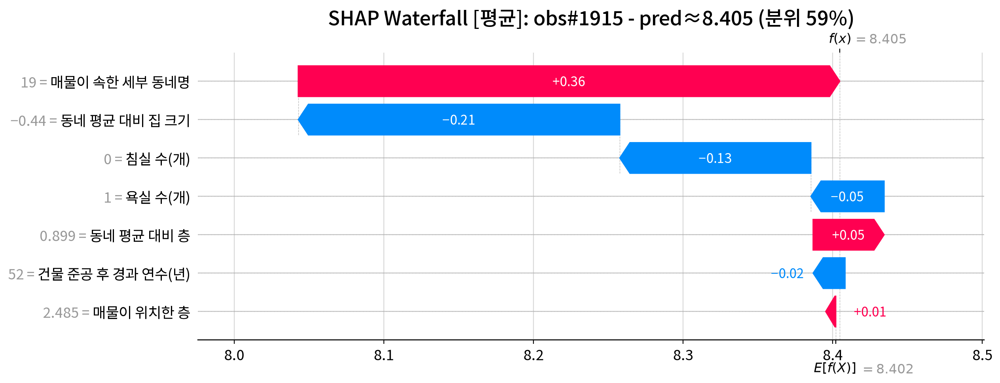

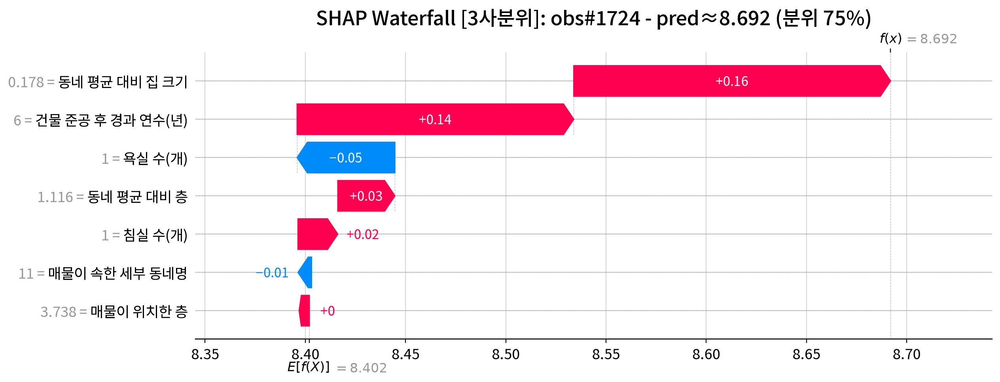

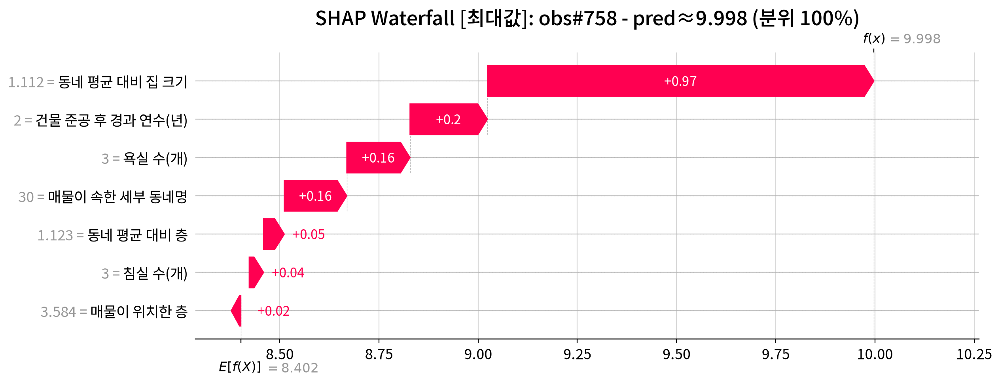

,stat,quantile,pred,size_neigh_ratio,bathrooms,building_age_yrs,bedrooms,floor_neigh_ratio,floor,neighborhood
2400,최소값,0.000,7.228,-1.230,1,104,0.000,0.496,1.099,22
155,1사분위,0.250,8.059,-0.208,1,8,0.000,0.407,2.079,13
2204,중앙값,0.500,8.303,-0.054,1,52,2.000,0.691,2.773,10
348,평균,0.589,8.405,-0.440,1,52,0.000,0.899,2.485,19
2474,3사분위,0.750,8.692,0.178,1,6,1.000,1.116,3.738,11
1453,최대값,1.000,9.998,1.112,3,2,3.000,1.123,3.584,30


In [186]:
my_diag.shap_waterfall_stats_plot(summary, cum_ratio=cum_ratio, column_means=column_means)